# Projeto 2 — Task 2: modelos estatísticos de previsão

**Mineração de Dados 2026/27 · Previsão *day-ahead* da procura de carregamento de veículos elétricos**

**Objetivo desta Task.** Selecionar, configurar e avaliar modelos estatísticos de séries temporais para prever o número de sessões que começam em cada uma das próximas 24 horas, ao nível da rede e de cada distrito, e compará-los com as *baselines* da Task 1 **usando exatamente o protocolo fixado na Task 1**.

**Estrutura**

0. Configuração e dados (artefactos da Task 1)
1. Motor de avaliação comum (interface dos modelos, métricas, verificação com as *baselines*)
2. Decisões transversais: janela de treino e transformação
3. Suavização exponencial (ETS, ETS semanal e MSTL + ETS)
4. Identificação ARIMA
5. SARIMA e MSTL + ARIMA
6. SARIMAX com variáveis exógenas
7. Comparação global
8. Discussão transversal
9. Síntese

**Regra de rigor.** Tudo o que se decide nesta Task usa **apenas os 4 *folds* de validação** (2020-Q4 a 2021-Q3). O teste final (2021-Q4) não é usado: o motor de avaliação recusa qualquer bloco que o toque.

## 0. Configuração e dados

O notebook lê os três ficheiros exportados pela Task 1 (`hourly_series_task1.csv`, `daily_weather_task1.csv` e `protocol_task1.json`). As partições, a data de início da escala do MASE e a *baseline* de referência vêm do JSON do protocolo, e não são reescritas aqui, para garantir que a Task 2 usa exatamente o mesmo enquadramento.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from joblib import Parallel, delayed
from scipy import stats
from statsmodels.tsa.exponential_smoothing.ets import ETSModel
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import acf
from statsmodels.stats.diagnostic import acorr_ljungbox

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
plt.rcParams.update({
    "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})

# Artefactos da Task 1: procurados na pasta do notebook e na pasta acima.
def find_file(name):
    for p in [Path(name), Path("..") / name, Path("../Parte2") / name]:
        if p.exists():
            return p
    raise FileNotFoundError(f"{name} não encontrado: corra primeiro o task1.ipynb (secção 6) para o gerar.")

SERIES_PATH, WEATHER_PATH, PROTOCOL_PATH = (find_file(n) for n in
    ["hourly_series_task1.csv", "daily_weather_task1.csv", "protocol_task1.json"])
OUT_DIR = Path("task2_outputs")
OUT_DIR.mkdir(exist_ok=True)

N_JOBS = -1  # processos em paralelo no motor de avaliação (-1 = todos os núcleos)

series = pd.read_csv(SERIES_PATH, index_col="hour", parse_dates=True)
weather_daily = pd.read_csv(WEATHER_PATH, parse_dates=["date", "known_at"])
PROTOCOL = json.loads(PROTOCOL_PATH.read_text(encoding="utf-8"))

LEVELS = PROTOCOL["series"]["levels"]
DISTRICTS = [lv for lv in LEVELS if lv != "Network"]
SERIES_START = pd.Timestamp(PROTOCOL["series"]["start"])
SERIES_END = pd.Timestamp(PROTOCOL["series"]["end"])
FOLDS = [{"name": f["name"], "train": tuple(f["train"]), "val": tuple(f["validation"])} for f in PROTOCOL["splits"]["folds"]]
TEST = tuple(PROTOCOL["splits"]["test"])
TEST_START = pd.Timestamp(TEST[0])
MASE_SCALE_FROM = pd.Timestamp(PROTOCOL["metrics"]["mase_scale_from"])
M_SEASON = PROTOCOL["metrics"]["mase_seasonal_period"]
REFERENCE = PROTOCOL["reference_baseline"]
HOLIDAY_DAYS = pd.DatetimeIndex([d for h in PROTOCOL["holidays"] for d in pd.date_range(h["from"], h["to"], freq="D")])

DAYS = pd.date_range(SERIES_START.normalize(), SERIES_END.normalize(), freq="D")
day_idx = lambda d: int((pd.Timestamp(d) - DAYS[0]).days)
hidx = lambda t: int((pd.Timestamp(t) - SERIES_START) / pd.Timedelta(hours=1))
Y = {lv: series[lv].to_numpy().astype(float) for lv in LEVELS}

assert len(series) == PROTOCOL["series"]["n_hours"] == len(DAYS) * 24
assert series.index[0] == SERIES_START and series.index.is_monotonic_increasing
assert (series[DISTRICTS].sum(axis=1) == series["Network"]).all()
assert M_SEASON == 24 and set(REFERENCE.values()) == {"MediaHora-7d"}

COLORS = {"Network": "#1F77B4", "Nanhu": "#2CA02C", "Tongxiang": "#FF7F0E", "Xiuzhou": "#9467BD"}
display(pd.DataFrame(
    [{"bloco": f["name"], "treino": f"{f['train'][0]} a {f['train'][1]}", "validação": f"{f['val'][0]} a {f['val'][1]}",
      "origens": day_idx(f["val"][1]) - day_idx(f["val"][0]) + 1} for f in FOLDS]
    + [{"bloco": "Teste (não usado)", "treino": "—", "validação": f"{TEST[0]} a {TEST[1]}", "origens": day_idx(TEST[1]) - day_idx(TEST[0]) + 1}]
).set_index("bloco"))
print("Escala do MASE desde:", MASE_SCALE_FROM.date(), "| período sazonal m =", M_SEASON, "| referência:", REFERENCE["Network"])

,treino,validação,origens
bloco,,,
F1,2020-01-01 a 2020-09-30,2020-10-01 a 2020-12-31,92
F2,2020-01-01 a 2020-12-31,2021-01-01 a 2021-03-31,90
F3,2020-01-01 a 2021-03-31,2021-04-01 a 2021-06-30,91
F4,2020-01-01 a 2021-06-30,2021-07-01 a 2021-09-30,92
Teste (não usado),—,2021-10-01 a 2021-12-31,92


Escala do MASE desde: 2020-04-01 | período sazonal m = 24 | referência: MediaHora-7d


**Protocolo herdado da Task 1 (resumo).**

| Elemento | Decisão |
|---|---|
| Emissão | diária às 00:00; horizontes $h=1,\dots,24$ = as 24 horas do dia $D$ |
| Informação | só a procura observada até $T_0-1\,$h (e calendário); nada do dia $D$ |
| Estratégia (estatísticos) | iterada: parâmetros estimados **uma vez por *fold***; em cada origem o estado é atualizado com os dados até $T_0$, **sem reestimar** |
| Validação | 4 *folds* trimestrais de janela expansiva; teste 2021-Q4 protegido |
| Métricas | MAE, RMSE, MASE ($m=24$, escala desde 2020-04-01), acerto e erro do pico, custo |
| Referência | MédiaHora-7d em todos os níveis |
| Regra de seleção | MASE médio menor, melhor em ≥ 3 de 4 *folds* e IC 95% da diferença pareada de MASE diário a excluir zero |

## 1. Motor de avaliação comum

Todos os modelos desta Task (e das seguintes) passam pelo **mesmo motor**, para serem comparados nas mesmas origens, com as mesmas métricas e sem fugas de informação.

### 1.1 Interface dos modelos

Cada modelo é uma classe com dois métodos:

- `fit(y_train)`: recebe a série desde 2020-01-01 até ao último instante do treino do *fold* e estima os parâmetros. É chamado **uma vez por *fold* e por nível**.
- `predict(y_hist)`: recebe a série **já cortada** em $T_0$ (termina na hora 23:00 do dia anterior) e devolve as 24 previsões do dia $D$. Pode atualizar o estado do modelo com esses dados, mas não reestima parâmetros.

Como o motor só entrega ao `predict` o histórico cortado, **um modelo não consegue ver o futuro por construção** (a mesma garantia das *baselines* da Task 1). O motor também recusa qualquer bloco que entre no teste.

As *baselines* da Task 1 são reescritas nesta interface (sem `fit`), o que permite verificar o motor: tem de reproduzir os números da Task 1.

In [2]:
class Forecaster:
    # Classe base: as subclasses implementam fit e predict.
    name = "base"
    level = None

    def fit(self, y_train):
        return self

    def predict(self, y_hist):
        raise NotImplementedError

    def info(self):
        # Informação extra a guardar por (nível, fold): parâmetros, AICc, etc.
        return {}


class Naive(Forecaster):
    def predict(self, y_hist): return np.full(24, y_hist[-1])

class SNaive24(Forecaster):
    def predict(self, y_hist): return y_hist[-24:].copy()

class SNaive168(Forecaster):
    def predict(self, y_hist): return y_hist[-168:-144].copy()

class MediaHora7d(Forecaster):
    def predict(self, y_hist): return y_hist[-168:].reshape(7, 24).mean(axis=0)

class MediaHora4sem(Forecaster):
    def predict(self, y_hist): return np.mean([y_hist[len(y_hist) - 168 * k: len(y_hist) - 168 * k + 24] for k in range(1, 5)], axis=0)

BASELINES = {"Naive": Naive, "SNaive-24": SNaive24, "SNaive-168": SNaive168,
             "MediaHora-7d": MediaHora7d, "MediaHora-4sem": MediaHora4sem}

In [3]:
def _run_one(make_model, level, fold):
    # Um nível × um fold: ajusta uma vez e prevê todas as origens do bloco de validação.
    y = Y[level]
    d0, d1 = day_idx(fold["val"][0]), day_idx(fold["val"][1])
    assert DAYS[d1] < TEST_START, "o motor não avalia blocos que entrem no teste"
    n_train = d0 * 24
    assert pd.Timestamp(fold["train"][1]) + pd.Timedelta(hours=23) == series.index[n_train - 1]
    model = make_model()
    model.level = level                           # contexto para modelos com exógenas por distrito
    t0 = time.perf_counter()
    model.fit(y[:n_train].copy())
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    fc = []
    for d in range(d0, d1 + 1):
        y_hist = y[:d * 24].copy()              # histórico cortado em T0 = 00:00 do dia d
        f = np.asarray(model.predict(y_hist), dtype=float)
        assert f.shape == (24,) and np.isfinite(f).all()
        fc.append(np.clip(f, 0, None))          # procura nunca negativa
    pred_s = (time.perf_counter() - t0) / (d1 - d0 + 1)
    return level, fold["name"], np.vstack(fc), fit_s, pred_s, model.info()


RESULTS = {}

def run_model(name, make_model, levels=LEVELS, folds=FOLDS, n_jobs=None, verbose=True):
    # Avalia um modelo em todos os níveis e folds, calcula as métricas e guarda em RESULTS[name].
    t0 = time.perf_counter()
    jobs = [(lv, f) for lv in levels for f in folds]
    out = Parallel(n_jobs=N_JOBS if n_jobs is None else n_jobs)(delayed(_run_one)(make_model, lv, f) for lv, f in jobs)
    RESULTS[name] = compute_metrics(name, out)
    if verbose:
        print(f"{name}: {len(jobs)} ajustes (nível × fold) em {time.perf_counter() - t0:.1f} s")
    return RESULTS[name]

### 1.2 Métricas e agregação

As métricas seguem a secção 5.2 da Task 1:

- **MAE** (erro absoluto médio, em sessões/hora) e **RMSE** (raiz do erro quadrático médio; castiga mais os erros grandes, como falhar um pico).
- **MASE** = MAE do modelo ÷ MAE *in-sample* do *seasonal naïve* de 24 h no treino de cada *fold* e nível (desde 2020-04-01). Abaixo de 1, o modelo erra menos do que "repetir o dia anterior" erraria no treino; permite comparar níveis com volumes muito diferentes.
- **Pico:** acerto da hora de pico do dia (±1 h) e erro absoluto do valor do pico.
- **Custo:** tempo de ajuste por *fold* e tempo de previsão por origem.

Agregação: MAE e RMSE globais sobre todas as origens de validação (o RMSE global é a raiz da média de todos os erros quadráticos); o MASE global é a média dos MASE dos *folds*, porque cada *fold* tem a sua escala. O MASE diário é guardado para a comparação pareada com a referência.

In [4]:
def mase_scale(level, fold):
    s0, n_train = hidx(MASE_SCALE_FROM), day_idx(fold["val"][0]) * 24
    y = Y[level]
    return np.abs(y[s0 + M_SEASON:n_train] - y[s0:n_train - M_SEASON]).mean()

SCALES = {(lv, f["name"]): mase_scale(lv, f) for lv in LEVELS for f in FOLDS}
FOLD_BY_NAME = {f["name"]: f for f in FOLDS}


def compute_metrics(name, out):
    by_h, by_fold, by_day, preds, info = [], [], [], [], []
    for level, fname, fc, fit_s, pred_s, inf in out:
        f = FOLD_BY_NAME[fname]
        d0, d1 = day_idx(f["val"][0]), day_idx(f["val"][1])
        act = Y[level][d0 * 24:(d1 + 1) * 24].reshape(-1, 24)
        err, scale = act - fc, SCALES[(level, fname)]
        mae_h, mse_h = np.abs(err).mean(axis=0), (err ** 2).mean(axis=0)
        for h in range(24):
            by_h.append((fname, level, name, h + 1, mae_h[h], np.sqrt(mse_h[h]), mae_h[h] / scale))
        for i, v in enumerate(np.abs(err).mean(axis=1) / scale):
            by_day.append((fname, level, name, DAYS[d0 + i], v))
        by_fold.append({
            "fold": fname, "level": level, "model": name,
            "MAE": mae_h.mean(), "RMSE": np.sqrt(mse_h.mean()), "MASE": mae_h.mean() / scale,
            "peak_hit": (np.abs(fc.argmax(1) - act.argmax(1)) <= 1).mean(),
            "peak_mae": np.abs(fc.max(1) - act.max(1)).mean(),
            "fit_s": fit_s, "ms_per_origin": pred_s * 1000, "n_origins": len(fc),
        })
        preds.append(pd.DataFrame({
            "model": name, "level": level, "fold": fname,
            "origin": np.repeat(DAYS[d0:d1 + 1], 24),
            "timestamp": series.index[d0 * 24:(d1 + 1) * 24],
            "h": np.tile(np.arange(1, 25), d1 - d0 + 1),
            "y_true": act.ravel(), "y_pred": fc.ravel(),
        }))
        info.append({"level": level, "fold": fname, **inf})
    return {
        "res_h": pd.DataFrame(by_h, columns=["fold", "level", "model", "horizon", "MAE", "RMSE", "MASE"]),
        "res_f": pd.DataFrame(by_fold),
        "res_d": pd.DataFrame(by_day, columns=["fold", "level", "model", "day", "MASE_dia"]),
        "preds": pd.concat(preds, ignore_index=True),
        "info": pd.DataFrame(info),
    }


def paired_ci(d, block=7, n_boot=2000, seed=0):
    # IC 95% da média de d por bootstrap de blocos de 7 dias (igual à Task 1).
    rng = np.random.default_rng(seed)
    n = len(d)
    k = -(-n // block)
    starts = rng.integers(0, n - block + 1, size=(n_boot, k))
    idx = (starts[:, :, None] + np.arange(block)).reshape(n_boot, -1)[:, :n]
    return np.percentile(d[idx].mean(axis=1), [2.5, 97.5])


def summarize(names, levels=LEVELS, with_rule=True):
    # Tabela por nível e modelo: métricas globais, estabilidade entre folds e regra de seleção face à referência.
    rows = []
    for name in names:
        rf, rd = RESULTS[name]["res_f"], RESULTS[name]["res_d"]
        for lv in levels:
            sub = rf[rf["level"] == lv]
            n = sub["n_origins"]
            row = {
                "level": lv, "model": name,
                "MAE": (sub["MAE"] * n).sum() / n.sum(),
                "RMSE": np.sqrt((sub["RMSE"] ** 2 * n).sum() / n.sum()),
                "MASE": sub["MASE"].mean(), "MASE_dp": sub["MASE"].std(), "MASE_pior": sub["MASE"].max(),
                "pico_acerto": sub["peak_hit"].mean(), "pico_MAE": sub["peak_mae"].mean(),
                "ajuste_s": sub["fit_s"].mean(), "ms_origem": sub["ms_per_origin"].mean(),
            }
            ref = REFERENCE[lv]
            if with_rule and name != ref and ref in RESULTS:
                rref = RESULTS[ref]
                ref_f = rref["res_f"][rref["res_f"]["level"] == lv].set_index("fold")["MASE"]
                wins = int((sub.set_index("fold")["MASE"] < ref_f).sum())
                a = rd[rd["level"] == lv].set_index("day")["MASE_dia"].sort_index()
                b = rref["res_d"][rref["res_d"]["level"] == lv].set_index("day")["MASE_dia"].sort_index()
                diff = (a - b).to_numpy()
                lo, hi = paired_ci(diff)
                row.update({"Δ_MASE_vs_ref": diff.mean(), "IC_inf": lo, "IC_sup": hi, "folds_ganhos": wins,
                            "melhor_que_ref": "sim" if (diff.mean() < 0 and wins >= 3 and hi < 0) else "não"})
            rows.append(row)
    return pd.DataFrame(rows)


def show_summary(names, levels=LEVELS, cols=None, sort="MASE"):
    tbl = summarize(names, levels)
    cols = cols or [c for c in tbl.columns if c not in ("level", "model")]
    for lv in levels:
        print(f"--- {lv} ---")
        display(tbl[tbl["level"] == lv].set_index("model")[cols].sort_values(sort).round(3))
    return tbl


def fold_table(names, metric="MASE"):
    rf = pd.concat([RESULTS[n]["res_f"] for n in names])
    return rf.pivot_table(index=["level", "model"], columns="fold", values=metric).reindex(LEVELS, level=0)


def plot_by_horizon(names, metric="MASE", title=None, styles=None):
    fig, axes = plt.subplots(1, 4, figsize=(16, 3.6), sharex=True)
    for ax, lv in zip(axes, LEVELS):
        for n in names:
            rh = RESULTS[n]["res_h"]
            v = rh[rh["level"] == lv].groupby("horizon")[metric].mean()
            ax.plot(v.index, v.values, label=n, **(styles or {}).get(n, {}))
        ax.set(title=lv, xlabel="horizonte h (= hora do dia + 1)", ylabel=metric if lv == "Network" else "")
        ax.set_xticks([1, 6, 12, 18, 24])
    axes[0].legend(fontsize=7)
    if title:
        fig.suptitle(title, y=1.02)
    plt.tight_layout()
    plt.show()

### 1.3 Verificação do motor: reproduzir as *baselines* da Task 1

Se o motor estiver correto, as cinco *baselines* têm de dar **exatamente** os valores da secção 5.3 da Task 1 (por exemplo, MASE da MédiaHora-7d: Rede 0,825, Nanhu 0,639, Tongxiang 0,834, Xiuzhou 0,890).

In [5]:
for name, cls in BASELINES.items():
    run_model(name, cls, verbose=False)

TASK1_REF_MASE = {"Network": 0.825, "Nanhu": 0.639, "Tongxiang": 0.834, "Xiuzhou": 0.890}
base_tbl = summarize(list(BASELINES), with_rule=False)
check = base_tbl[base_tbl["model"] == "MediaHora-7d"].set_index("level")["MASE"]
for lv, v in TASK1_REF_MASE.items():
    assert abs(check[lv] - v) < 5e-4, (lv, check[lv], v)
print("Motor verificado: a MédiaHora-7d reproduz os MASE da Task 1 em todos os níveis.")
display(base_tbl.pivot(index="model", columns="level", values="MASE")[LEVELS].sort_values("Network").round(3))

Motor verificado: a MédiaHora-7d reproduz os MASE da Task 1 em todos os níveis.


level,Network,Nanhu,Tongxiang,Xiuzhou
model,,,,
MediaHora-7d,0.825,0.639,0.834,0.890
MediaHora-4sem,0.916,0.694,0.925,0.940
SNaive-24,1.022,0.814,1.032,1.130
SNaive-168,1.095,0.824,1.110,1.159
Naive,2.149,1.115,1.857,1.682


**Leitura.** O motor reproduz os valores da Task 1 nos quatro níveis (as asserções passam), por isso as previsões, a escala do MASE e a agregação estão alinhadas com o protocolo. A partir daqui, qualquer modelo avaliado neste motor é diretamente comparável com as *baselines*, e **a referência a bater continua a ser a MédiaHora-7d**.

## 2. Decisões transversais: janela de treino e transformação

A Task 1 deixou duas decisões em aberto, que afetam todos os modelos estatísticos desta Task (ETS, ARIMA e SARIMAX). Tomam-se aqui, **uma vez**, com um modelo simples e barato, e ficam fixas para as secções seguintes:

1. **Transformação da série:** modelar a procura tal como está ou depois de `log1p`?
2. **Janela de treino:** a partir de quando se estimam os parâmetros, dado o colapso de janeiro-março de 2020?

O modelo usado como instrumento é o **ETS(A,N,A)** (Holt-Winters aditivo sem tendência, sazonalidade de 24 h; ver secção 3), o mais simples que capta o ciclo diário. A decisão é tomada com o mesmo critério do protocolo: MASE nos 4 *folds* de validação.

### 2.1 Porque considerar uma transformação?

Nas contagens, o erro tende a crescer com o nível da procura (a Task 1 viu-o nos resíduos da MSTL). Um modelo aditivo assume uma variação de tamanho constante, o que não se ajusta a esse comportamento. A transformação `log1p` ($z = \ln(1 + y)$) comprime os valores altos: um mesmo aumento percentual passa a ter sempre o mesmo tamanho, e a sazonalidade multiplicativa torna-se aditiva (como no exemplo AirPassengers das aulas). Usa-se $\ln(1+y)$ em vez de $\ln(y)$ porque há horas com zero sessões (20% em Nanhu), onde $\ln(0)$ não existe. A previsão volta à escala original com $y = e^{z} - 1$.

O gráfico verifica a premissa sem usar nenhum modelo: agrupa as horas do desenvolvimento (desde 2020-04-01) pelo nível esperado (a MédiaHora-7d dessa hora) e mostra o tamanho médio da variação face a esse nível, na escala original e na escala `log1p`.

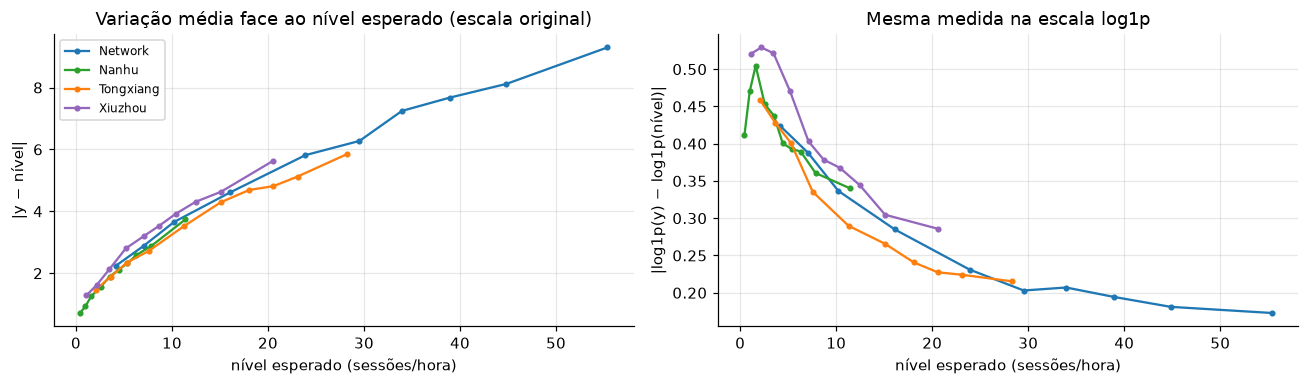

,escala original: decil mais alto ÷ mediano,escala log1p: decil mais alto ÷ mediano
nível,,
Network,1.480,0.850
Nanhu,1.770,0.850
Tongxiang,1.360,0.810
Xiuzhou,1.590,0.760


In [6]:
dev_from, dev_to = hidx(MASE_SCALE_FROM) + 168, hidx(TEST_START)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
het_rows = []
for lv in LEVELS:
    y = Y[lv]
    # nível esperado de cada hora = média da mesma hora nos 7 dias anteriores (só passado)
    lvl = np.array([y[t - 168:t:24].mean() for t in range(dev_from, dev_to)])
    obs = y[dev_from:dev_to]
    bins = pd.qcut(lvl, 10, duplicates="drop")
    raw = pd.Series(np.abs(obs - lvl)).groupby(bins, observed=True).mean()
    log = pd.Series(np.abs(np.log1p(obs) - np.log1p(lvl))).groupby(bins, observed=True).mean()
    centers = pd.Series(lvl).groupby(bins, observed=True).mean()
    ax[0].plot(centers.values, raw.values, marker="o", ms=3, color=COLORS[lv], label=lv)
    ax[1].plot(centers.values, log.values, marker="o", ms=3, color=COLORS[lv], label=lv)
    hi_lo = lambda s: s.iloc[-1] / s.iloc[len(s) // 2]
    het_rows.append({"nível": lv, "escala original: decil mais alto ÷ mediano": hi_lo(raw), "escala log1p: decil mais alto ÷ mediano": hi_lo(log)})
ax[0].set(title="Variação média face ao nível esperado (escala original)", xlabel="nível esperado (sessões/hora)", ylabel="|y − nível|")
ax[1].set(title="Mesma medida na escala log1p", xlabel="nível esperado (sessões/hora)", ylabel="|log1p(y) − log1p(nível)|")
ax[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.DataFrame(het_rows).set_index("nível").round(2))

**Leitura.**

- **Escala original (esquerda):** a variação cresce de forma quase linear com o nível esperado. Nas horas mais movimentadas, é 1,4 a 1,8 vezes maior do que nas horas de procura mediana. É a heterocedasticidade que um modelo aditivo não representa: o modelo trataria igualmente um desvio de 5 sessões às 4h (enorme) e às 15h (normal).
- **Escala `log1p` (direita):** a relação inverte-se e fica muito mais plana nas horas com procura. O decil mais alto passa a ter 0,76 a 0,85 vezes a variação do decil mediano. Nas horas de procura muito baixa (noite, Nanhu), o `log1p` exagera ligeiramente a variação, porque com contagens de 0 a 3 sessões qualquer diferença de uma sessão é grande em termos relativos.

**Implicação:** o `log1p` não torna a variância perfeitamente constante, mas aproxima-a muito mais do que a escala original. A escolha final é empírica e faz-se na experiência seguinte.

### 2.2 Experiência: janela de treino × transformação

Combinam-se três janelas com as duas escalas (6 configurações × 4 níveis × 4 *folds*):

| Janela | Treino usado para estimar os parâmetros | Argumento |
|---|---|---|
| **completa** | desde 2020-01-01 (inclui o colapso) | mais dados |
| **regular** | desde 2020-04-01 | exclui um regime que não se repete (COVID-19 e Festival da Primavera de 2020) |
| **deslizante-12sem** | só as 12 semanas anteriores ao *fold* | adapta-se a mudanças de nível, mas com menos dados |

Em todas, os parâmetros são estimados uma vez por *fold* e o estado é atualizado diariamente com os dados até $T_0$. A janela define também onde começa essa atualização (o estado inicial é estimado no início da janela).

In [7]:
TRANSFORMS = {"nenhuma": (lambda y: y, lambda z: z), "log1p": (np.log1p, np.expm1)}
WINDOW_START = {
    "completa": lambda n_train: 0,
    "regular": lambda n_train: hidx("2020-04-01"),
    "deslizante-12sem": lambda n_train: n_train - 12 * 168,
}


class ETSForecaster(Forecaster):
    # ETS com erro aditivo. trend: None/"add"; damped: tendência amortecida; m: período sazonal (24 ou 168); seasonal: "add" ou None.
    def __init__(self, trend=None, damped=False, seasonal="add", m=24, window="regular", transform="log1p", bias_adj=False):
        self.trend, self.damped, self.seasonal, self.m = trend, damped, seasonal, m
        self.window, self.transform, self.bias_adj = window, transform, bias_adj

    def _model(self, z):
        return ETSModel(z, error="add", trend=self.trend, damped_trend=self.damped, seasonal=self.seasonal,
                        seasonal_periods=self.m if self.seasonal else None, initialization_method="heuristic")

    def fit(self, y_train):
        fwd, _ = TRANSFORMS[self.transform]
        self.s0 = WINDOW_START[self.window](len(y_train))
        self.res_ = self._model(fwd(y_train[self.s0:])).fit(disp=False, maxiter=1000)
        self.params = self.res_.params
        self.sigma2 = float(np.var(self.res_.resid))
        return self

    def predict(self, y_hist):
        fwd, inv = TRANSFORMS[self.transform]
        f = self._model(fwd(y_hist[self.s0:])).smooth(self.params).forecast(24)
        if self.transform == "log1p" and self.bias_adj:
            return np.exp(f + self.sigma2 / 2) - 1   # média em vez de mediana na escala original
        return inv(f)

    def info(self):
        names = self.res_.model.param_names
        return {**dict(zip(names, self.params)), "AICc": self.res_.aicc, "inicio_janela": str(series.index[self.s0].date())}


cfg_names = []
for w in WINDOW_START:
    for t in TRANSFORMS:
        nm = f"ETS(A,N,A) | {w} | {t}"
        run_model(nm, lambda w=w, t=t: ETSForecaster(window=w, transform=t))
        cfg_names.append(nm)

ETS(A,N,A) | completa | nenhuma: 16 ajustes (nível × fold) em 3.3 s


ETS(A,N,A) | completa | log1p: 16 ajustes (nível × fold) em 2.1 s


ETS(A,N,A) | regular | nenhuma: 16 ajustes (nível × fold) em 1.7 s


ETS(A,N,A) | regular | log1p: 16 ajustes (nível × fold) em 1.7 s


ETS(A,N,A) | deslizante-12sem | nenhuma: 16 ajustes (nível × fold) em 0.5 s


ETS(A,N,A) | deslizante-12sem | log1p: 16 ajustes (nível × fold) em 0.5 s


MASE médio nos 4 folds (menor é melhor)


level                           Network  Nanhu  Tongxiang  Xiuzhou  média dos níveis
janela           transformação                                                      
regular          log1p            0.783  0.616      0.784    0.841             0.756
deslizante-12sem log1p            0.783  0.619      0.785    0.840             0.757
completa         log1p            0.784  0.616      0.787    0.843             0.758
                 nenhuma          0.834  0.627      0.823    0.865             0.787
regular          nenhuma          0.840  0.629      0.825    0.865             0.790
deslizante-12sem nenhuma          0.839  0.637      0.825    0.862             0.791

MASE por fold (Rede)


fold,F1,F2,F3,F4
model,,,,
"ETS(A,N,A) | completa | log1p",0.799,0.657,0.791,0.889
"ETS(A,N,A) | completa | nenhuma",0.843,0.717,0.835,0.942
"ETS(A,N,A) | deslizante-12sem | log1p",0.798,0.656,0.789,0.890
"ETS(A,N,A) | deslizante-12sem | nenhuma",0.859,0.742,0.824,0.930
"ETS(A,N,A) | regular | log1p",0.798,0.656,0.789,0.890
"ETS(A,N,A) | regular | nenhuma",0.852,0.725,0.837,0.945


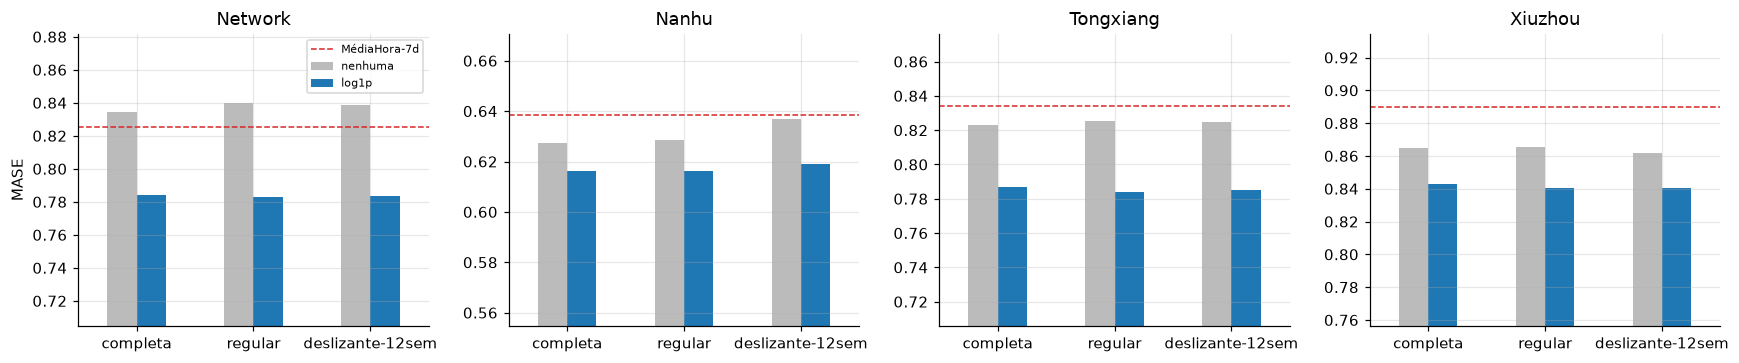

In [8]:
cfg = summarize(cfg_names, with_rule=False)
cfg[["modelo", "janela", "transformação"]] = cfg["model"].str.split(r" \| ", expand=True)
mase_cfg = cfg.pivot_table(index=["janela", "transformação"], columns="level", values="MASE")[LEVELS]
mase_cfg["média dos níveis"] = mase_cfg.mean(axis=1)
print("MASE médio nos 4 folds (menor é melhor)")
display(mase_cfg.sort_values("média dos níveis").round(3))

ft = fold_table(cfg_names).round(3)
print("MASE por fold (Rede)")
display(ft.loc["Network"])

fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharey=False)
for a, lv in zip(ax, LEVELS):
    sub = cfg[cfg["level"] == lv]
    piv = sub.pivot(index="janela", columns="transformação", values="MASE").loc[list(WINDOW_START), ["nenhuma", "log1p"]]
    piv.plot.bar(ax=a, rot=0, color=["#BBBBBB", "#1F77B4"], legend=(lv == "Network"))
    ref = summarize(["MediaHora-7d"], [lv], with_rule=False)["MASE"].iloc[0]
    a.axhline(ref, color="#D62728", ls="--", lw=1, label="MédiaHora-7d")
    a.set(title=lv, xlabel="", ylabel="MASE" if lv == "Network" else "")
    a.set_ylim(min(piv.min().min(), ref) * 0.9, max(piv.max().max(), ref) * 1.05)
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Leitura.**

- **A transformação é a decisão que conta.** Com `log1p`, o MASE médio baixa em **todos os níveis e em todas as janelas** (na Rede, 0,783 contra 0,834 a 0,840), e o ganho repete-se em 46 dos 48 pares nível × janela × *fold*. As duas exceções são Nanhu no F4, com as janelas regular e deslizante, por diferenças mínimas (0,003 e 0,006). Sem transformação, o ETS nem sequer bate a MédiaHora-7d na Rede (linha tracejada no gráfico).
- **A janela quase não importa.** Com `log1p`, as três janelas ficam separadas por menos de 0,003 de MASE médio (0,756 a 0,758). Há uma razão simples: com $\alpha$ entre 0,02 e 0,06 por hora (secção 3.2), o nível "esquece" o passado em um a dois dias. O estado inicial no colapso de 2020 é rapidamente ultrapassado, e os parâmetros estimados com as três janelas são muito parecidos.
- **Escolhe-se a janela regular (desde 2020-04-01).** É a que tem o MASE médio mais baixo, embora por margem mínima, e é coerente com a Task 1: exclui o regime de COVID-19, que não se repete, e é o mesmo início usado na escala do MASE. A janela deslizante dá o mesmo resultado com muito menos dados, o que a torna menos robusta para modelos com mais parâmetros (ARIMA, SARIMAX).

**Implicação:** todas as secções seguintes modelam a série em **`log1p`**, com parâmetros estimados **desde 2020-04-01**.

### 2.3 Voltar à escala original: mediana ou média?

Ao calcular $e^{\hat z} - 1$ obtém-se a **mediana** prevista, que fica ligeiramente abaixo da **média** (porque a exponencial "estica" mais os valores altos do que os baixos). A correção habitual soma metade da variância dos resíduos antes de voltar à escala original: $\hat y = e^{\hat z + \sigma^2/2} - 1$.

Qual das duas convém depende da métrica: **a mediana minimiza o MAE** e **a média minimiza o RMSE**. Testa-se a correção na configuração escolhida, só como verificação.

In [9]:
regularINDOW, log1pRANSFORM = "regular", "log1p"
base_name = f"ETS(A,N,A) | {regularINDOW} | {log1pRANSFORM}"
run_model("ETS(A,N,A) | log1p + correção", lambda: ETSForecaster(window=regularINDOW, transform="log1p", bias_adj=True))
bias_tbl = summarize([base_name, "ETS(A,N,A) | log1p + correção"], with_rule=False)
bias_tbl["previsão"] = bias_tbl["model"].map({base_name: "mediana (sem correção)", "ETS(A,N,A) | log1p + correção": "média (com correção)"})
display(bias_tbl.pivot_table(index="level", columns="previsão", values=["MAE", "RMSE", "MASE"]).reindex(LEVELS).round(3))

p = RESULTS[base_name]["preds"]
bias_by_level = (p["y_pred"] - p["y_true"]).groupby(p["level"]).mean().reindex(LEVELS)
p2 = RESULTS["ETS(A,N,A) | log1p + correção"]["preds"]
display(pd.DataFrame({"viés médio sem correção (prev. − real)": bias_by_level,
                      "viés médio com correção": (p2["y_pred"] - p2["y_true"]).groupby(p2["level"]).mean().reindex(LEVELS)}).round(3))

ETS(A,N,A) | log1p + correção: 16 ajustes (nível × fold) em 1.7 s


MAE                                        MASE                                        RMSE                     
previsão  mediana (sem correção) média (com correção) mediana (sem correção) média (com correção) mediana (sem correção) média (com correção)
level                                                                                                                                        
Network                    5.476                5.617                  0.783                0.803                  7.622                7.744
Nanhu                      1.720                1.765                  0.616                0.632                  2.524                2.505
Tongxiang                  3.452                3.548                  0.784                0.806                  4.802                4.873
Xiuzhou                    3.247                3.371                  0.841                0.873                  4.611                4.638

,viés médio sem correção (prev. − real),viés médio com correção
level,,
Network,-0.760,0.775
Nanhu,-0.461,0.148
Tongxiang,-0.594,0.550
Xiuzhou,-0.841,0.467


**Leitura.**

- **Sem correção, a previsão fica um pouco abaixo do real:** em média −0,8 sessões/hora na Rede e −0,5 a −0,8 nos distritos. É o efeito esperado de prever a mediana.
- **A correção troca o sinal do viés** (passa a sobrestimar entre +0,1 e +0,8 sessões/hora) e **piora o MAE e o MASE em todos os níveis** (por exemplo, MASE na Rede de 0,783 para 0,803). Também não melhora o RMSE, exceto em Nanhu, por uma margem desprezável.

**Decisão:** mantém-se a **mediana** (sem correção), porque o MASE e o MAE são as métricas principais do protocolo. Fica registado que as previsões subestimam ligeiramente o volume total, o que importa se forem usadas para dimensionar capacidade.

In [10]:
TASK2_DECISIONS = {
    "window": regularINDOW,
    "window_start_rule": {"completa": "2020-01-01", "regular": "2020-04-01", "deslizante-12sem": "12 semanas antes do fim do treino"}[regularINDOW],
    "transform": log1pRANSFORM,
    "back_transform": "mediana: expm1 da previsão em log1p, sem correção de enviesamento",
    "parameters": "estimados uma vez por fold e nível; estado atualizado diariamente com os dados até T0, sem reestimar",
    "negative_forecasts": "cortadas a 0",
}
(OUT_DIR / "task2_decisions.json").write_text(json.dumps(TASK2_DECISIONS, indent=2, ensure_ascii=False), encoding="utf-8")
display(pd.Series(TASK2_DECISIONS).to_frame("decisão fixada para as secções seguintes"))

,decisão fixada para as secções seguintes
window,regular
window_start_rule,2020-04-01
transform,log1p
back_transform,"mediana: expm1 da previsão em log1p, sem corre..."
parameters,estimados uma vez por fold e nível; estado atu...
negative_forecasts,cortadas a 0


## 3. Suavização exponencial (ETS)

### 3.1 Ideia base

A suavização exponencial prevê com uma **média ponderada do passado em que os dados mais recentes pesam mais**, e os pesos caem de forma exponencial. O enquadramento **ETS (Error, Trend, Seasonal)** descreve cada modelo pelas suas componentes, cada uma atualizada a cada hora:

| Componente | O que representa | Parâmetro (0 a 1) |
|---|---|---|
| Nível $\ell_t$ | quantas sessões há "agora", em média | $\alpha$: rapidez com que o nível reage |
| Tendência $b_t$ | quanto o nível sobe ou desce por hora | $\beta$ |
| Sazonalidade $s_t$ | o desvio típico de cada hora do dia face ao nível | $\gamma$ |
| Amortecimento $\phi$ | trava a tendência à medida que o horizonte cresce | $\phi<1$ |

Para o modelo aditivo com tendência amortecida, ETS(A,Ad,A), a previsão para $h$ horas à frente é:

$$\hat y_{T+h|T} = \ell_T + (\phi + \phi^2 + \dots + \phi^h)\, b_T + s_{T+h-m(k+1)}$$

O ETS(A,N,A) é o mesmo sem tendência, e o ETS(A,A,A) é o Holt-Winters com tendência não amortecida ($\phi=1$). Como a série é modelada em `log1p`, a estrutura aditiva na escala logarítmica corresponde a uma estrutura **multiplicativa** na escala original (a sazonalidade cresce com o nível), sem os problemas dos modelos M com horas a zero.

**O que estes modelos captam e o que não captam:**

- **Captam** a dependência temporal (o nível acompanha a procura recente), a tendência (se existir) e **um** ciclo sazonal.
- **Não captam** um segundo ciclo (o semanal, de 168 h), os feriados, nem variáveis externas. As secções 3.3 e 6 tratam estes pontos.

Os parâmetros $\alpha, \beta, \gamma, \phi$ são estimados por máxima verosimilhança no treino de cada *fold*; os estados iniciais são obtidos por heurística (médias dos primeiros ciclos), o que torna o ajuste muito rápido.

### 3.2 Variantes com sazonalidade diária ($m=24$)

Comparam-se três estruturas de tendência, todas com a janela e a transformação fixadas na secção 2:

- **ETS(A,N,A)**: sem tendência (já avaliado na secção 2).
- **ETS(A,A,A)**: Holt-Winters aditivo, tendência linear.
- **ETS(A,Ad,A)**: tendência amortecida, mais prudente.

Dentro de cada *fold*, os modelos são ajustados aos mesmos dados, por isso o **AICc** (menor é melhor) também permite compará-los. O AICc mede o ajuste ao treino penalizando o número de parâmetros; a validação mede a previsão fora da amostra, que é o critério decisivo.

In [11]:
ETS_VARIANTS = {
    "ETS(A,N,A)": dict(trend=None, damped=False),
    "ETS(A,A,A)": dict(trend="add", damped=False),
    "ETS(A,Ad,A)": dict(trend="add", damped=True),
}
for nm, kw in ETS_VARIANTS.items():
    run_model(nm, lambda kw=kw: ETSForecaster(window=regularINDOW, transform=log1pRANSFORM, **kw))

# AICc no treino (mesmos dados dentro de cada fold e nível)
aicc = pd.concat([RESULTS[n]["info"].assign(model=n) for n in ETS_VARIANTS])
aicc_tbl = aicc.pivot_table(index=["level", "fold"], columns="model", values="AICc")[list(ETS_VARIANTS)]
aicc_tbl["menor AICc"] = aicc_tbl.idxmin(axis=1)
print("AICc no treino de cada fold (escala log1p; menor é melhor)")
display(aicc_tbl.reindex(LEVELS, level=0).round(0))

par_cols = ["smoothing_level", "smoothing_trend", "smoothing_seasonal", "damping_trend"]
par = aicc[["model", "level", "fold"] + [c for c in par_cols if c in aicc]].rename(
    columns={"smoothing_level": "α", "smoothing_trend": "β", "smoothing_seasonal": "γ", "damping_trend": "φ"})
print("Parâmetros estimados (média e intervalo entre folds)")
display(par.groupby(["model", "level"])[["α", "β", "γ", "φ"]].agg(["mean", "min", "max"]).reindex(LEVELS, level=1).round(3))

show_summary(list(ETS_VARIANTS), cols=["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "Δ_MASE_vs_ref", "IC_inf", "IC_sup", "folds_ganhos", "melhor_que_ref"]);

ETS(A,N,A): 16 ajustes (nível × fold) em 1.8 s


ETS(A,A,A): 16 ajustes (nível × fold) em 2.8 s


ETS(A,Ad,A): 16 ajustes (nível × fold) em 4.3 s
AICc no treino de cada fold (escala log1p; menor é melhor)


model           ETS(A,N,A)  ETS(A,A,A)  ETS(A,Ad,A)  menor AICc
level     fold                                                 
Network   F1     2,530.000   2,561.000    2,534.000  ETS(A,N,A)
          F2     3,850.000   3,883.000    3,854.000  ETS(A,N,A)
          F3     5,880.000   5,920.000    5,884.000  ETS(A,N,A)
          F4     7,350.000   7,395.000    7,354.000  ETS(A,N,A)
Nanhu     F1     6,636.000   6,691.000    6,640.000  ETS(A,N,A)
          F2     9,791.000   9,848.000    9,795.000  ETS(A,N,A)
          F3    12,979.000  13,054.000   12,983.000  ETS(A,N,A)
          F4    16,093.000  16,183.000   16,097.000  ETS(A,N,A)
Tongxiang F1     4,320.000   4,335.000    4,323.000  ETS(A,N,A)
          F2     6,299.000   6,316.000    6,302.000  ETS(A,N,A)
          F3     8,616.000   8,637.000    8,620.000  ETS(A,N,A)
          F4    10,715.000  10,740.000   10,718.000  ETS(A,N,A)
Xiuzhou   F1     6,404.000   6,449.000    6,406.000  ETS(A,N,A)
          F2     9,769.000   9,824.000    9,771.000  ETS(A,N,A)
          F3    13,299.000  13,364.000   13,301.000  ETS(A,N,A)
          F4    16,394.000  16,461.000   16,397.000  ETS(A,N,A)

Parâmetros estimados (média e intervalo entre folds)


α                 β                 γ                 φ            
                       mean   min   max  mean   min   max  mean   min   max  mean   min   max
model       level                                                                            
ETS(A,A,A)  Network   0.066 0.065 0.068 0.000 0.000 0.000 0.078 0.066 0.093   NaN   NaN   NaN
            Nanhu     0.035 0.032 0.037 0.000 0.000 0.000 0.070 0.060 0.082   NaN   NaN   NaN
            Tongxiang 0.050 0.048 0.052 0.000 0.000 0.000 0.067 0.059 0.075   NaN   NaN   NaN
            Xiuzhou   0.039 0.037 0.041 0.000 0.000 0.000 0.065 0.053 0.084   NaN   NaN   NaN
ETS(A,Ad,A) Network   0.058 0.055 0.060 0.000 0.000 0.000 0.078 0.066 0.093 0.835 0.800 0.874
            Nanhu     0.018 0.011 0.023 0.000 0.000 0.000 0.070 0.061 0.083 0.800 0.800 0.800
            Tongxiang 0.046 0.044 0.048 0.000 0.000 0.000 0.067 0.059 0.075 0.951 0.880 0.975
            Xiuzhou   0.025 0.022 0.030 0.000 0.000 0.000 0.065 0.053 0.083 0.956 0.955 0.956
ETS(A,N,A)  Network   0.058 0.055 0.061   NaN   NaN   NaN 0.078 0.066 0.093   NaN   NaN   NaN
            Nanhu     0.017 0.010 0.023   NaN   NaN   NaN 0.070 0.061 0.083   NaN   NaN   NaN
            Tongxiang 0.046 0.044 0.048   NaN   NaN   NaN 0.067 0.059 0.075   NaN   NaN   NaN
            Xiuzhou   0.026 0.024 0.030   NaN   NaN   NaN 0.065 0.053 0.084   NaN   NaN   NaN

... (4 outputs left out)

--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,-0.050,-0.066,-0.037,4,sim
"ETS(A,Ad,A)",3.452,4.803,0.784,0.091,0.861,-0.050,-0.066,-0.037,4,sim
"ETS(A,A,A)",3.462,4.817,0.786,0.090,0.864,-0.048,-0.064,-0.035,4,sim


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,Ad,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.061,-0.038,4,sim
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4,sim
"ETS(A,A,A)",3.276,4.637,0.848,0.162,1.017,-0.042,-0.053,-0.030,4,sim


**Leitura.**

- **Não há tendência a captar à escala horária.** O $\beta$ estimado é praticamente zero em todos os níveis e *folds*. No ETS(A,Ad,A), o amortecimento $\phi$ fica no limite inferior permitido (0,80) em Nanhu e num *fold* da Rede, e com $\beta \approx 0$ o modelo "desliga" a tendência na prática. Por isso o ETS(A,Ad,A) dá praticamente os mesmos resultados do ETS(A,N,A), e o ETS(A,A,A), que é obrigado a projetar uma tendência linear, fica ligeiramente pior. O crescimento entre meses existe (Task 1), mas por hora é tão pequeno que o nível o acompanha sozinho.
- **O AICc escolhe o ETS(A,N,A) nos 16 casos** (4 níveis × 4 *folds*), o que coincide com a validação: o modelo mais simples é o melhor.
- **Parâmetros:** $\alpha$ vai de 0,017 (Nanhu) a 0,058 (Rede). Quanto mais ruidosa a série, mais o nível é suavizado: na Rede, o peso de uma hora cai para metade em cerca de 12 h; em Nanhu, em cerca de 40 h. O $\gamma$ (0,065 a 0,078) significa que o perfil horário se vai ajustando aos poucos, ao longo de semanas. Os parâmetros variam pouco entre *folds*, o que indica estabilidade.
- **O ETS(A,N,A) cumpre a regra de seleção nos quatro níveis:** MASE menor do que a MédiaHora-7d (Rede 0,783 contra 0,825, −5%; Nanhu 0,616 contra 0,639, −4%; Tongxiang 0,784 contra 0,834, −6%; Xiuzhou 0,841 contra 0,890, −5%), vitória nos 4 *folds* e IC 95% da diferença sempre abaixo de zero.

**Implicação:** fixa-se o **ETS(A,N,A)** como o melhor ETS de sazonalidade diária e como o modelo de referência estatístico que o ARIMA e o SARIMAX terão de superar.

### 3.3 Dupla sazonalidade: diária e semanal

A Task 1 encontrou dois ciclos: um diário forte (força 0,68 a 0,88) e um semanal fraco (cerca de 0,18). Um ETS com $m=24$ só representa o primeiro. Testam-se duas formas de incluir também o semanal:

1. **ETS(A,N,A) com $m=168$.** Um "dia" sazonal passa a ser uma semana: cada hora da semana (segunda às 10h, sábado às 15h, ...) tem o seu próprio fator. O ciclo diário fica incluído no semanal. **Custo:** cada fator só é atualizado uma vez por semana (em vez de uma vez por dia), por isso reage 7 vezes mais devagar e é mais ruidoso.
2. **MSTL + ETS.** A MSTL (decomposição em tendência, sazonalidade de 24 h, sazonalidade de 168 h e resto, por LOESS) separa os dois ciclos no treino. Retiram-se os ciclos, prevê-se o que sobra com um ETS(A,N,N) (só nível) e voltam a somar-se os ciclos, repetindo a última semana do treino:

$$\hat y_{T+h} = \underbrace{\hat\ell_{T}}_{\text{ETS do resto dessazonalizado}} + \underbrace{s^{(24)}_{T+h} + s^{(168)}_{T+h}}_{\text{semana sazonal projetada a partir do treino}}$$

Testam-se duas formas de projetar os ciclos: repetir **a última semana** do treino (como faz o `STLForecast` do `statsmodels`) ou repetir **a média das últimas 4 semanas**, que reduz o ruído de uma semana isolada. Em ambas, os ciclos ficam fixos durante cada *fold* (3 meses) e só o nível é atualizado diariamente. É uma limitação: se o perfil horário mudar dentro do trimestre, o modelo só o apanha no *fold* seguinte.

In [12]:
class MSTLETSForecaster(Forecaster):
    # MSTL (24 h e 168 h) no treino + ETS(A,N,N) no resto dessazonalizado; ciclos projetados com a última semana do treino.
    def __init__(self, window="regular", transform="log1p", periods=(24, 168), profile_weeks=1):
        self.window, self.transform, self.periods, self.profile_weeks = window, transform, periods, profile_weeks

    def _seasonal(self, n):
        # componente sazonal para as posições 0..n-1 da janela: treino = MSTL; depois = repetição da última semana
        if n <= self.n_tr:
            return self.seas_tr[:n]
        k = np.arange(n - self.n_tr)
        return np.concatenate([self.seas_tr, self.profile[k % len(self.profile)]])

    def fit(self, y_train):
        fwd, _ = TRANSFORMS[self.transform]
        self.s0 = WINDOW_START[self.window](len(y_train))
        z = fwd(y_train[self.s0:])
        from statsmodels.tsa.seasonal import MSTL  # importado aqui: evita uma importação circular nos processos paralelos
        dec = MSTL(z, periods=list(self.periods)).fit()
        self.seas_tr = np.asarray(dec.seasonal).sum(axis=1)
        self.n_tr = len(z)
        w = self.profile_weeks * 168
        self.profile = self.seas_tr[-w:].reshape(self.profile_weeks, 168).mean(axis=0)  # semana sazonal projetada
        self.res_ = ETSModel(z - self.seas_tr, error="add", trend=None, seasonal=None, initialization_method="heuristic").fit(disp=False)
        self.params = self.res_.params
        self.dec_ = dec
        return self

    def predict(self, y_hist):
        fwd, inv = TRANSFORMS[self.transform]
        z = fwd(y_hist[self.s0:])
        n = len(z)
        seas = self._seasonal(n + 24)
        lvl = ETSModel(z - seas[:n], error="add", trend=None, seasonal=None, initialization_method="heuristic").smooth(self.params).forecast(24)
        return inv(lvl + seas[n:])

    def info(self):
        return {"smoothing_level": self.params[0], "AICc": self.res_.aicc}


run_model("ETS(A,N,A) m=168", lambda: ETSForecaster(m=168, window=regularINDOW, transform=log1pRANSFORM))
MSTL1, MSTL4 = "MSTL + ETS (1 sem)", "MSTL + ETS (4 sem)"
run_model(MSTL1, lambda: MSTLETSForecaster(window=regularINDOW, transform=log1pRANSFORM, profile_weeks=1))
run_model(MSTL4, lambda: MSTLETSForecaster(window=regularINDOW, transform=log1pRANSFORM, profile_weeks=4))

SEASONAL_SET = ["ETS(A,N,A)", "ETS(A,N,A) m=168", MSTL1, MSTL4]
show_summary(SEASONAL_SET, cols=["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "Δ_MASE_vs_ref", "IC_inf", "IC_sup", "folds_ganhos", "melhor_que_ref"]);

ETS(A,N,A) m=168: 16 ajustes (nível × fold) em 9.5 s


MSTL + ETS (1 sem): 16 ajustes (nível × fold) em 3.8 s


MSTL + ETS (4 sem): 16 ajustes (nível × fold) em 3.1 s
--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,-0.042,-0.060,-0.027,4,sim
"ETS(A,N,A) m=168",5.631,7.822,0.805,0.109,0.944,-0.020,-0.040,-0.005,3,sim
MSTL + ETS (4 sem),5.925,8.237,0.847,0.110,0.981,0.022,0.001,0.039,1,não
MSTL + ETS (1 sem),6.491,9.010,0.929,0.141,1.103,0.103,0.078,0.125,0,não


--- Nanhu ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",1.720,2.524,0.616,0.124,0.764,-0.022,-0.031,-0.015,4,sim
"ETS(A,N,A) m=168",1.780,2.605,0.639,0.147,0.826,0.000,-0.017,0.015,3,não
MSTL + ETS (4 sem),1.934,2.807,0.696,0.171,0.924,0.057,0.030,0.078,0,não
MSTL + ETS (1 sem),2.097,3.028,0.754,0.188,1.005,0.116,0.086,0.139,0,não


--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,-0.050,-0.066,-0.037,4,sim
"ETS(A,N,A) m=168",3.523,4.895,0.800,0.094,0.882,-0.034,-0.052,-0.021,4,sim
MSTL + ETS (4 sem),3.783,5.249,0.860,0.098,0.953,0.025,0.005,0.042,0,não
MSTL + ETS (1 sem),4.140,5.729,0.940,0.116,1.079,0.106,0.082,0.126,0,não


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref
model,,,,,,,,,,
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4,sim
"ETS(A,N,A) m=168",3.308,4.687,0.856,0.165,1.031,-0.033,-0.047,-0.021,4,sim
MSTL + ETS (4 sem),3.520,4.966,0.911,0.180,1.094,0.022,0.005,0.038,0,não
MSTL + ETS (1 sem),3.910,5.491,1.012,0.210,1.247,0.122,0.100,0.141,0,não


**Leitura.**

- **Juntar o ciclo semanal não ajuda; piora.** O ETS(A,N,A) com $m=24$ continua o melhor em todos os níveis.
- **ETS com $m=168$:** bate a referência na Rede, em Tongxiang e em Xiuzhou, mas fica sempre atrás do ETS de 24 h e não bate a referência em Nanhu (IC inclui zero). Cada fator semanal só é atualizado uma vez por semana, por isso o perfil reage 7 vezes mais devagar e com mais ruído, e o ganho de representar um ciclo semanal fraco (força ≈ 0,18) não compensa.
- **MSTL + ETS:** é o pior dos modelos estatísticos. Ao repetir a última semana, fica pior do que a referência em todos os níveis (MASE 0,93 na Rede), porque uma única semana traz o seu próprio ruído para os 3 meses seguintes. A média de 4 semanas corrige grande parte do problema (0,85), mas continua sem bater a MédiaHora-7d em nenhum nível. Os resíduos da secção 3.5 mostram a causa: no treino, a MSTL ajusta-se demasiado (autocorrelação de −0,25 a 24 h, ou seja, absorve ruído como se fosse sazonalidade) e depois os ciclos ficam fixos durante todo o *fold*, sem acompanhar mudanças no perfil.

**Implicação:** com estes dados, o ciclo semanal é demasiado fraco para justificar a complexidade extra. A sazonalidade diária, atualizada continuamente ($\gamma$), é o que dá o ganho. Os feriados, que alteram o nível de dias inteiros, ficam por modelar e são tratados com variáveis exógenas na secção 6.

### 3.4 Comparação com as *baselines*

Juntam-se os modelos ETS às *baselines* da Task 1. A tabela aplica a regra de seleção do protocolo face à MédiaHora-7d: o modelo tem de ter MASE médio menor, ganhar em pelo menos 3 dos 4 *folds* e ter o IC 95% da diferença pareada de MASE diário totalmente abaixo de zero.

In [13]:
ETS_ALL = list(ETS_VARIANTS) + ["ETS(A,N,A) m=168", MSTL1, MSTL4]
COMPARE = ["SNaive-24", "MediaHora-7d"] + ETS_ALL
cmp_tbl = show_summary(COMPARE, cols=["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "folds_ganhos", "IC_inf", "IC_sup", "melhor_que_ref", "pico_acerto", "pico_MAE", "ajuste_s", "ms_origem"])

print("MASE por fold")
display(fold_table(COMPARE).round(3))

--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,4.000,-0.060,-0.027,sim,0.526,9.865,0.012,11.711
"ETS(A,Ad,A)",5.476,7.622,0.783,0.096,0.890,4.000,-0.060,-0.027,sim,0.526,9.865,0.032,27.328
"ETS(A,A,A)",5.518,7.689,0.789,0.094,0.894,4.000,-0.054,-0.021,sim,0.526,9.881,0.032,17.803
"ETS(A,N,A) m=168",5.631,7.822,0.805,0.109,0.944,3.000,-0.040,-0.005,sim,0.507,9.297,0.056,51.767
MediaHora-7d,5.772,7.965,0.825,0.103,0.933,NaN,NaN,NaN,NaN,0.501,8.689,0.000,0.006
MSTL + ETS (4 sem),5.925,8.237,0.847,0.110,0.981,1.000,0.001,0.039,não,0.460,8.389,1.461,1.777
MSTL + ETS (1 sem),6.491,9.010,0.929,0.141,1.103,0.000,0.078,0.125,não,0.444,8.529,1.368,2.166
SNaive-24,7.143,9.826,1.022,0.139,1.187,0.000,0.174,0.219,não,0.406,8.039,0.000,0.004


--- Nanhu ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,Ad,A)",1.720,2.523,0.616,0.124,0.764,4.000,-0.031,-0.015,sim,0.438,4.291,0.057,28.372
"ETS(A,N,A)",1.720,2.524,0.616,0.124,0.764,4.000,-0.031,-0.015,sim,0.438,4.292,0.019,11.604
"ETS(A,A,A)",1.729,2.531,0.620,0.122,0.765,4.000,-0.028,-0.012,sim,0.438,4.250,0.031,17.914
MediaHora-7d,1.784,2.556,0.639,0.115,0.769,NaN,NaN,NaN,NaN,0.446,3.245,0.000,0.006
"ETS(A,N,A) m=168",1.780,2.605,0.639,0.147,0.826,3.000,-0.017,0.015,não,0.452,3.974,0.106,51.471
MSTL + ETS (4 sem),1.934,2.807,0.696,0.171,0.924,0.000,0.030,0.078,não,0.413,3.180,1.469,1.883
MSTL + ETS (1 sem),2.097,3.028,0.754,0.188,1.005,0.000,0.086,0.139,não,0.416,2.851,1.313,1.586
SNaive-24,2.273,3.316,0.814,0.144,0.979,0.000,0.159,0.194,não,0.315,3.117,0.000,0.004


--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,4.000,-0.066,-0.037,sim,0.477,6.585,0.027,11.491
"ETS(A,Ad,A)",3.452,4.803,0.784,0.091,0.861,4.000,-0.066,-0.037,sim,0.477,6.585,0.084,27.621
"ETS(A,A,A)",3.462,4.817,0.786,0.090,0.864,4.000,-0.064,-0.035,sim,0.477,6.578,0.051,17.926
"ETS(A,N,A) m=168",3.523,4.895,0.800,0.094,0.882,4.000,-0.052,-0.021,sim,0.491,6.461,0.107,51.233
MediaHora-7d,3.672,5.055,0.834,0.105,0.922,NaN,NaN,NaN,NaN,0.422,5.564,0.000,0.006
MSTL + ETS (4 sem),3.783,5.249,0.860,0.098,0.953,0.000,0.005,0.042,não,0.420,5.554,1.428,1.844
MSTL + ETS (1 sem),4.140,5.729,0.940,0.116,1.079,0.000,0.082,0.126,não,0.337,5.437,1.332,1.511
SNaive-24,4.541,6.308,1.032,0.125,1.159,0.000,0.175,0.220,não,0.367,4.828,0.000,0.004


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,folds_ganhos,IC_inf,IC_sup,melhor_que_ref,pico_acerto,pico_MAE,ajuste_s,ms_origem
model,,,,,,,,,,,,,
"ETS(A,Ad,A)",3.247,4.611,0.841,0.161,1.012,4.000,-0.061,-0.038,sim,0.392,7.696,0.076,19.263
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,4.000,-0.060,-0.038,sim,0.392,7.694,0.029,8.070
"ETS(A,A,A)",3.276,4.637,0.848,0.162,1.017,4.000,-0.053,-0.030,sim,0.389,7.589,0.046,12.357
"ETS(A,N,A) m=168",3.308,4.687,0.856,0.165,1.031,4.000,-0.047,-0.021,sim,0.427,7.303,0.040,19.018
MediaHora-7d,3.436,4.738,0.890,0.161,1.058,NaN,NaN,NaN,NaN,0.383,6.124,0.000,0.006
MSTL + ETS (4 sem),3.520,4.966,0.911,0.180,1.094,0.000,0.005,0.038,não,0.419,6.313,1.189,1.485
MSTL + ETS (1 sem),3.910,5.491,1.012,0.210,1.247,0.000,0.100,0.141,não,0.296,5.841,1.284,1.675
SNaive-24,4.365,6.064,1.130,0.204,1.342,0.000,0.221,0.262,não,0.307,4.877,0.000,0.004


MASE por fold


fold                            F1    F2    F3    F4
level     model                                     
Network   ETS(A,A,A)         0.804 0.665 0.794 0.894
          ETS(A,Ad,A)        0.798 0.656 0.789 0.890
          ETS(A,N,A)         0.798 0.656 0.789 0.890
          ETS(A,N,A) m=168   0.805 0.679 0.792 0.944
          MSTL + ETS (1 sem) 0.906 0.759 0.946 1.103
          MSTL + ETS (4 sem) 0.836 0.713 0.861 0.981
          MediaHora-7d       0.847 0.685 0.836 0.933
          SNaive-24          1.018 0.846 1.036 1.187
Nanhu     ETS(A,A,A)         0.675 0.501 0.537 0.765
          ETS(A,Ad,A)        0.671 0.495 0.536 0.764
          ETS(A,N,A)         0.671 0.495 0.536 0.764
          ETS(A,N,A) m=168   0.684 0.504 0.541 0.826
          MSTL + ETS (1 sem) 0.789 0.591 0.630 1.005
          MSTL + ETS (4 sem) 0.723 0.538 0.597 0.924
          MediaHora-7d       0.699 0.527 0.560 0.769
          SNaive-24          0.887 0.677 0.711 0.979
Tongxiang ETS(A,A,A)         0.864 0.673 0.755 0.854
          ETS(A,Ad,A)        0.861 0.669 0.754 0.854
          ETS(A,N,A)         0.861 0.669 0.754 0.854
          ETS(A,N,A) m=168   0.874 0.690 0.756 0.882
          MSTL + ETS (1 sem) 0.982 0.808 0.893 1.079
          MSTL + ETS (4 sem) 0.925 0.739 0.821 0.953
          MediaHora-7d       0.922 0.701 0.800 0.915
          SNaive-24          1.104 0.878 0.986 1.159
Xiuzhou   ETS(A,A,A)         0.762 0.667 0.947 1.017
          ETS(A,Ad,A)        0.758 0.659 0.934 1.012
          ETS(A,N,A)         0.758 0.659 0.934 1.012
          ETS(A,N,A) m=168   0.765 0.676 0.954 1.031
          MSTL + ETS (1 sem) 0.915 0.773 1.112 1.247
          MSTL + ETS (4 sem) 0.808 0.713 1.030 1.094
          MediaHora-7d       0.807 0.707 0.988 1.058
          SNaive-24          1.013 0.906 1.260 1.342

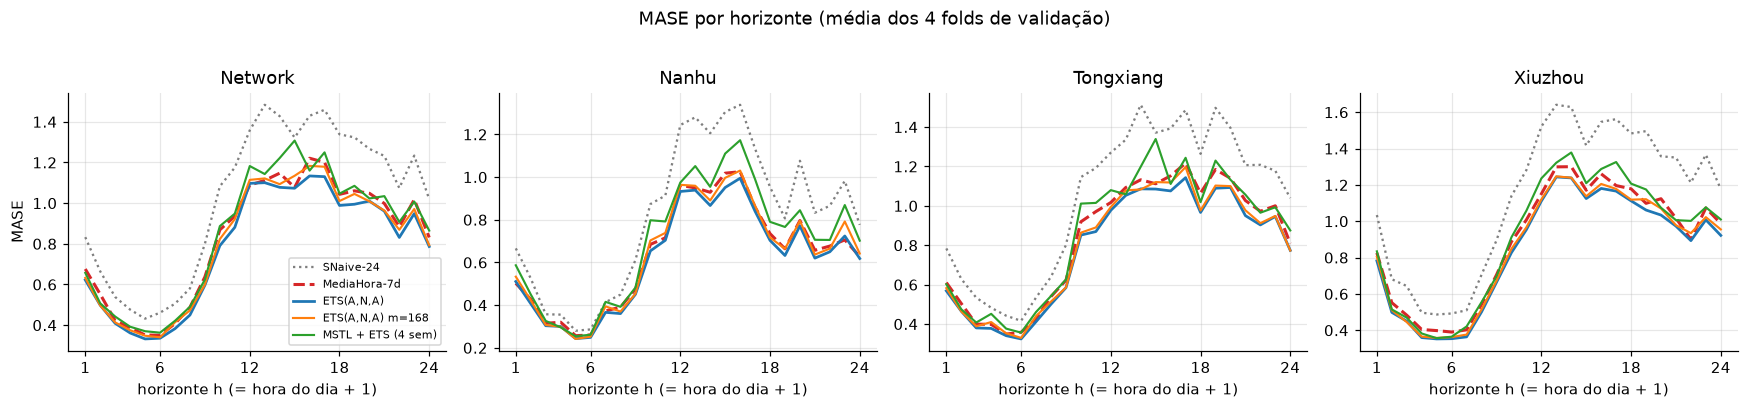

Δ MASE h=1-6  Δ MASE h=7-24  horizontes em que ganha
modelo             nível                                                          
ETS(A,N,A)         Network          -0.030         -0.046                       23
                   Nanhu            -0.011         -0.026                       22
                   Tongxiang        -0.027         -0.058                       24
                   Xiuzhou          -0.043         -0.051                       24
ETS(A,N,A) m=168   Network          -0.022         -0.019                       20
                   Nanhu            -0.004          0.002                       13
                   Tongxiang        -0.015         -0.040                       20
                   Xiuzhou          -0.035         -0.033                       22
MSTL + ETS (4 sem) Network          -0.001          0.030                        6
                   Nanhu             0.016          0.071                        2
                   Tongxiang         0.008          0.031                        9
                   Xiuzhou          -0.022          0.036                        8

In [14]:
STYLES = {"MediaHora-7d": dict(color="#D62728", ls="--", lw=2), "SNaive-24": dict(color="#7F7F7F", ls=":", lw=1.5),
          "ETS(A,N,A)": dict(color="#1F77B4", lw=1.8), "ETS(A,N,A) m=168": dict(color="#FF7F0E", lw=1.4), MSTL4: dict(color="#2CA02C", lw=1.4)}
plot_by_horizon(["SNaive-24", "MediaHora-7d", "ETS(A,N,A)", "ETS(A,N,A) m=168", MSTL4], styles=STYLES,
                title="MASE por horizonte (média dos 4 folds de validação)")

# Diferença face à referência por horizonte: horizontes iniciais (manhã cedo) vs restantes
rows = []
for n in ["ETS(A,N,A)", "ETS(A,N,A) m=168", MSTL4]:
    for lv in LEVELS:
        a = RESULTS[n]["res_h"].query("level == @lv").groupby("horizon")["MASE"].mean()
        b = RESULTS["MediaHora-7d"]["res_h"].query("level == @lv").groupby("horizon")["MASE"].mean()
        d = (a - b)
        rows.append({"modelo": n, "nível": lv, "Δ MASE h=1-6": d.loc[1:6].mean(), "Δ MASE h=7-24": d.loc[7:24].mean(),
                     "horizontes em que ganha": int((d < 0).sum())})
display(pd.DataFrame(rows).set_index(["modelo", "nível"]).round(3))

**Leitura.**

- **Ganho em quase todas as horas.** O ETS(A,N,A) fica abaixo da referência em 22 a 24 dos 24 horizontes, em todos os níveis. O ganho é maior durante o dia ($h$ = 7 a 24: −0,03 a −0,06 de MASE) do que de madrugada ($h$ = 1 a 6). Como a emissão é à meia-noite, o ganho não vem de "estar mais perto" do último dado. Vem de um perfil horário mais estável do que a média simples de 7 dias e de um nível que acompanha a procura mais recente.
- **Estabilidade.** O ETS(A,N,A) ganha à referência nos 4 *folds* de todos os níveis. O pior *fold* é o F4 (verão de 2021) na Rede, em Nanhu e em Xiuzhou. Em Xiuzhou o F4 chega a um MASE de 1,01, ainda assim abaixo da referência (1,06). Em Tongxiang o pior é o F1. O F2 (2021-Q1) é o mais fácil em todos os níveis, como já acontecia com as *baselines* na Task 1.
- **O ponto fraco são os picos.** O ETS acerta um pouco mais na **hora** de pico (53% contra 50% na Rede), mas falha mais no **valor** do pico (9,9 contra 8,7 sessões na Rede; 4,3 contra 3,2 em Nanhu). A suavização e a previsão da mediana em `log1p` achatam os máximos, o que se vê também no exemplo abaixo.
- **Custo:** desprezável. O ajuste leva cerca de 0,03 s por *fold* e a previsão de um dia cerca de 8 ms. As *baselines* são ainda mais rápidas, mas nenhum dos custos pesa na decisão.

MediaHora-7d  ETS(A,N,A)  MSTL + ETS (4 sem)
level     tipo                                                    
Network   dia normal         0.820       0.776               0.836
          feriado            0.892       0.867               0.970
Nanhu     dia normal         0.638       0.615               0.693
          feriado            0.651       0.644               0.731
Tongxiang dia normal         0.832       0.780               0.854
          feriado            0.866       0.833               0.925
Xiuzhou   dia normal         0.886       0.837               0.905
          feriado            0.936       0.886               0.985

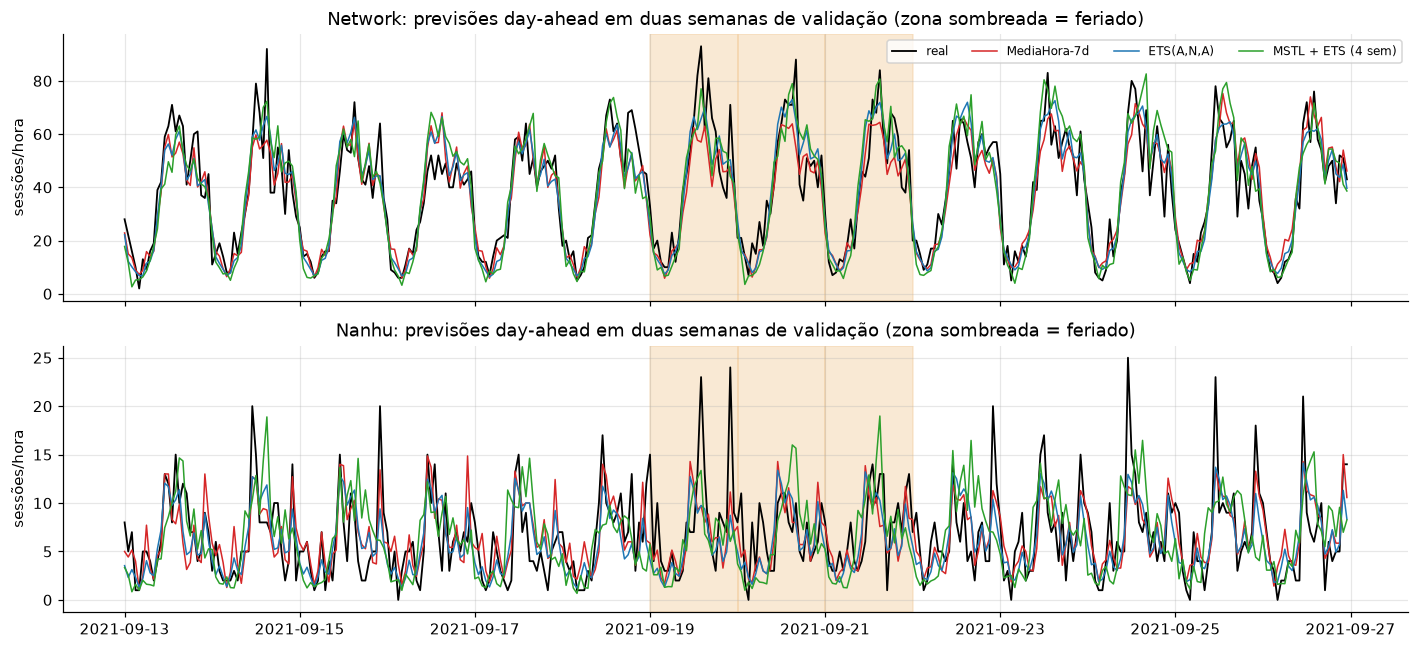

In [15]:
# Desempenho por tipo de dia (feriado vs normal) e um exemplo de previsões
rows = []
for n in ["MediaHora-7d", "ETS(A,N,A)", MSTL4]:
    rd = RESULTS[n]["res_d"]
    rd = rd.assign(tipo=np.where(rd["day"].isin(HOLIDAY_DAYS), "feriado", "dia normal"))
    rows.append(rd.groupby(["level", "tipo"])["MASE_dia"].mean().rename(n))
display(pd.concat(rows, axis=1).reindex(LEVELS, level=0).round(3))

ex_from, ex_to = pd.Timestamp("2021-09-13"), pd.Timestamp("2021-09-26 23:00")
fig, axes = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
for ax, lv in zip(axes, ["Network", "Nanhu"]):
    ax.plot(series.loc[ex_from:ex_to, lv], color="black", lw=1.2, label="real")
    for n, c in [("MediaHora-7d", "#D62728"), ("ETS(A,N,A)", "#1F77B4"), (MSTL4, "#2CA02C")]:
        pr = RESULTS[n]["preds"].query("level == @lv").set_index("timestamp")["y_pred"].loc[ex_from:ex_to]
        ax.plot(pr, color=c, lw=1, label=n)
    for d in pd.date_range(ex_from, ex_to, freq="D"):
        if d in HOLIDAY_DAYS:
            ax.axvspan(d, d + pd.Timedelta(days=1), color="#F2C894", alpha=0.4)
    ax.set(title=f"{lv}: previsões day-ahead em duas semanas de validação (zona sombreada = feriado)", ylabel="sessões/hora")
axes[0].legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

**Leitura.**

- **Feriados são mais difíceis do que dias normais para todos os modelos.** Na Rede, o MASE diário do ETS(A,N,A) sobe de 0,776 (dia normal) para 0,867 (feriado), e o da MédiaHora-7d de 0,820 para 0,892. O mesmo acontece nos três distritos (por exemplo, Xiuzhou: 0,837 contra 0,886). O ETS não conhece o calendário e só reage depois de o nível se ajustar.
- **O ETS continua a bater a referência nos feriados** (Rede 0,867 contra 0,892), mas a margem é menor do que nos dias normais (0,025 contra 0,044) e em Nanhu é quase nula (0,644 contra 0,651).
- **A MSTL + ETS é a pior nos feriados** (0,970 na Rede), porque projeta o perfil semanal médio das últimas 4 semanas, que não inclui o feriado.
- **Exemplo (gráfico):** nas duas semanas de setembro de 2021, o ETS segue bem o ciclo diário e o nível geral. Falha sobretudo os picos (os valores previstos ficam abaixo dos máximos reais), e nos dias de feriado (zona sombreada) a previsão continua com o perfil de um dia normal.

**Implicação:** o calendário é a informação mais óbvia que falta ao ETS. Testa-se como variável exógena no SARIMAX (secção 6).

### 3.5 Diagnóstico dos resíduos

Se um modelo aproveitou toda a informação da série, os resíduos (real − ajustado, no treino) devem parecer **ruído branco**: sem autocorrelação, com média zero e variância constante. Verifica-se para o melhor ETS de 24 h e para a MSTL + ETS (os resíduos de treino são os mesmos nas duas variantes de projeção), no treino do último *fold* (F4, o mais longo), na escala `log1p` em que os modelos são estimados:

- **ACF dos resíduos** até 336 h: barras fora da banda de ±1,96/√n indicam padrão por captar (em especial em 24, 168 e 336 h).
- **Teste de Ljung-Box** nos *lags* 24, 48 e 168: hipótese nula = sem autocorrelação até esse *lag*; p-valor < 0,05 indica padrão restante. Com milhares de observações, o teste rejeita quase sempre, por isso olha-se também para o **tamanho** das autocorrelações.
- **QQ-plot**: compara os resíduos com uma normal. A normalidade não é exigida para prever, mas caudas pesadas indicam erros extremos (feriados, quebras).
- **Resíduos por hora do dia**: o modelo erra mais a certas horas?

In [16]:
F4 = FOLD_BY_NAME["F4"]
n_train_f4 = day_idx(F4["val"][0]) * 24

def fit_on_f4(make_model, level):
    m = make_model()
    m.fit(Y[level][:n_train_f4].copy())
    return m

DIAG_MODELS = {
    "ETS(A,N,A)": lambda: ETSForecaster(window=regularINDOW, transform=log1pRANSFORM, **ETS_VARIANTS["ETS(A,N,A)"]),
    MSTL4: lambda: MSTLETSForecaster(window=regularINDOW, transform=log1pRANSFORM, profile_weeks=4),
}
RESID = {(n, lv): np.asarray(fit_on_f4(mk, lv).res_.resid) for n, mk in DIAG_MODELS.items() for lv in LEVELS}

lb_rows = []
for (n, lv), r in RESID.items():
    lb = acorr_ljungbox(r, lags=[24, 48, 168])
    a = acf(r, nlags=336, fft=True)
    lb_rows.append({"modelo": n, "nível": lv, "média": r.mean(), "dp": r.std(),
                    "ACF lag 1": a[1], "ACF lag 24": a[24], "ACF lag 168": a[168], "ACF lag 336": a[336],
                    "máx |ACF| (1-336)": np.abs(a[1:]).max(),
                    "LB p (24)": lb["lb_pvalue"].iloc[0], "LB p (48)": lb["lb_pvalue"].iloc[1], "LB p (168)": lb["lb_pvalue"].iloc[2]})
display(pd.DataFrame(lb_rows).set_index(["modelo", "nível"]).round(3))

média    dp  ACF lag 1  ACF lag 24  ACF lag 168  ACF lag 336  máx |ACF| (1-336)  LB p (24)  LB p (48)  LB p (168)
modelo             nível                                                                                                                       
ETS(A,N,A)         Network    0.001 0.338      0.078       0.008        0.019        0.013              0.078      0.000      0.000       0.000
                   Nanhu     -0.001 0.505      0.073       0.013        0.035        0.018              0.073      0.000      0.000       0.000
                   Tongxiang  0.002 0.395      0.054       0.020        0.014        0.018              0.054      0.000      0.000       0.000
                   Xiuzhou    0.002 0.512      0.103      -0.001        0.006        0.009              0.103      0.000      0.000       0.000
MSTL + ETS (4 sem) Network    0.001 0.266      0.038      -0.255       -0.161       -0.172              0.255      0.000      0.000       0.000
                   Nanhu     -0.000 0.396      0.035      -0.262       -0.155       -0.167              0.262      0.000      0.000       0.000
                   Tongxiang  0.001 0.311      0.033      -0.236       -0.175       -0.158              0.236      0.000      0.000       0.000
                   Xiuzhou    0.002 0.408      0.076      -0.263       -0.166       -0.155              0.263      0.000      0.000       0.000

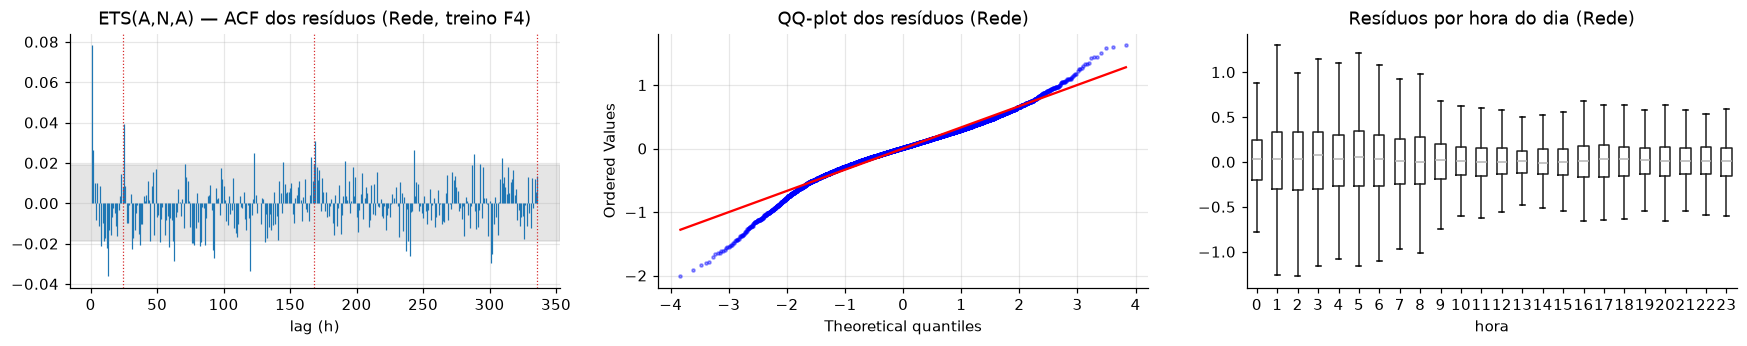

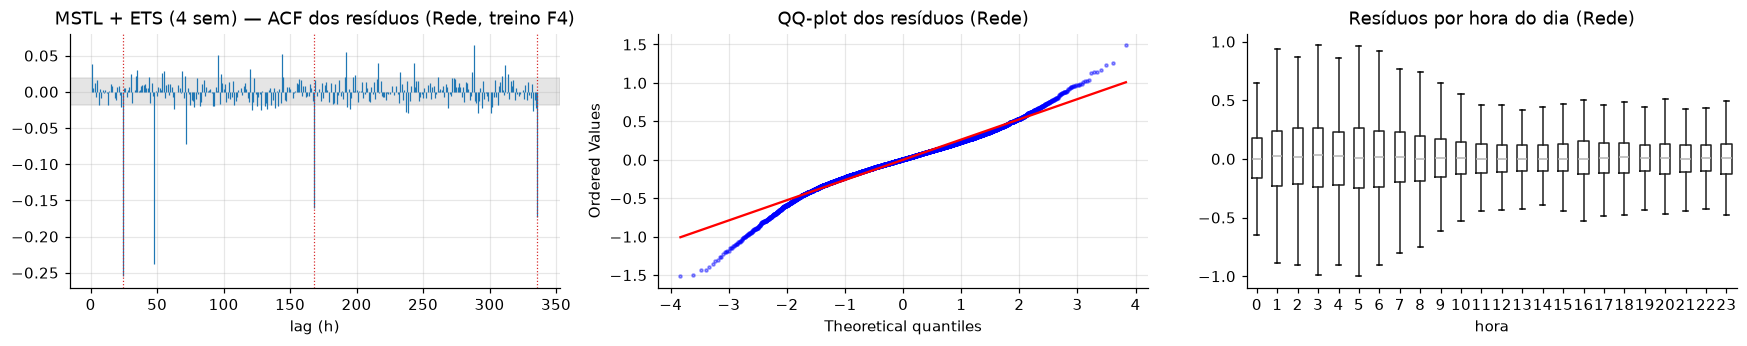

In [17]:
for n in DIAG_MODELS:
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
    r = RESID[(n, "Network")]
    a = acf(r, nlags=336, fft=True)
    band = 1.96 / np.sqrt(len(r))
    axes[0].vlines(range(1, 337), 0, a[1:], color="#1F77B4", lw=0.8)
    axes[0].axhspan(-band, band, color="#AAAAAA", alpha=0.3)
    for k in (24, 168, 336):
        axes[0].axvline(k, color="#D62728", ls=":", lw=0.8)
    axes[0].set(title=f"{n} — ACF dos resíduos (Rede, treino F4)", xlabel="lag (h)")
    stats.probplot(r, dist="norm", plot=axes[1])
    axes[1].get_lines()[0].set(markersize=2, alpha=0.4)
    axes[1].set_title("QQ-plot dos resíduos (Rede)")
    hrs = series.index[n_train_f4 - len(r):n_train_f4].hour
    pd.DataFrame({"hora": hrs, "resíduo": r}).boxplot(column="resíduo", by="hora", ax=axes[2], showfliers=False, grid=False)
    axes[2].set(title="Resíduos por hora do dia (Rede)", xlabel="hora", ylabel="")
    plt.suptitle("")
    plt.tight_layout()
    plt.show()

**Leitura.**

- **ETS(A,N,A): os resíduos estão perto de ruído branco.** A média é praticamente zero e as autocorrelações são pequenas (no máximo 0,05 a 0,10, sempre no *lag* 1; nos *lags* 24, 168 e 336 ficam abaixo de 0,04). O Ljung-Box rejeita a hipótese de ruído branco em todos os níveis (p < 0,001), mas, com mais de 10 000 observações, o teste deteta autocorrelações muito pequenas para terem efeito prático. O pequeno pico no *lag* 1 é dependência de curto prazo que um ARIMA pode captar (secções 4 e 5). Os pequenos picos em 168 e 336 h são o ciclo semanal fraco, que já se viu não compensar modelar.
- **MSTL + ETS: sobreajuste.** Os resíduos têm menor variância no treino (0,27 contra 0,34 na Rede), mas autocorrelação **negativa** forte nos *lags* 24 (≈ −0,25), 168 e 336 (≈ −0,16). A decomposição tirou "sazonalidade" a mais, incluindo ruído. Ajusta melhor o passado e prevê pior o futuro, o que explica os resultados da secção 3.3.
- **QQ-plot:** a cauda esquerda é mais pesada do que a de uma normal, devido a quedas bruscas (horas noturnas com 0 ou 1 sessões, que em `log1p` são grandes desvios). A normalidade não é necessária para a previsão pontual, mas indica que intervalos de previsão baseados na normal seriam pouco fiáveis nas caudas.
- **Resíduos por hora:** são maiores de madrugada (0h–8h). É o mesmo efeito do `log1p` com contagens baixas visto na secção 2.1. Em sessões, os erros maiores continuam a ser os do dia, como mostra o gráfico de MASE por horizonte.

### 3.6 Exportação para as secções seguintes

As previsões de validação de cada modelo ficam em `task2_outputs/` no formato comum (`model, level, fold, origin, timestamp, h, y_true, y_pred`), com os tempos de ajuste e de previsão em `fit_times_task2.csv`. A secção 7 (comparação global) junta estes ficheiros com os dos modelos ARIMA e SARIMAX.

In [18]:
EXPORT = list(BASELINES) + ETS_ALL
slug = lambda s: s.lower().replace("(", "").replace(")", "").replace(",", "").replace(" + ", "_").replace(" ", "_").replace("=", "")
for n in EXPORT:
    RESULTS[n]["preds"].to_csv(OUT_DIR / f"preds_task2_{slug(n)}.csv", index=False)
fit_times = pd.concat([RESULTS[n]["res_f"][["model", "level", "fold", "fit_s", "ms_per_origin"]] for n in EXPORT], ignore_index=True)
fit_times.to_csv(OUT_DIR / "fit_times_task2.csv", index=False)
summarize(EXPORT).to_csv(OUT_DIR / "summary_ets_task2.csv", index=False)
print(f"{len(EXPORT)} ficheiros de previsões + fit_times_task2.csv + summary_ets_task2.csv em {OUT_DIR.resolve()}")

11 ficheiros de previsões + fit_times_task2.csv + summary_ets_task2.csv em /Users/ctw03584/Documents/ISEP/mindd/MINDD-GPA-1260527-1211883-1231261/Parte2/task2_outputs


### 3.7 Conclusões das secções 1 a 3

**Base comum (para as secções seguintes)**

- O motor de avaliação reproduz exatamente as *baselines* da Task 1 e garante por construção que nenhum modelo vê dados do dia previsto nem do teste.
- Decisões fixadas: série modelada em **`log1p`**, parâmetros estimados **desde 2020-04-01**, previsão devolvida como **mediana** (`expm1`, sem correção) e cortada a zero (ficheiro `task2_decisions.json`).

**Suavização exponencial**

| Modelo | Rede | Nanhu | Tongxiang | Xiuzhou | Bate a referência? |
|---|---|---|---|---|---|
| MédiaHora-7d (referência) | 0,825 | 0,639 | 0,834 | 0,890 | — |
| **ETS(A,N,A)**, $m=24$ | **0,783** | **0,616** | **0,784** | **0,841** | sim, nos 4 níveis |
| ETS(A,Ad,A) | 0,783 | 0,616 | 0,784 | 0,841 | sim (igual ao anterior: a tendência é anulada) |
| ETS(A,A,A) | 0,789 | 0,620 | 0,786 | 0,848 | sim, mas pior do que sem tendência |
| ETS(A,N,A), $m=168$ | 0,805 | 0,639 | 0,800 | 0,856 | em 3 níveis (não em Nanhu) |
| MSTL + ETS (4 sem) | 0,847 | 0,696 | 0,860 | 0,911 | não |

*(MASE médio nos 4 folds de validação.)*

- **Melhor modelo ETS: ETS(A,N,A) em `log1p`.** Reduz o MASE entre 3,5% e 6% face à MédiaHora-7d em todos os níveis, ganha nos 4 *folds* e em quase todos os horizontes, e custa milissegundos.
- **Pontos fortes:** simples, estável entre *folds* (parâmetros quase iguais), interpretável (nível + perfil horário que se vão atualizando) e muito rápido.
- **Limitações:** só representa um ciclo sazonal; não sabe de feriados (erra mais nesses dias); achata os picos (erro do valor do pico maior do que o da referência); subestima ligeiramente o volume (previsão da mediana); resta uma pequena autocorrelação de curto prazo nos resíduos.
- **O que não funcionou:** a tendência (inexistente à escala horária) e as tentativas de incluir o ciclo semanal ($m=168$ e MSTL). O ciclo semanal é fraco, e representá-lo custa mais em ruído do que ganha em sinal.

**Para as secções seguintes:** o **ETS(A,N,A)** passa a ser a fasquia dos modelos estatísticos. O ARIMA (secções 4–5) pode ganhar na dependência de curto prazo que resta nos resíduos, e o SARIMAX (secção 6) nos feriados e nos picos, que o ETS não modela.

## 4. Identificação ARIMA

### 4.1 Ideia base e opções de implementação

O ETS descreve a série por componentes (nível, tendência, sazonalidade). Os modelos **ARIMA** seguem outra via: tornam a série estacionária por diferenciação e modelam a **autocorrelação** que sobra com termos autorregressivos (AR) e de médias móveis (MA). A versão com sazonalidade é o SARIMA$(p,d,q)(P,D,Q)_m$:

$$\Phi(B^m)\,\phi(B)\,(1-B)^d\,(1-B^m)^D\,z_t=\Theta(B^m)\,\theta(B)\,\varepsilon_t$$

onde $B$ é o operador de atraso, $z_t=\ln(1+y_t)$ e $m=24$. $(1-B^m)^D$ remove o ciclo diário; $\phi,\theta$ (ordens $p,q$) modelam a dependência de curto prazo; $\Phi,\Theta$ (ordens $P,Q$) modelam a dependência entre dias à mesma hora.

**Opções de implementação (todas coerentes com o protocolo da Task 1):**

- **Diferenciação sazonal explícita com $D=1$, $m=24$:** modela-se $w_t=z_t-z_{t-24}$ com um ARMA sazonal. É equivalente ao SARIMA com $D=1$ (a previsão é $\hat z_{T+h}=z_{T+h-24}+\hat w_{T+h}$), e como $h\le 24$, o termo $z_{T+h-24}$ é sempre um valor **já observado** no dia anterior. É mais rápido e mantém o espaço de estados pequeno.
- **Estimação:** máxima verosimilhança (`SARIMAX` do `statsmodels`), **uma vez por *fold***, com a janela e a transformação fixadas na secção 2. Em cada origem, o estado do modelo é atualizado com as observações novas (filtro de Kalman), **sem reestimar**, como no protocolo.
- **Sem constante:** a média de $w$ é praticamente zero (0,005 na Rede).

**Identificação sem fuga de informação.** A ordem $(p,q,P,Q)$ identifica-se **só com o treino do F1** (2020-04-01 a 2020-09-30), anterior a qualquer dado de validação. A escolha final entre as poucas candidatas faz-se depois na validação, como qualquer outro hiperparâmetro. O teste (2021-Q4) continua intocado.

In [19]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller, kpss, pacf


def fit_filter(mod, maxiter=200):
    # Máxima verosimilhança e resultados do filtro de Kalman (sem o suavizador, que aqui não é necessário e
    # que provocou falhas esporádicas, com encerramento dos processos, no statsmodels 0.15 em macOS).
    params = mod.fit(disp=False, maxiter=maxiter, return_params=True)
    return mod.filter(params)


# Janela de identificação: treino do F1 (2020-04-01 a 2020-09-30), anterior a todas as validações.
F1 = FOLD_BY_NAME["F1"]
N_F1 = day_idx(F1["val"][0]) * 24
S0 = hidx(MASE_SCALE_FROM)
ID_Z = {lv: np.log1p(Y[lv][S0:N_F1]) for lv in LEVELS}
ID_W = {lv: z[24:] - z[:-24] for lv, z in ID_Z.items()}   # w = (1 - B^24) z
print(f"Janela de identificação: {series.index[S0].date()} a {series.index[N_F1 - 1].date()} ({len(ID_Z['Network'])} horas; w tem {len(ID_W['Network'])})")

rows = []
for lv in LEVELS:
    for label, x in [("z = log1p(y)", ID_Z[lv]), ("w = Δ24 z", ID_W[lv]), ("Δ1 w", np.diff(ID_W[lv]))]:
        adf_p = adfuller(x, maxlag=48, autolag="AIC")[1]
        kpss_p = kpss(x, regression="c", nlags="auto")[1]
        rows.append({"nível": lv, "série": label, "p ADF": adf_p, "p KPSS": kpss_p,
                     "leitura": "estacionária" if (adf_p < 0.05 and kpss_p >= 0.05) else "não conclusiva / não estacionária"})
display(pd.DataFrame(rows).set_index(["nível", "série"]).round(4))
print("KPSS: p-valores truncados a [0.01, 0.10].")

Janela de identificação: 2020-04-01 a 2020-09-30 (4392 horas; w tem 4368)


p ADF  p KPSS                            leitura
nível     série                                                         
Network   z = log1p(y)  0.130   0.010  não conclusiva / não estacionária
          w = Δ24 z     0.000   0.100                       estacionária
          Δ1 w          0.000   0.100                       estacionária
Nanhu     z = log1p(y)  0.000   0.010  não conclusiva / não estacionária
          w = Δ24 z     0.000   0.100                       estacionária
          Δ1 w          0.000   0.100                       estacionária
Tongxiang z = log1p(y)  0.178   0.010  não conclusiva / não estacionária
          w = Δ24 z     0.000   0.100                       estacionária
          Δ1 w          0.000   0.100                       estacionária
Xiuzhou   z = log1p(y)  0.004   0.010  não conclusiva / não estacionária
          w = Δ24 z     0.000   0.100                       estacionária
          Δ1 w          0.000   0.100                       estacionária

KPSS: p-valores truncados a [0.01, 0.10].


**Leitura (estacionariedade, treino do F1).**

- **$z=\ln(1+y)$ não é estacionária:** o KPSS rejeita a estacionariedade nos quatro níveis (p = 0,01) e o ADF só a rejeita em Nanhu e Xiuzhou. A leitura conjunta é "não conclusiva / não estacionária", como na Task 1.
- **Com a diferença sazonal de 24 h ($w$), as quatro séries ficam estacionárias** (ADF p ≈ 0, KPSS p ≥ 0,10). Confirma-se $D=1$, $m=24$.
- Uma segunda diferenciação (Δ1 de $w$) também dá séries estacionárias, mas não é necessária: o ACF de $w$ no *lag* 1 é **positivo** (0,08 a 0,12). Sobrediferenciar produziria uma autocorrelação fortemente negativa nesse *lag*. Fica $d=0$.

### 4.2 ACF, PACF e grelha de ordens

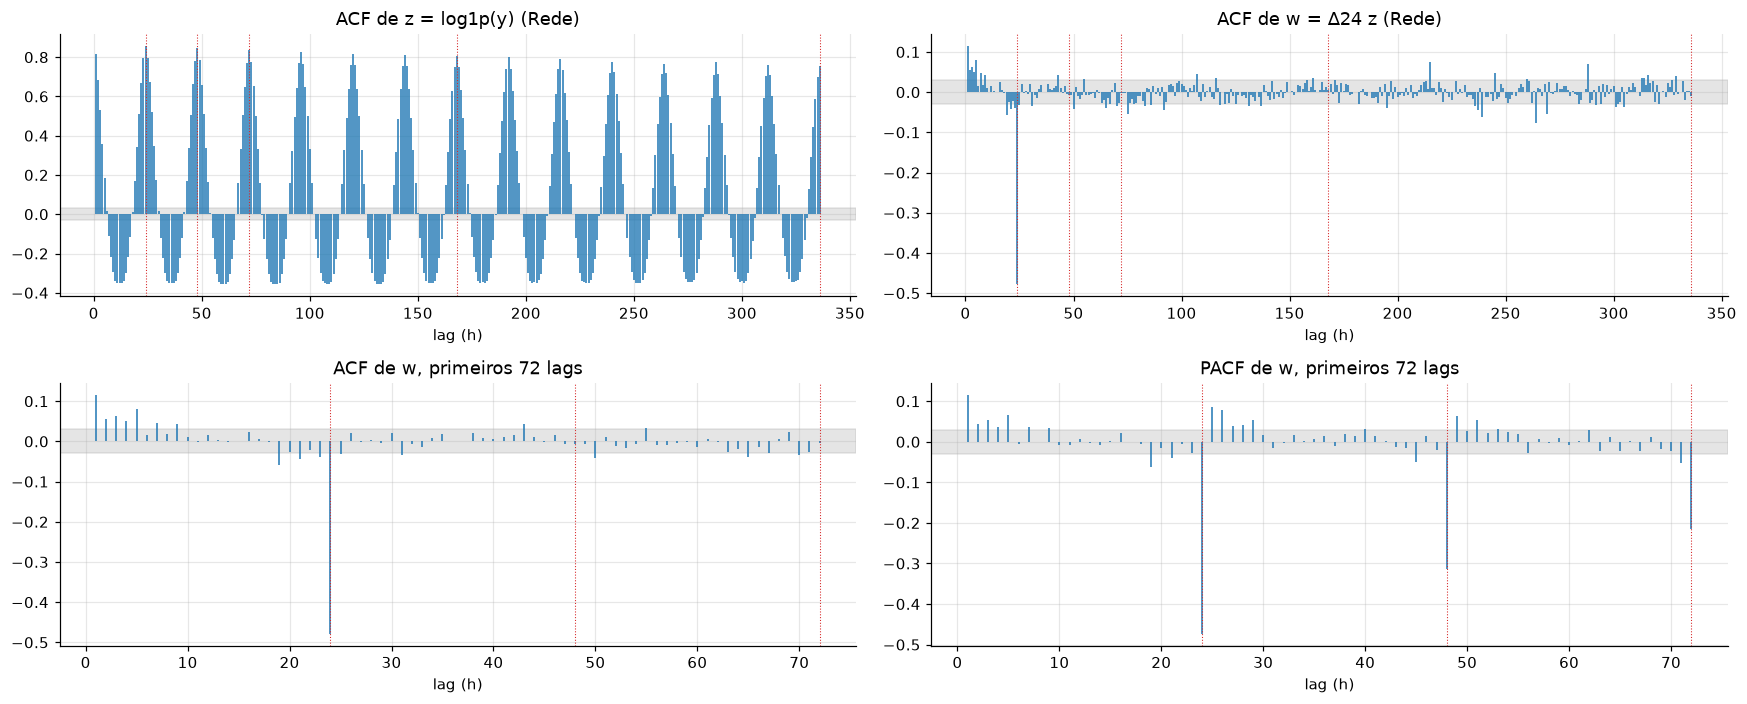

,ACF lag 1,ACF lag 2,ACF lag 3,ACF lag 24,ACF lag 25,ACF lag 48,ACF lag 168,ACF lag 336,PACF lag 1,PACF lag 2,PACF lag 3,PACF lag 24,PACF lag 48
Network,0.115,0.056,0.063,-0.479,-0.032,-0.006,0.006,-0.010,0.115,0.043,0.053,-0.473,-0.314
Nanhu,0.076,0.040,0.031,-0.491,-0.030,0.001,0.024,0.003,0.076,0.035,0.026,-0.488,-0.313
Tongxiang,0.104,0.034,0.025,-0.484,-0.044,0.001,0.013,0.022,0.104,0.023,0.020,-0.479,-0.310
Xiuzhou,0.093,0.024,-0.003,-0.508,-0.050,0.019,0.008,0.016,0.093,0.015,-0.007,-0.511,-0.317


In [20]:
NLAG = 336
fig, axes = plt.subplots(2, 2, figsize=(16, 6.5))
z, w = ID_Z["Network"], ID_W["Network"]
a_z, a_w = acf(z, nlags=NLAG, fft=True), acf(w, nlags=NLAG, fft=True)
p_w = pacf(w, nlags=72, method="ywm")
band = lambda x: 1.96 / np.sqrt(len(x))
for ax, vals, title, n, x in [
    (axes[0, 0], a_z, "ACF de z = log1p(y) (Rede)", NLAG, z),
    (axes[0, 1], a_w, "ACF de w = Δ24 z (Rede)", NLAG, w),
    (axes[1, 0], a_w[:73], "ACF de w, primeiros 72 lags", 72, w),
    (axes[1, 1], p_w, "PACF de w, primeiros 72 lags", 72, w),
]:
    ax.vlines(range(1, n + 1), 0, vals[1:n + 1], color="#1F77B4", lw=1)
    ax.axhspan(-band(x), band(x), color="#AAAAAA", alpha=0.3)
    for k in (24, 48, 72, 168, 336):
        if k <= n:
            ax.axvline(k, color="#D62728", ls=":", lw=0.7)
    ax.set(title=title, xlabel="lag (h)")
plt.tight_layout()
plt.show()

LAGS_TAB = [1, 2, 3, 24, 25, 48, 168, 336]
tab = {}
for lv in LEVELS:
    aw = acf(ID_W[lv], nlags=NLAG, fft=True)
    tab[lv] = {f"ACF lag {k}": aw[k] for k in LAGS_TAB}
    pw = pacf(ID_W[lv], nlags=48, method="ywm")
    tab[lv].update({f"PACF lag {k}": pw[k] for k in (1, 2, 3, 24, 48)})
display(pd.DataFrame(tab).T.round(3))

**Leitura (ACF e PACF, Rede; os distritos são parecidos, ver tabela).**

- **ACF de $z$ (canto superior esquerdo):** picos de 24 em 24 h que só descem devagar (de 0,85 para cerca de 0,7 ao fim de 14 dias). É o ciclo diário dominante sobre uma série com memória longa, e justifica a diferenciação sazonal.
- **ACF de $w$:** desaparece quase toda a estrutura. O que sobra é um **pico negativo isolado no *lag* 24** (−0,48 a −0,51 nos quatro níveis) e uma autocorrelação positiva pequena e decrescente nos primeiros *lags* (0,08 a 0,12 no *lag* 1, perto de zero por volta das 9 h).
- **PACF de $w$:** decresce de forma geométrica nos múltiplos de 24 h (−0,47, −0,31 e −0,21 nos *lags* 24, 48 e 72). Um ACF que corta no *lag* 24 com um PACF que decresce nos múltiplos de 24 é o padrão de um **MA sazonal de ordem 1** ($Q=1$). Isto acontece sempre que se diferencia uma série com perfil diário estável: o ruído do dia de ontem entra duas vezes na diferença.
- **Dependência de curto prazo:** a parte positiva e lenta dos primeiros *lags* sugere um ARMA de ordem baixa ($p,q\le 2$ ou 3).
- **Sem ciclo semanal na parte que sobra:** nos *lags* 168 e 336, o ACF de $w$ fica entre −0,01 e 0,03, dentro da banda de ±0,03. Depois de remover o ciclo diário não há autocorrelação semanal que justifique um termo sazonal em 168 h, o que é coerente com a força semanal fraca (cerca de 0,18) da Task 1.

**Hipótese inicial:** SARIMA$(p,0,q)(P,0,Q)_{24}$ sobre $w$, com $Q=1$ e $p,q$ pequenos. A grelha seguinte confirma-o com um critério objetivo.

In [21]:
def _fit_grid(level, order, so):
    warnings.simplefilter("ignore")
    t0 = time.perf_counter()
    r = fit_filter(SARIMAX(ID_W[level], order=order, seasonal_order=(so[0], 0, so[1], 24), trend="n"))
    return {"level": level, "p": order[0], "q": order[2], "P": so[0], "Q": so[1], "aicc": r.aicc, "bic": r.bic,
            "k": len(r.params), "seg": time.perf_counter() - t0}

PQ = [(p, q) for p in range(4) for q in range(4) if p + q <= 4]
SEAS = [(0, 0), (1, 0), (0, 1), (1, 1)]
jobs = [(lv, (p, 0, q), so) for lv in LEVELS for (p, q) in PQ for so in SEAS]
t0 = time.perf_counter()
grid = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(_fit_grid)(*j) for j in jobs))
print(f"{len(jobs)} ajustes em {time.perf_counter() - t0:.0f} s")
grid["ordem"] = grid.apply(lambda r: f"({r.p},0,{r.q})({r.P},0,{r.Q})24", axis=1)
grid.to_csv(OUT_DIR / "sarima_order_grid_task2.csv", index=False)

for crit in ["aicc", "bic"]:
    print(f"Melhores 4 ordens por {crit.upper()} em cada nível (série w do treino do F1)")
    top = (grid.sort_values(["level", crit]).groupby("level").head(4)
           .assign(rank=lambda d: d.groupby("level").cumcount() + 1))
    display(top.pivot(index="rank", columns="level", values="ordem")[LEVELS])
ID_BEST = {c: {lv: grid[grid.level == lv].sort_values(c).iloc[0] for lv in LEVELS} for c in ["aicc", "bic"]}

208 ajustes em 78 s
Melhores 4 ordens por AICC em cada nível (série w do treino do F1)


level,Network,Nanhu,Tongxiang,Xiuzhou
rank,,,,
1,"(2,0,2)(0,0,1)24","(1,0,2)(0,0,1)24","(3,0,1)(0,0,1)24","(1,0,3)(0,0,1)24"
2,"(3,0,1)(0,0,1)24","(2,0,1)(0,0,1)24","(2,0,2)(0,0,1)24","(1,0,3)(1,0,1)24"
3,"(2,0,2)(1,0,1)24","(3,0,1)(0,0,1)24","(1,0,3)(0,0,1)24","(3,0,1)(0,0,1)24"
4,"(1,0,3)(0,0,1)24","(1,0,3)(0,0,1)24","(2,0,2)(1,0,1)24","(2,0,1)(0,0,1)24"


Melhores 4 ordens por BIC em cada nível (série w do treino do F1)


level,Network,Nanhu,Tongxiang,Xiuzhou
rank,,,,
1,"(2,0,1)(0,0,1)24","(1,0,1)(0,0,1)24","(2,0,1)(0,0,1)24","(2,0,1)(0,0,1)24"
2,"(2,0,2)(0,0,1)24","(1,0,0)(0,0,1)24","(3,0,1)(0,0,1)24","(1,0,2)(0,0,1)24"
3,"(1,0,2)(0,0,1)24","(1,0,2)(0,0,1)24","(2,0,2)(0,0,1)24","(1,0,3)(0,0,1)24"
4,"(3,0,1)(0,0,1)24","(2,0,1)(0,0,1)24","(1,0,3)(0,0,1)24","(3,0,1)(0,0,1)24"


**Leitura.**

- **O MA sazonal está em todas as melhores ordens.** As 4 melhores por AICc e as 4 melhores por BIC têm $Q=1$ em todos os níveis (e $P=0$, exceto uma ou duas entradas com $P=1$). O termo AR sazonal quase não acrescenta nada.
- **A parte de curto prazo é pequena:** $p+q$ entre 2 e 4. O AICc escolhe ordens mais ricas (por exemplo, (2,0,2) na Rede e (1,0,3) em Xiuzhou) e o BIC, que penaliza mais os parâmetros, escolhe (2,0,1) ou (1,0,1).
- **As diferenças são pequenas:** as 4 melhores ordens de cada nível ficam a menos de 5 pontos de AICc entre si, por isso a escolha não é clara só com o treino do F1. A validação decide entre as candidatas.

In [22]:
def extend_filter(res, endog, exog=None):
    # Equivalente a res.extend(...), mas só com o filtro de Kalman (sem o suavizador, que é desnecessário e mais lento):
    # o estado inicial das novas observações é o estado previsto no fim da amostra anterior; os parâmetros não mudam.
    from statsmodels.tsa.statespace.initialization import Initialization
    mod = res.model.clone(endog, exog=exog)
    mod.ssm.initialization = Initialization(mod.k_states, "known", constant=res.predicted_state[..., -1],
                                            stationary_cov=res.predicted_state_cov[..., -1])
    return mod.filter(res.params)


DIFF_POLY = {(): {0: 1.0}, (24,): {0: 1.0, 24: -1.0}, (168,): {0: 1.0, 168: -1.0}, (24, 168): {0: 1.0, 24: -1.0, 168: -1.0, 192: 1.0}}


def apply_diff(a, poly, start, stop):
    # valores de sum_k c_k a[t-k] para t em [start, stop)
    return sum(c * a[start - k:stop - k] for k, c in poly.items())


class SARIMAForecaster(Forecaster):
    # SARIMA/SARIMAX com diferenciação sazonal explícita (equivalente a D=1 com m=24) e ARMA sazonal em 24 h.
    # orders: ((p,d,q),(P,Q)) ou dict nível -> ((p,d,q),(P,Q)). diff: lags da diferenciação sazonal. exog: chave de EXOG ou None.
    # Os parâmetros são estimados uma vez por fold; em cada origem o estado é estendido com as observações novas (filtro de Kalman), sem reestimar.
    def __init__(self, orders, diff=(24,), exog=None, window="regular", transform="log1p", maxiter=200):
        self.orders, self.diff, self.exog = orders, tuple(diff), exog
        self.window, self.transform, self.maxiter = window, transform, maxiter

    def order_for(self, level):
        return self.orders[level] if isinstance(self.orders, dict) else self.orders

    def _x(self):
        # exógenas padronizadas (só a meteorologia, com a média e o desvio do treino) para todas as horas da série
        X, names, wi = EXOG[(self.level, self.exog)]
        X = X.copy()
        for j in wi:
            X[:, j] = (X[:, j] - self.mu[j]) / self.sd[j]
        return X, names

    def fit(self, y_train):
        import warnings
        from statsmodels.tsa.statespace.sarimax import SARIMAX
        warnings.simplefilter("ignore")
        fwd, _ = TRANSFORMS[self.transform]
        self.s0 = WINDOW_START[self.window](len(y_train))
        self.poly, self.maxlag = DIFF_POLY[self.diff], max(DIFF_POLY[self.diff])
        z = fwd(y_train[self.s0:])
        n_w = len(z)
        u = apply_diff(z, self.poly, self.maxlag, n_w)
        Xd = None
        if self.exog:
            X, _, wi = EXOG[(self.level, self.exog)]
            seg = X[self.s0:self.s0 + n_w]
            self.mu, self.sd = seg.mean(axis=0), seg.std(axis=0) + 1e-9
            self.Xs, self.xnames = self._x()
            Xd = apply_diff(self.Xs[self.s0:], self.poly, self.maxlag, n_w)
        (p, d, q), (P, Q) = self.order_for(self.level)
        self.res_ = fit_filter(SARIMAX(u, exog=Xd, order=(p, d, q), seasonal_order=(P, 0, Q, 24), trend="n"), self.maxiter)
        self.cur_res, self.cur_n, self.n_fit = self.res_, len(y_train), len(y_train)
        return self

    def predict(self, y_hist):
        fwd, inv = TRANSFORMS[self.transform]
        n = len(y_hist)
        z = fwd(y_hist[self.s0:])
        a, b = self.cur_n - self.s0, n - self.s0
        if b > a:
            u_new = apply_diff(z, self.poly, a, b)
            xd_new = apply_diff(self.Xs[self.s0:], self.poly, a, b) if self.exog else None
            self.cur_res = extend_filter(self.cur_res, u_new, xd_new)
            self.cur_n = n
        xf = apply_diff(self.Xs[self.s0:], self.poly, b, b + 24) if self.exog else None
        uf = np.asarray(self.cur_res.forecast(24, exog=xf))
        zf = uf.copy()
        for k, c in self.poly.items():
            if k:
                zf -= c * z[b - k:b - k + 24]
        return inv(zf)

    def info(self):
        names = list(self.res_.param_names)
        if self.exog:
            names = [self.xnames[int(nm[1:]) - 1] if nm.startswith("x") and nm[1:].isdigit() else nm for nm in names]
        return {**dict(zip(names, np.asarray(self.res_.params))), "AICc": self.res_.aicc, "ordem": str(self.order_for(self.level))}

### 4.3 Candidatas avaliadas na validação

Avaliam-se nos 4 *folds*, para os quatro níveis, as seguintes configurações:

| Candidata | Para que serve |
|---|---|
| **SARIMA AICc** | melhor ordem por AICc em cada nível (treino do F1) |
| **SARIMA BIC** | melhor ordem por BIC em cada nível, mais parcimoniosa |
| **SARIMA (1,0,1)(1,0,1)24** | uma ordem simples e igual para todos os níveis |
| **SARIMA (1,0,0)(0,0,0)24** | ablação: só diferenciação sazonal mais um AR(1); mostra o que o ARMA sazonal acrescenta |
| **ARIMA(2,1,2) sem sazonalidade** | contraste: ignora o ciclo diário (modelo não sazonal sobre $z$) |

Todas estão na interface comum, por isso usam as mesmas origens, a mesma transformação e a mesma janela dos modelos ETS.

In [23]:
def orders_from(best):
    return {lv: ((int(r.p), 0, int(r.q)), (int(r.P), int(r.Q))) for lv, r in best.items()}

ORD_AICC, ORD_BIC = orders_from(ID_BEST["aicc"]), orders_from(ID_BEST["bic"])
print("Ordem por AICc:", {lv: f"({o[0][0]},0,{o[0][2]})({o[1][0]},0,{o[1][1]})24" for lv, o in ORD_AICC.items()})
print("Ordem por BIC :", {lv: f"({o[0][0]},0,{o[0][2]})({o[1][0]},0,{o[1][1]})24" for lv, o in ORD_BIC.items()})

SARIMA_CAND = {
    "SARIMA AICc": SARIMAForecaster(ORD_AICC),
    "SARIMA BIC": SARIMAForecaster(ORD_BIC),
    "SARIMA (1,0,1)(1,0,1)24": SARIMAForecaster(((1, 0, 1), (1, 1))),
    "SARIMA (1,0,0)(0,0,0)24": SARIMAForecaster(((1, 0, 0), (0, 0))),
}
for nm, m in SARIMA_CAND.items():
    run_model(nm, lambda m=m: SARIMAForecaster(m.orders))
# Contraste: ARIMA não sazonal (sem diferenciação sazonal) em z
run_model("ARIMA(2,1,2) sem sazonalidade", lambda: SARIMAForecaster(((2, 1, 2), (0, 0)), diff=()))
CAND_SET = list(SARIMA_CAND) + ["ARIMA(2,1,2) sem sazonalidade"]
cols = ["MAE", "RMSE", "MASE", "MASE_dp", "MASE_pior", "Δ_MASE_vs_ref", "IC_inf", "IC_sup", "folds_ganhos", "melhor_que_ref", "ajuste_s", "ms_origem"]
show_summary(["ETS(A,N,A)", "MediaHora-7d"] + CAND_SET, cols=cols);
print("MASE por fold")
display(fold_table(["ETS(A,N,A)", "MediaHora-7d"] + CAND_SET).round(3))

Ordem por AICc: {'Network': '(2,0,2)(0,0,1)24', 'Nanhu': '(1,0,2)(0,0,1)24', 'Tongxiang': '(3,0,1)(0,0,1)24', 'Xiuzhou': '(1,0,3)(0,0,1)24'}
Ordem por BIC : {'Network': '(2,0,1)(0,0,1)24', 'Nanhu': '(1,0,1)(0,0,1)24', 'Tongxiang': '(2,0,1)(0,0,1)24', 'Xiuzhou': '(2,0,1)(0,0,1)24'}


SARIMA AICc: 16 ajustes (nível × fold) em 26.8 s


SARIMA BIC: 16 ajustes (nível × fold) em 21.3 s


SARIMA (1,0,1)(1,0,1)24: 16 ajustes (nível × fold) em 17.7 s


SARIMA (1,0,0)(0,0,0)24: 16 ajustes (nível × fold) em 0.6 s


ARIMA(2,1,2) sem sazonalidade: 16 ajustes (nível × fold) em 4.1 s
--- Network ---


... (5 outputs left out)

--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA AICc,3.242,4.627,0.839,0.163,1.010,-0.050,-0.064,-0.038,4.000,sim,12.661,2.420
SARIMA BIC,3.242,4.627,0.839,0.163,1.010,-0.050,-0.064,-0.038,4.000,sim,10.346,2.401
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4.000,sim,0.029,8.070
"SARIMA (1,0,1)(1,0,1)24",3.267,4.653,0.846,0.161,1.012,-0.044,-0.058,-0.031,4.000,sim,6.870,3.024
MediaHora-7d,3.436,4.738,0.890,0.161,1.058,NaN,NaN,NaN,NaN,NaN,0.000,0.006
"SARIMA (1,0,0)(0,0,0)24",4.364,6.059,1.130,0.204,1.343,0.240,0.221,0.262,0.000,não,0.052,1.699
"ARIMA(2,1,2) sem sazonalidade",6.044,7.839,1.562,0.483,2.110,0.674,0.583,0.750,0.000,não,1.496,1.882


MASE por fold


fold                                       F1    F2    F3    F4
level     model                                                
Network   ARIMA(2,1,2) sem sazonalidade 2.192 1.641 2.173 2.721
          ETS(A,N,A)                    0.798 0.656 0.789 0.890
          MediaHora-7d                  0.847 0.685 0.836 0.933
          SARIMA (1,0,0)(0,0,0)24       1.017 0.847 1.035 1.187
          SARIMA (1,0,1)(1,0,1)24       0.785 0.640 0.777 0.893
          SARIMA AICc                   0.788 0.644 0.778 0.888
          SARIMA BIC                    0.786 0.641 0.793 0.889
Nanhu     ARIMA(2,1,2) sem sazonalidade 1.121 0.745 0.806 1.198
          ETS(A,N,A)                    0.671 0.495 0.536 0.764
          MediaHora-7d                  0.699 0.527 0.560 0.769
          SARIMA (1,0,0)(0,0,0)24       0.888 0.678 0.712 0.979
          SARIMA (1,0,1)(1,0,1)24       0.672 0.498 0.540 0.775
          SARIMA AICc                   0.671 0.493 0.537 0.773
          SARIMA BIC                    0.672 0.498 0.540 0.775
Tongxiang ARIMA(2,1,2) sem sazonalidade 2.003 1.477 1.816 2.100
          ETS(A,N,A)                    0.861 0.669 0.754 0.854
          MediaHora-7d                  0.922 0.701 0.800 0.915
          SARIMA (1,0,0)(0,0,0)24       1.103 0.879 0.987 1.160
          SARIMA (1,0,1)(1,0,1)24       0.855 0.661 0.746 0.855
          SARIMA AICc                   0.860 0.662 0.749 0.853
          SARIMA BIC                    0.859 0.662 0.748 0.853
Xiuzhou   ARIMA(2,1,2) sem sazonalidade 1.323 1.025 1.792 2.110
          ETS(A,N,A)                    0.758 0.659 0.934 1.012
          MediaHora-7d                  0.807 0.707 0.988 1.058
          SARIMA (1,0,0)(0,0,0)24       1.012 0.907 1.259 1.343
          SARIMA (1,0,1)(1,0,1)24       0.760 0.665 0.946 1.012
          SARIMA AICc                   0.754 0.655 0.938 1.010
          SARIMA BIC                    0.754 0.655 0.938 1.010

**Leitura.**

- **O ciclo diário é imprescindível.** O ARIMA(2,1,2) sem sazonalidade tem MASE de 2,18 na Rede (cerca de 2,6 vezes o da referência): sem ciclo, as 24 previsões convergem para um valor quase constante. É a razão pela qual a sazonalidade tem de entrar de forma explícita.
- **A ablação (1,0,0)(0,0,0) fica igual ao *seasonal naïve* de 24 h** (MASE 1,022 na Rede, o mesmo da SNaive-24). O ARMA de curto prazo sozinho não ensina nada a 24 h de distância. Todo o ganho vem do **MA sazonal**, que faz uma média ponderada dos dias anteriores em vez de copiar só ontem (o que lembra a MédiaHora-7d e o ETS).
- **As três candidatas SARIMA completas ficam praticamente empatadas** (MASE na Rede 0,774 a 0,777, em Tongxiang 0,779 a 0,781). A diferença máxima entre elas é 0,007, muito inferior à variação entre *folds* (desvio padrão de cerca de 0,10). A ordem exata das partes AR e MA é, portanto, secundária.
- **Todas cumprem a regra de seleção face à MédiaHora-7d** nos quatro níveis (em Nanhu ganham em 3 de 4 *folds*, o mínimo exigido).

**Decisão:** escolhe-se, por nível, a candidata com o menor MASE médio de validação: **(1,0,1)(1,0,1)24 na Rede e em Tongxiang**, e **a ordem do AICc em Nanhu (1,0,2)(0,0,1) e em Xiuzhou (1,0,3)(0,0,1)**. Como a diferença entre candidatas é desprezável, esta escolha pesa pouco no resultado final.

## 5. SARIMA, ciclo semanal e MSTL + ARIMA

### 5.1 SARIMA com a ordem escolhida e variantes para o ciclo semanal

Fixa-se a ordem de cada nível (secção 4.3) e comparam-se três formas de tratar a sazonalidade:

| Modelo | Diferenciação | Ciclos representados |
|---|---|---|
| **SARIMA (D=24)** | $(1-B^{24})$ | diário (ARMA sazonal em 24 h) |
| **SARIMA (D=168)** | $(1-B^{168})$ | semanal (a semana inteira é o ciclo; o diário só entra pelo ARMA) |
| **SARIMA (D=24 e 168)** | $(1-B^{24})(1-B^{168})$ | diário e semanal por dupla diferenciação |

O `statsmodels` só admite **um** período sazonal no SARIMA, por isso a dupla sazonalidade só se consegue por diferenciação em 168 h ou, como na secção 3.3, por decomposição. As duas variantes novas usam a mesma ordem ARMA do SARIMA (D=24), sem reidentificação.

In [24]:
# Escolha da ordem sazonal-ARMA por validação: o melhor MASE médio por nível entre as candidatas SARIMA
cand_tbl = summarize(list(SARIMA_CAND), with_rule=False)
best_name = {lv: cand_tbl[cand_tbl.level == lv].sort_values("MASE").iloc[0]["model"] for lv in LEVELS}
print("Melhor candidata por nível (MASE médio de validação):", best_name)
BEST_ORD = {lv: SARIMA_CAND[best_name[lv]].order_for(lv) for lv in LEVELS}

run_model("SARIMA (D=24)", lambda: SARIMAForecaster(BEST_ORD))
run_model("SARIMA (D=168)", lambda: SARIMAForecaster(BEST_ORD, diff=(168,)))
run_model("SARIMA (D=24 e 168)", lambda: SARIMAForecaster(BEST_ORD, diff=(24, 168)))
S5_SET = ["SARIMA (D=24)", "SARIMA (D=168)", "SARIMA (D=24 e 168)"]
show_summary(["ETS(A,N,A)", "MediaHora-7d"] + S5_SET, cols=cols);
print("MASE por fold")
display(fold_table(["ETS(A,N,A)", "MediaHora-7d"] + S5_SET).round(3))

Melhor candidata por nível (MASE médio de validação): {'Network': 'SARIMA (1,0,1)(1,0,1)24', 'Nanhu': 'SARIMA AICc', 'Tongxiang': 'SARIMA (1,0,1)(1,0,1)24', 'Xiuzhou': 'SARIMA AICc'}


SARIMA (D=24): 16 ajustes (nível × fold) em 22.1 s


SARIMA (D=168): 16 ajustes (nível × fold) em 14.9 s


SARIMA (D=24 e 168): 16 ajustes (nível × fold) em 37.7 s
--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA (D=24),5.409,7.529,0.774,0.104,0.893,-0.052,-0.070,-0.037,4.000,sim,8.478,3.952
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,-0.042,-0.060,-0.027,4.000,sim,0.012,11.711
MediaHora-7d,5.772,7.965,0.825,0.103,0.933,NaN,NaN,NaN,NaN,NaN,0.000,0.006
SARIMA (D=168),7.400,10.182,1.058,0.137,1.210,0.233,0.214,0.250,0.000,não,5.800,3.440
SARIMA (D=24 e 168),7.438,10.229,1.064,0.137,1.214,0.239,0.219,0.255,0.000,não,20.080,4.407


--- Nanhu ---


... (3 outputs left out)

--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA (D=24),3.242,4.627,0.839,0.163,1.010,-0.050,-0.064,-0.038,4.000,sim,11.596,2.436
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4.000,sim,0.029,8.070
MediaHora-7d,3.436,4.738,0.890,0.161,1.058,NaN,NaN,NaN,NaN,NaN,0.000,0.006
SARIMA (D=168),4.458,6.174,1.154,0.210,1.374,0.265,0.243,0.287,0.000,não,5.936,2.754
SARIMA (D=24 e 168),4.481,6.212,1.160,0.212,1.381,0.271,0.248,0.294,0.000,não,20.826,3.696


MASE por fold


fold                             F1    F2    F3    F4
level     model                                      
Network   ETS(A,N,A)          0.798 0.656 0.789 0.890
          MediaHora-7d        0.847 0.685 0.836 0.933
          SARIMA (D=168)      1.064 0.877 1.082 1.210
          SARIMA (D=24 e 168) 1.073 0.882 1.086 1.214
          SARIMA (D=24)       0.785 0.640 0.777 0.893
Nanhu     ETS(A,N,A)          0.671 0.495 0.536 0.764
          MediaHora-7d        0.699 0.527 0.560 0.769
          SARIMA (D=168)      0.898 0.675 0.707 1.025
          SARIMA (D=24 e 168) 0.900 0.675 0.707 1.026
          SARIMA (D=24)       0.671 0.493 0.537 0.773
Tongxiang ETS(A,N,A)          0.861 0.669 0.754 0.854
          MediaHora-7d        0.922 0.701 0.800 0.915
          SARIMA (D=168)      1.153 0.911 1.053 1.194
          SARIMA (D=24 e 168) 1.165 0.911 1.058 1.208
          SARIMA (D=24)       0.855 0.661 0.746 0.855
Xiuzhou   ETS(A,N,A)          0.758 0.659 0.934 1.012
          MediaHora-7d        0.807 0.707 0.988 1.058
          SARIMA (D=168)      1.041 0.920 1.281 1.374
          SARIMA (D=24 e 168) 1.048 0.923 1.288 1.381
          SARIMA (D=24)       0.754 0.655 0.938 1.010

**Leitura.**

- **O SARIMA (D=24) é melhor do que o ETS(A,N,A) nos quatro níveis em MASE, por pouco** (Rede 0,774 contra 0,783, Tongxiang 0,779 contra 0,784, Xiuzhou 0,839 contra 0,841), exceto em Nanhu (0,619 contra 0,616). Ganha à referência em todos os níveis, nos 4 *folds* na Rede, em Tongxiang e em Xiuzhou, e em 3 de 4 em Nanhu (perde o F4: 0,773 contra 0,769).
- **Incluir o ciclo semanal por diferenciação piora muito.** Com $D=168$ ou com a dupla diferenciação, o MASE passa de 0,77 para 1,06 na Rede, **pior do que repetir o dia anterior** (1,022). Diferenciar a 168 h soma o ruído de duas semanas e, como o ciclo semanal é fraco, não há sinal que compense. Estas variantes herdaram a ordem ARMA do $D=24$, o que as penaliza, mas a diferença para o $D=24$ (cerca de 0,28 de MASE) é demasiado grande para ser explicada por isso.
- **Conclusão sobre a dupla sazonalidade:** tal como no ETS (secção 3.3), representar o ciclo semanal dentro do modelo custa mais do que ganha. O efeito semanal que existe (fins de semana e feriados) é melhor tratado por variáveis de calendário (secção 6).

### 5.2 MSTL + ARIMA

Repete-se o esquema da secção 3.3, agora com um ARIMA no resto dessazonalizado em vez do ETS: a MSTL separa os ciclos de 24 h e 168 h no treino, projetam-se com a média das últimas 4 semanas e o ARIMA prevê o resto. A ordem do ARIMA escolhe-se por AICc no treino do F1 (uma vez por nível), com duas versões: resto estacionário ($d=0$, com constante) e resto integrado ($d=1$).

In [25]:
class MSTLARIMAForecaster(Forecaster):
    # MSTL (24 h e 168 h) no treino + ARIMA no resto dessazonalizado; ciclos projetados com a média das últimas profile_weeks semanas.
    def __init__(self, orders, window="regular", transform="log1p", periods=(24, 168), profile_weeks=4):
        self.orders, self.window, self.transform = orders, window, transform
        self.periods, self.profile_weeks = periods, profile_weeks

    def _order(self):
        return self.orders[self.level] if isinstance(self.orders, dict) else self.orders

    def _seasonal(self, n):
        if n <= self.n_tr:
            return self.seas_tr[:n]
        k = np.arange(n - self.n_tr)
        return np.concatenate([self.seas_tr, self.profile[k % len(self.profile)]])

    def fit(self, y_train):
        import warnings
        from statsmodels.tsa.seasonal import MSTL
        from statsmodels.tsa.statespace.sarimax import SARIMAX
        warnings.simplefilter("ignore")
        fwd, _ = TRANSFORMS[self.transform]
        self.s0 = WINDOW_START[self.window](len(y_train))
        z = fwd(y_train[self.s0:])
        dec = MSTL(z, periods=list(self.periods)).fit()
        self.seas_tr = np.asarray(dec.seasonal).sum(axis=1)
        self.n_tr = len(z)
        w = self.profile_weeks * 168
        self.profile = self.seas_tr[-w:].reshape(self.profile_weeks, 168).mean(axis=0)
        self.res_ = fit_filter(SARIMAX(z - self.seas_tr, order=self._order(), trend="c" if self._order()[1] == 0 else "n"))
        self.cur_res, self.cur_n, self.n_fit = self.res_, len(y_train), len(y_train)
        return self

    def predict(self, y_hist):
        fwd, inv = TRANSFORMS[self.transform]
        n = len(y_hist)
        if n > self.cur_n:
            z = fwd(y_hist[self.s0:])
            a, b = self.cur_n - self.s0, n - self.s0
            seas = self._seasonal(b)
            self.cur_res = extend_filter(self.cur_res, z[a:b] - seas[a:b])
            self.cur_n = n
        seas_f = self._seasonal(n - self.s0 + 24)[n - self.s0:]
        return inv(self.cur_res.forecast(24) + seas_f)

    def info(self):
        return {"AICc": self.res_.aicc, "ordem": str(self._order())}


# Ordem do ARIMA do resto dessazonalizado: grelha por AICc no treino do F1 (uma vez por nível), com d=0 (resto estacionário) e d=1 (resto integrado)
def _fit_mstl_grid(level, p, d, q):
    import warnings
    from statsmodels.tsa.seasonal import MSTL
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    warnings.simplefilter("ignore")
    z = ID_Z[level]
    seas = np.asarray(MSTL(z, periods=[24, 168]).fit().seasonal).sum(axis=1)
    r = fit_filter(SARIMAX(z - seas, order=(p, d, q), trend="c" if d == 0 else "n"))
    return {"level": level, "p": p, "d": d, "q": q, "aicc": r.aicc, "bic": r.bic}

g2 = pd.DataFrame(Parallel(n_jobs=N_JOBS)(delayed(_fit_mstl_grid)(lv, p, d, q) for lv in LEVELS for d in (0, 1) for p in range(4) for q in range(3)))
MSTL_ORD = {d: {lv: (int(r.p), d, int(r.q)) for lv, r in {lv: g2[(g2.level == lv) & (g2.d == d)].sort_values("aicc").iloc[0] for lv in LEVELS}.items()} for d in (0, 1)}
print("ARIMA do resto da MSTL, por AICc no treino do F1 (d fixo):")
display(pd.DataFrame({f"d={d}": {lv: str(o) for lv, o in MSTL_ORD[d].items()} for d in (0, 1)}))
for d in (0, 1):
    run_model(f"MSTL + ARIMA d={d}", lambda d=d: MSTLARIMAForecaster(MSTL_ORD[d]))
MSTL_A = ["MSTL + ARIMA d=0", "MSTL + ARIMA d=1"]
show_summary(["ETS(A,N,A)", "MediaHora-7d", "SARIMA (D=24)", "MSTL + ETS (4 sem)"] + MSTL_A, cols=cols);

ARIMA do resto da MSTL, por AICc no treino do F1 (d fixo):


,d=0,d=1
Network,"(3, 0, 2)","(2, 1, 2)"
Nanhu,"(3, 0, 2)","(1, 1, 2)"
Tongxiang,"(3, 0, 2)","(1, 1, 2)"
Xiuzhou,"(3, 0, 2)","(3, 1, 2)"


MSTL + ARIMA d=0: 16 ajustes (nível × fold) em 14.4 s


MSTL + ARIMA d=1: 16 ajustes (nível × fold) em 5.3 s
--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA (D=24),5.409,7.529,0.774,0.104,0.893,-0.052,-0.070,-0.037,4.000,sim,8.478,3.952
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,-0.042,-0.060,-0.027,4.000,sim,0.012,11.711
MediaHora-7d,5.772,7.965,0.825,0.103,0.933,NaN,NaN,NaN,NaN,NaN,0.000,0.006
MSTL + ETS (4 sem),5.925,8.237,0.847,0.110,0.981,0.022,0.001,0.039,1.000,não,1.461,1.777
MSTL + ARIMA d=0,7.622,10.768,1.092,0.275,1.458,0.267,0.190,0.352,0.000,não,8.259,2.312
MSTL + ARIMA d=1,8.295,11.880,1.190,0.384,1.728,0.364,0.254,0.489,0.000,não,3.673,1.542


--- Nanhu ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
"ETS(A,N,A)",1.720,2.524,0.616,0.124,0.764,-0.022,-0.031,-0.015,4.000,sim,0.019,11.604
SARIMA (D=24),1.725,2.541,0.619,0.128,0.773,-0.020,-0.030,-0.012,3.000,sim,9.611,3.483
MediaHora-7d,1.784,2.556,0.639,0.115,0.769,NaN,NaN,NaN,NaN,NaN,0.000,0.006
MSTL + ETS (4 sem),1.934,2.807,0.696,0.171,0.924,0.057,0.030,0.078,0.000,não,1.469,1.883
MSTL + ARIMA d=0,2.346,3.412,0.839,0.202,0.998,0.201,0.143,0.257,0.000,não,8.491,2.158
MSTL + ARIMA d=1,2.401,3.647,0.871,0.295,1.187,0.232,0.131,0.334,0.000,não,2.893,1.655


--- Tongxiang ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA (D=24),3.430,4.776,0.779,0.094,0.855,-0.055,-0.072,-0.041,4.000,sim,9.562,3.422
"ETS(A,N,A)",3.452,4.802,0.784,0.091,0.861,-0.050,-0.066,-0.037,4.000,sim,0.027,11.491
MediaHora-7d,3.672,5.055,0.834,0.105,0.922,NaN,NaN,NaN,NaN,NaN,0.000,0.006
MSTL + ARIMA d=1,3.778,5.241,0.858,0.098,0.948,0.024,0.004,0.040,0.000,não,2.822,1.808
MSTL + ETS (4 sem),3.783,5.249,0.860,0.098,0.953,0.025,0.005,0.042,0.000,não,1.428,1.844
MSTL + ARIMA d=0,4.864,6.710,1.106,0.193,1.394,0.270,0.199,0.346,0.000,não,7.583,2.298


--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA (D=24),3.242,4.627,0.839,0.163,1.010,-0.050,-0.064,-0.038,4.000,sim,11.596,2.436
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4.000,sim,0.029,8.070
MediaHora-7d,3.436,4.738,0.890,0.161,1.058,NaN,NaN,NaN,NaN,NaN,0.000,0.006
MSTL + ETS (4 sem),3.520,4.966,0.911,0.180,1.094,0.022,0.005,0.038,0.000,não,1.189,1.485
MSTL + ARIMA d=1,3.743,5.235,0.969,0.142,1.094,0.080,0.053,0.110,0.000,não,2.489,1.334
MSTL + ARIMA d=0,3.782,5.335,0.980,0.215,1.166,0.090,0.059,0.123,0.000,não,6.900,1.603


**Leitura.**

- **Nenhuma das versões bate a referência em nenhum nível.** Com $d=0$, o MASE é 1,09 na Rede, e com $d=1$ é 1,19, ambos muito acima da MSTL + ETS (0,847) e da MédiaHora-7d (0,825). Em Tongxiang e Xiuzhou, o $d=1$ fica mais perto (0,858 e 0,969), mas continua a perder em todos os *folds*.
- **O ARIMA é pior do que o ETS no mesmo resto.** Os dois têm os ciclos fixos durante o *fold*, por isso a diferença está no modelo do nível. Um ARIMA ajustado por máxima verosimilhança otimiza o erro a **um passo**, e isso favorece parâmetros que reagem depressa ao último valor, ao passo que o ETS ajustou um $\alpha$ pequeno (0,02 a 0,06). A previsão a 24 passos, que parte das últimas horas da noite, ficaria então contaminada pelo nível noturno. É a explicação mais provável, mas não foi testada isoladamente.
- Mantém-se a conclusão da secção 3.3: **projetar ciclos fixos obtidos por decomposição não funciona** nesta série (a MSTL ajusta ruído como se fosse sazonalidade), qualquer que seja o modelo do resto. O SARIMA, que atualiza o ciclo a cada dia através do MA sazonal, é a forma adequada de usar o ARIMA.

### 5.3 Diagnóstico dos resíduos do SARIMA (D=24)

Repete-se o diagnóstico da secção 3.5 para o SARIMA (D=24), no treino do F4, na escala `log1p` (resíduos de previsão a 1 passo; ignoram-se as primeiras 240 h, em que o filtro ainda está a arrancar). O Ljung-Box usa os graus de liberdade corrigidos pelo número de parâmetros ARMA.

,média,dp,ACF lag 1,ACF lag 24,ACF lag 168,ACF lag 336,máx |ACF| (1-336),LB p (24),LB p (48),LB p (168)
nível,,,,,,,,,,
Network,0.005,0.336,0.065,-0.003,0.020,0.014,0.065,0.000,0.000,0.000
Nanhu,-0.003,0.504,0.003,0.012,0.033,0.014,0.036,0.005,0.000,0.000
Tongxiang,0.006,0.391,0.052,0.001,0.017,0.020,0.052,0.000,0.000,0.000
Xiuzhou,0.008,0.508,0.001,-0.001,0.005,0.009,0.039,0.025,0.002,0.000


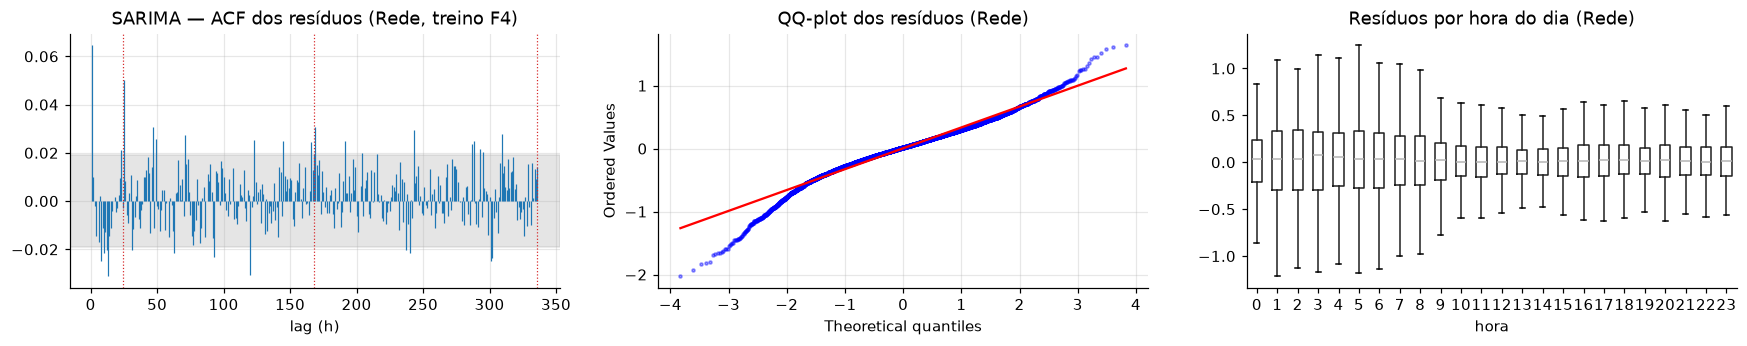

In [26]:
# Diagnóstico de resíduos do SARIMA (D=24) no treino do F4
def fit_on_f4_lv(make_model, level):
    m = make_model()
    m.level = level
    m.fit(Y[level][:n_train_f4].copy())
    return m

RESID_S = {}
for lv in LEVELS:
    m = fit_on_f4_lv(lambda: SARIMAForecaster(BEST_ORD), lv)
    RESID_S[lv] = np.asarray(m.res_.resid)[24 * 10:]    # descarta o arranque do filtro

lb_rows = []
for lv, r in RESID_S.items():
    a = acf(r, nlags=336, fft=True)
    order = BEST_ORD[lv]
    npar = order[0][0] + order[0][2] + order[1][0] + order[1][1]
    lb = acorr_ljungbox(r, lags=[24, 48, 168], model_df=npar)
    lb_rows.append({"nível": lv, "média": r.mean(), "dp": r.std(), "ACF lag 1": a[1], "ACF lag 24": a[24],
                    "ACF lag 168": a[168], "ACF lag 336": a[336], "máx |ACF| (1-336)": np.abs(a[1:]).max(),
                    "LB p (24)": lb["lb_pvalue"].iloc[0], "LB p (48)": lb["lb_pvalue"].iloc[1], "LB p (168)": lb["lb_pvalue"].iloc[2]})
display(pd.DataFrame(lb_rows).set_index("nível").round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
r = RESID_S["Network"]
a = acf(r, nlags=336, fft=True)
axes[0].vlines(range(1, 337), 0, a[1:], color="#1F77B4", lw=0.8)
axes[0].axhspan(-1.96 / np.sqrt(len(r)), 1.96 / np.sqrt(len(r)), color="#AAAAAA", alpha=0.3)
for k in (24, 168, 336):
    axes[0].axvline(k, color="#D62728", ls=":", lw=0.8)
axes[0].set(title="SARIMA — ACF dos resíduos (Rede, treino F4)", xlabel="lag (h)")
stats.probplot(r, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set(markersize=2, alpha=0.4)
axes[1].set_title("QQ-plot dos resíduos (Rede)")
hrs = series.index[n_train_f4 - len(r):n_train_f4].hour
pd.DataFrame({"hora": hrs, "resíduo": r}).boxplot(column="resíduo", by="hora", ax=axes[2], showfliers=False, grid=False)
axes[2].set(title="Resíduos por hora do dia (Rede)", xlabel="hora", ylabel="")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Leitura.**

- **A autocorrelação sazonal desapareceu.** Nos *lags* 24, 168 e 336, o ACF dos resíduos fica entre −0,003 e 0,033, e não há o pico negativo em 24 h que a MSTL deixava. O máximo de $|\text{ACF}|$ nos 336 *lags* é 0,065 na Rede, 0,052 em Tongxiang e menor do que 0,04 em Nanhu e Xiuzhou.
- **Resta uma autocorrelação pequena no *lag* 1** na Rede (0,065) e em Tongxiang (0,052), com média praticamente nula. É a mesma dependência de curto prazo que o ETS deixava, ligeiramente reduzida mas não eliminada pelo ARMA de ordem baixa.
- **O Ljung-Box rejeita ruído branco** em todos os níveis (p < 0,05 em 24, 48 e 168 *lags*, quase sempre p < 0,01). Com mais de 13 000 observações, o teste deteta autocorrelações de 0,03 a 0,06 que não têm efeito prático. Por isso o tamanho das autocorrelações pesa mais do que o p-valor.
- **QQ-plot:** as duas caudas são mais pesadas do que as de uma normal (a esquerda mais), pelas horas noturnas com contagens muito baixas e por dias atípicos. Intervalos de previsão baseados na normal seriam pouco fiáveis nas caudas.
- **Resíduos por hora:** a dispersão é cerca de 1,5 a 2 vezes maior entre as 0h e as 8h (pouco volume, em `log1p`) do que durante o dia. É heterocedasticidade residual da transformação, igual à vista no ETS.

### 5.4 Conclusões das secções 4 e 5

| Modelo | Rede | Nanhu | Tongxiang | Xiuzhou | Bate a referência? |
|---|---|---|---|---|---|
| MédiaHora-7d (referência) | 0,825 | 0,639 | 0,834 | 0,890 | — |
| ETS(A,N,A) | 0,783 | **0,616** | 0,784 | 0,841 | sim, nos 4 níveis |
| **SARIMA (D=24)** | **0,774** | 0,619 | **0,779** | **0,839** | sim, nos 4 níveis |
| SARIMA (D=168) | 1,058 | 0,826 | 1,078 | 1,154 | não |
| SARIMA (D=24 e 168) | 1,064 | 0,827 | 1,086 | 1,160 | não |
| MSTL + ARIMA ($d=0$) | 1,092 | 0,839 | 1,106 | 0,980 | não |
| MSTL + ARIMA ($d=1$) | 1,190 | 0,871 | 0,858 | 0,969 | não |
| ARIMA(2,1,2) sem sazonalidade | 2,182 | 0,967 | 1,849 | 1,562 | não |

*(MASE médio nos 4 folds de validação.)*

- **O SARIMA (D=24) com MA sazonal é o melhor modelo ARIMA.** Reduz o MASE entre 3% e 6% face à referência e fica quase a par do ETS(A,N,A). A identificação pela ACF/PACF (MA sazonal em 24 h mais um ARMA curto) e a validação coincidem.
- **Pontos fortes:** os resíduos ficam quase sem autocorrelação sazonal e o modelo atualiza o perfil diário a cada dia. **Limitações:** só diferencia a 24 h (o ciclo semanal não entra) e leva alguns segundos por ajuste (8 a 12 s por *fold*, contra milissegundos do ETS).
- **O que não funcionou:** diferenciação a 168 h, dupla diferenciação, MSTL + ARIMA e o ARIMA não sazonal.

**Para a secção 6:** o SARIMA (D=24) é a base do SARIMAX. O que lhe falta, e que o ETS também não tem, são os efeitos de calendário e a possível ajuda da meteorologia.

## 6. SARIMAX com variáveis exógenas

### 6.1 Formulação e variáveis

O SARIMAX acrescenta ao SARIMA uma regressão com **erros ARMA sazonais**:

$$w_t=\beta^\top x_t^{(w)}+\eta_t,\qquad \eta_t\sim\text{SARMA}(p,q)(P,Q)_{24}$$

onde $x^{(w)}$ são as variáveis exógenas sujeitas à **mesma diferenciação** de $z$ (para a regressão ser coerente com o modelo diferenciado: o efeito do feriado passa a ser a diferença entre o dia e o mesmo dia da véspera). Mantém-se a ordem ARMA da secção 4.3.

**Variáveis (classificação da Task 1, secção 4.3):**

| Grupo | Variáveis | Disponibilidade em $T_0$ | Uso |
|---|---|---|---|
| Calendário (futuro conhecido) | fim de semana (sábado e domingo, exceto dias de compensação), feriado, véspera de feriado, dia seguinte a feriado | conhecidas para qualquer data | **sim** (`cal`) |
| Meteorologia até $D-1$ | temperatura, humidade, precipitação do dia $D-1$ | hipótese operacional: o resumo de $D-1$ chega antes das 00:00 de $D$ | testa-se (`cal+meteo D-1`) |
| Meteorologia até $D-2$ | as mesmas, com um dia extra de atraso | cobre o caso de o resumo chegar mais tarde | **sensibilidade** obrigatória do protocolo |
| Meteorologia do dia $D$ | as mesmas | **não existe em $T_0$** | só **oráculo diagnóstico**, nunca entra na seleção |

A meteorologia é padronizada com a média e o desvio do treino de cada *fold*. Nos distritos usa-se a do próprio distrito, e na Rede a média dos três.

**Regra de adoção.** Uma exógena só entra no modelo final se melhorar a validação de forma estatisticamente clara (IC 95% da diferença pareada de MASE diário a excluir zero), como previsto no protocolo.

In [27]:
# Variáveis exógenas: calendário (futuro conhecido) e meteorologia (só desfasada, nunca o dia D)
MAKEUP = DAYS.isin(pd.DatetimeIndex(PROTOCOL["makeup_workdays"]))
HOL = np.asarray(DAYS.isin(HOLIDAY_DAYS))
WKND = np.asarray((DAYS.dayofweek >= 5) & ~MAKEUP)          # fim de semana efetivo (dias de compensação contam como úteis)
PRE = np.r_[HOL[1:], False] & ~HOL
POST = np.r_[False, HOL[:-1]] & ~HOL
CAL_NAMES = ["fim_de_semana", "feriado", "véspera", "dia_seguinte"]
CAL_DAY = np.column_stack([WKND, HOL, PRE, POST]).astype(float)

wx = weather_daily.pivot(index="date", columns="district", values=["temp", "rh", "prec"]).reindex(DAYS).ffill().bfill()
WX_NAMES = ["temp", "rh", "prec"]
WX_DAY = {lv: wx.xs(lv, axis=1, level=1)[WX_NAMES].to_numpy() for lv in DISTRICTS}
WX_DAY["Network"] = np.mean([WX_DAY[lv] for lv in DISTRICTS], axis=0)

def lag_days(a, k):
    out = np.empty_like(a)
    out[k:] = a[:len(a) - k] if k else a
    out[:k] = a[0]
    return out

def build_exog(level, spec):
    # spec: (calendário?, atraso da meteorologia em dias ou None). O atraso 0 (dia D) é só o oráculo diagnóstico.
    cal, wlag = spec
    cols, names = [], []
    if cal:
        cols.append(CAL_DAY); names += CAL_NAMES
    if wlag is not None:
        cols.append(lag_days(WX_DAY[level], wlag)); names += [f"{n}_D-{wlag}" if wlag else f"{n}_D" for n in WX_NAMES]
    X = np.repeat(np.hstack(cols), 24, axis=0)
    return X, names, [i for i, n in enumerate(names) if n.split("_")[0] in WX_NAMES]

EXOG_SPECS = {"cal": (True, None), "cal+meteo D-1": (True, 1), "cal+meteo D-2": (True, 2), "cal+meteo D (oráculo)": (True, 0)}
EXOG = {(lv, k): build_exog(lv, s) for lv in LEVELS for k, s in EXOG_SPECS.items()}

# Verificação de alinhamento: com atraso 1, a meteorologia usada nas 24 h do dia D é a do dia D-1 (known_at <= 00:00 de D)
lv, k = "Nanhu", "cal+meteo D-1"
X, names, wi = EXOG[(lv, k)]
d = pd.Timestamp("2021-03-10")
row = X[day_idx(d) * 24, wi]
src = weather_daily[(weather_daily.district == lv) & (weather_daily.date == d - pd.Timedelta(days=1))][WX_NAMES].to_numpy()[0]
assert np.allclose(row, src) and (weather_daily[(weather_daily.district == lv) & (weather_daily.date == d - pd.Timedelta(days=1))]["known_at"] <= d).all()
print("Alinhamento verificado: no dia", d.date(), "as variáveis meteorológicas são as de", (d - pd.Timedelta(days=1)).date(), "(known_at <= origem).")
print("Colunas:", EXOG[("Network", "cal+meteo D-1")][1])

Alinhamento verificado: no dia 2021-03-10 as variáveis meteorológicas são as de 2021-03-09 (known_at <= origem).
Colunas: ['fim_de_semana', 'feriado', 'véspera', 'dia_seguinte', 'temp_D-1', 'rh_D-1', 'prec_D-1']


**Leitura.** A verificação confirma que, para o dia $D$, as variáveis meteorológicas usadas são as do dia $D-1$ e que o seu `known_at` é anterior ou igual à origem. Por causa da diferenciação em 24 h, em cada hora do dia $D$ o modelo usa também a meteorologia de $D-2$, que está igualmente disponível. A versão do dia $D$ só se constrói para o oráculo.

In [28]:
for nm, key in [("SARIMAX cal", "cal"), ("SARIMAX cal+meteo D-1", "cal+meteo D-1"),
                ("SARIMAX cal+meteo D-2", "cal+meteo D-2"), ("SARIMAX cal+meteo D (oráculo)", "cal+meteo D (oráculo)")]:
    run_model(nm, lambda key=key: SARIMAForecaster(BEST_ORD, exog=key))
S6_SET = ["SARIMAX cal", "SARIMAX cal+meteo D-1", "SARIMAX cal+meteo D-2", "SARIMAX cal+meteo D (oráculo)"]
tbl6 = show_summary(["ETS(A,N,A)", "MediaHora-7d", "SARIMA (D=24)"] + S6_SET, cols=cols)
print("MASE por fold")
display(fold_table(["ETS(A,N,A)", "MediaHora-7d", "SARIMA (D=24)"] + S6_SET).round(3))

SARIMAX cal: 16 ajustes (nível × fold) em 110.1 s


SARIMAX cal+meteo D-1: 16 ajustes (nível × fold) em 187.7 s


SARIMAX cal+meteo D-2: 16 ajustes (nível × fold) em 184.3 s


SARIMAX cal+meteo D (oráculo): 16 ajustes (nível × fold) em 241.1 s
--- Network ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMA (D=24),5.409,7.529,0.774,0.104,0.893,-0.052,-0.070,-0.037,4.000,sim,8.478,3.952
SARIMAX cal,5.426,7.529,0.776,0.100,0.897,-0.050,-0.069,-0.035,4.000,sim,35.833,7.927
SARIMAX cal+meteo D-2,5.446,7.587,0.779,0.104,0.896,-0.047,-0.071,-0.028,4.000,sim,67.504,8.438
"ETS(A,N,A)",5.476,7.622,0.783,0.096,0.890,-0.042,-0.060,-0.027,4.000,sim,0.012,11.711
SARIMAX cal+meteo D-1,5.571,7.846,0.796,0.111,0.899,-0.029,-0.051,-0.009,3.000,sim,58.509,8.609
SARIMAX cal+meteo D (oráculo),5.637,7.940,0.806,0.119,0.900,-0.020,-0.045,0.007,3.000,não,61.261,8.640
MediaHora-7d,5.772,7.965,0.825,0.103,0.933,NaN,NaN,NaN,NaN,NaN,0.000,0.006


--- Nanhu ---


... (3 outputs left out)

--- Xiuzhou ---


,MAE,RMSE,MASE,MASE_dp,MASE_pior,Δ_MASE_vs_ref,IC_inf,IC_sup,folds_ganhos,melhor_que_ref,ajuste_s,ms_origem
model,,,,,,,,,,,,
SARIMAX cal+meteo D-2,3.222,4.583,0.834,0.160,1.009,-0.056,-0.070,-0.045,4.000,sim,90.653,5.992
SARIMAX cal,3.225,4.585,0.835,0.159,1.008,-0.055,-0.068,-0.044,4.000,sim,52.982,4.684
SARIMAX cal+meteo D-1,3.239,4.612,0.839,0.157,1.008,-0.051,-0.064,-0.040,4.000,sim,88.573,5.738
SARIMAX cal+meteo D (oráculo),3.240,4.612,0.839,0.155,1.007,-0.051,-0.064,-0.040,4.000,sim,114.476,5.863
SARIMA (D=24),3.242,4.627,0.839,0.163,1.010,-0.050,-0.064,-0.038,4.000,sim,11.596,2.436
"ETS(A,N,A)",3.247,4.611,0.841,0.161,1.012,-0.049,-0.060,-0.038,4.000,sim,0.029,8.070
MediaHora-7d,3.436,4.738,0.890,0.161,1.058,NaN,NaN,NaN,NaN,NaN,0.000,0.006


MASE por fold


fold                                       F1    F2    F3    F4
level     model                                                
Network   ETS(A,N,A)                    0.798 0.656 0.789 0.890
          MediaHora-7d                  0.847 0.685 0.836 0.933
          SARIMA (D=24)                 0.785 0.640 0.777 0.893
          SARIMAX cal                   0.787 0.652 0.767 0.897
          SARIMAX cal+meteo D (oráculo) 0.899 0.653 0.769 0.900
          SARIMAX cal+meteo D-1         0.865 0.651 0.769 0.899
          SARIMAX cal+meteo D-2         0.807 0.646 0.767 0.896
Nanhu     ETS(A,N,A)                    0.671 0.495 0.536 0.764
          MediaHora-7d                  0.699 0.527 0.560 0.769
          SARIMA (D=24)                 0.671 0.493 0.537 0.773
          SARIMAX cal                   0.672 0.501 0.535 0.770
          SARIMAX cal+meteo D (oráculo) 0.683 0.501 0.535 0.769
          SARIMAX cal+meteo D-1         0.678 0.502 0.534 0.768
          SARIMAX cal+meteo D-2         0.673 0.501 0.534 0.770
Tongxiang ETS(A,N,A)                    0.861 0.669 0.754 0.854
          MediaHora-7d                  0.922 0.701 0.800 0.915
          SARIMA (D=24)                 0.855 0.661 0.746 0.855
          SARIMAX cal                   0.860 0.670 0.741 0.858
          SARIMAX cal+meteo D (oráculo) 0.907 0.669 0.751 0.861
          SARIMAX cal+meteo D-1         0.893 0.669 0.741 0.859
          SARIMAX cal+meteo D-2         0.859 0.655 0.742 0.858
Xiuzhou   ETS(A,N,A)                    0.758 0.659 0.934 1.012
          MediaHora-7d                  0.807 0.707 0.988 1.058
          SARIMA (D=24)                 0.754 0.655 0.938 1.010
          SARIMAX cal                   0.752 0.658 0.922 1.008
          SARIMAX cal+meteo D (oráculo) 0.771 0.657 0.919 1.007
          SARIMAX cal+meteo D-1         0.767 0.656 0.923 1.008
          SARIMAX cal+meteo D-2         0.750 0.657 0.919 1.009

**Leitura.**

- **O calendário não melhora o SARIMA de forma geral.** O SARIMAX `cal` tem MASE 0,776, 0,619, 0,782 e 0,835 (Rede, Nanhu, Tongxiang e Xiuzhou), praticamente igual ao SARIMA sem exógenas (0,774, 0,619, 0,779, 0,839).
- **A meteorologia piora o resultado.** Com o atraso de 1 dia, o MASE na Rede sobe de 0,776 para 0,796, e o IC da diferença pareada exclui zero **a favor do modelo sem meteorologia** na Rede, em Tongxiang e em Xiuzhou. Com o atraso de 2 dias, a diferença não é distinguível de zero. O **oráculo** (meteorologia do próprio dia, que não se pode usar) piora ainda mais (0,806 na Rede). Não há, portanto, valor preditivo na meteorologia, nem sequer com informação perfeita.
- **Onde se perde:** o F1 (2020-Q4) concentra a perda da Rede (0,865 com o atraso de 1 dia, contra 0,787 sem meteorologia). Os coeficientes foram estimados em 2020 de abril a setembro (verão), e extrapolam mal para o outono. Isto indica **sobreajuste** a um sinal fraco (|ρ| ≤ 0,16 na Task 1, um único valor por dia e por distrito), e não que a meteorologia não influencie fisicamente a procura.
- **Custo:** o SARIMAX demora de 34 a 51 s por *fold* só com calendário e de 58 a 90 s com meteorologia, contra 8 a 12 s do SARIMA e 0,01 a 0,03 s do ETS.

In [29]:
def paired_vs(model, base):
    rows = {}
    for lv in LEVELS:
        a = RESULTS[model]["res_d"].query("level == @lv").set_index("day")["MASE_dia"].sort_index()
        b = RESULTS[base]["res_d"].query("level == @lv").set_index("day")["MASE_dia"].sort_index()
        diff = (a - b).to_numpy()
        lo, hi = paired_ci(diff)
        rows[lv] = f"{diff.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]" + (" *" if hi < 0 or lo > 0 else "")
    return rows

pairs = [("SARIMAX cal", "SARIMA (D=24)"), ("SARIMAX cal+meteo D-1", "SARIMAX cal"), ("SARIMAX cal+meteo D-2", "SARIMAX cal"),
         ("SARIMAX cal+meteo D (oráculo)", "SARIMAX cal")]
tab = pd.DataFrame({f"{m}  vs  {b}": paired_vs(m, b) for m, b in pairs}).T[LEVELS]
print("Diferença pareada de MASE diário (modelo − base) [IC 95%, bootstrap de blocos de 7 dias]; * = IC exclui zero")
display(tab)

Diferença pareada de MASE diário (modelo − base) [IC 95%, bootstrap de blocos de 7 dias]; * = IC exclui zero


,Network,Nanhu,Tongxiang,Xiuzhou
SARIMAX cal vs SARIMA (D=24),"+0.0023 [-0.0031, +0.0067]","+0.0007 [-0.0019, +0.0037]","+0.0029 [-0.0012, +0.0072]","-0.0046 [-0.0107, -0.0005] *"
SARIMAX cal+meteo D-1 vs SARIMAX cal,"+0.0204 [+0.0074, +0.0360] *","+0.0010 [-0.0004, +0.0025]","+0.0083 [+0.0017, +0.0172] *","+0.0038 [+0.0007, +0.0073] *"
SARIMAX cal+meteo D-2 vs SARIMAX cal,"+0.0029 [-0.0072, +0.0126]","+0.0003 [-0.0013, +0.0019]","-0.0036 [-0.0106, +0.0010]","-0.0007 [-0.0024, +0.0008]"
SARIMAX cal+meteo D (oráculo) vs SARIMAX cal,"+0.0298 [+0.0123, +0.0528] *","+0.0027 [+0.0006, +0.0057] *","+0.0148 [+0.0064, +0.0267] *","+0.0040 [+0.0003, +0.0091] *"


In [30]:
# Coeficientes estimados (escala log1p: efeito multiplicativo aproximado sobre as sessões) em cada fold
rows = []
for nm in ["SARIMAX cal", "SARIMAX cal+meteo D-1"]:
    inf = RESULTS[nm]["info"]
    for lv in LEVELS:
        sub = inf[inf.level == lv]
        for c in CAL_NAMES + [f"{n}_D-1" for n in WX_NAMES]:
            if c in sub:
                v = sub[c].dropna()
                if len(v):
                    rows.append({"modelo": nm, "nível": lv, "variável": c, "média": v.mean(), "mín": v.min(), "máx": v.max()})
display(pd.DataFrame(rows).pivot_table(index=["nível", "variável"], columns="modelo", values="média").reindex(LEVELS, level=0).round(3))

modelo                   SARIMAX cal  SARIMAX cal+meteo D-1
nível     variável                                         
Network   dia_seguinte         0.061                  0.048
          feriado              0.141                  0.120
          fim_de_semana        0.029                  0.037
          prec_D-1               NaN                  0.009
          rh_D-1                 NaN                 -0.002
          temp_D-1               NaN                  0.060
          véspera              0.112                  0.117
Nanhu     dia_seguinte        -0.021                 -0.013
          feriado              0.085                  0.077
          fim_de_semana        0.021                  0.026
          prec_D-1               NaN                  0.004
          rh_D-1                 NaN                 -0.011
          temp_D-1               NaN                  0.036
          véspera              0.169                  0.171
Tongxiang dia_seguinte         0.076                  0.073
          feriado              0.102                  0.093
          fim_de_semana        0.044                  0.044
          prec_D-1               NaN                  0.002
          rh_D-1                 NaN                  0.018
          temp_D-1               NaN                  0.040
          véspera              0.110                  0.112
Xiuzhou   dia_seguinte        -0.001                  0.007
          feriado              0.168                  0.147
          fim_de_semana        0.021                  0.028
          prec_D-1               NaN                  0.006
          rh_D-1                 NaN                 -0.011
          temp_D-1               NaN                  0.060
          véspera              0.152                  0.147

In [31]:
# Efeito do calendário: MASE em dias de feriado, dias normais e fins de semana
rows = []
for n in ["MediaHora-7d", "ETS(A,N,A)", "SARIMA (D=24)", "SARIMAX cal", "SARIMAX cal+meteo D-1"]:
    rd = RESULTS[n]["res_d"]
    tipo = np.where(rd["day"].isin(HOLIDAY_DAYS), "feriado", np.where(rd["day"].dt.dayofweek >= 5, "fim de semana", "dia útil"))
    rows.append(rd.assign(tipo=tipo).groupby(["level", "tipo"])["MASE_dia"].mean().rename(n))
display(pd.concat(rows, axis=1).reindex(LEVELS, level=0).round(3))

MediaHora-7d  ETS(A,N,A)  SARIMA (D=24)  SARIMAX cal  SARIMAX cal+meteo D-1
level     tipo                                                                                      
Network   dia útil              0.829       0.775          0.773        0.774                  0.802
          feriado               0.892       0.867          0.815        0.840                  0.839
          fim de semana         0.797       0.779          0.764        0.761                  0.768
Nanhu     dia útil              0.641       0.615          0.617        0.617                  0.619
          feriado               0.651       0.644          0.640        0.650                  0.647
          fim de semana         0.632       0.615          0.620        0.617                  0.617
Tongxiang dia útil              0.836       0.775          0.774        0.775                  0.787
          feriado               0.866       0.833          0.811        0.829                  0.838
          fim de semana         0.823       0.794          0.786        0.788                  0.786
Xiuzhou   dia útil              0.882       0.834          0.830        0.828                  0.832
          feriado               0.936       0.886          0.905        0.878                  0.884
          fim de semana         0.896       0.846          0.844        0.840                  0.842

**Leitura.**

- **Coeficientes do calendário** (efeito aproximado sobre o log das sessões, média dos 4 *folds*): **feriado +0,09 a +0,17** (+9% a +18%), **véspera de feriado +0,11 a +0,17**, fim de semana pequeno (+0,02 a +0,04) e dia seguinte ao feriado inconsistente (−0,02 a +0,08). Os sinais coincidem com a Task 1 (a procura sobe em feriados e vésperas) e os valores são parecidos entre níveis. A meteorologia tem coeficientes pequenos, com a temperatura sempre positiva (+0,04 a +0,06).
- **Feriados:** o maior ganho nos dias de feriado vem **do próprio SARIMA**, e não das variáveis de calendário. Na Rede, o MASE nos feriados passa de 0,867 (ETS) para 0,815 (SARIMA), e as variáveis de calendário não o baixam mais (0,840). A razão é que o modelo diferenciado parte do valor de ontem, por isso em feriados de vários dias se adapta a partir do segundo dia, e a variável só pesa nos dias de transição. Em Xiuzhou, a variável ajuda (0,878 contra 0,905 do SARIMA nos feriados), e é essa a única melhoria estatisticamente clara do calendário (diferença de −0,0046 no MASE diário, IC [−0,0107; −0,0005]).
- **Fins de semana:** todos os modelos de 24 h tratam-nos tão bem como os dias úteis (MASE de 0,76 a 0,78 na Rede, contra 0,77 em dias úteis), o que mostra que o ciclo semanal é fraco e o ciclo diário o absorve.

**Implicação:** o calendário só justifica o custo adicional num nível (Xiuzhou), e a meteorologia nunca. A seleção final por nível (secção 7) aplica a regra de adoção.

## 7. Comparação global dos modelos estatísticos

Comparam-se agora todos os modelos desta Task e as *baselines*, no mesmo motor, nos mesmos 4 *folds* de validação (o teste continua intocado) e nos quatro níveis.

**Seleção por nível.** Aplica-se a regra do protocolo (MASE médio menor do que a MédiaHora-7d, melhor em pelo menos 3 de 4 *folds* e IC 95% da diferença pareada a excluir zero) e, entre os modelos que a cumprem, usa-se um critério de parcimónia: uma estrutura mais complexa só substitui a anterior se for **claramente melhor** (IC 95% da diferença pareada de MASE diário a excluir zero). A ordem de complexidade é ETS(A,N,A) → SARIMA (D=24) → SARIMAX com calendário → SARIMAX com calendário e meteorologia. Isto evita escolher um modelo mais caro por uma diferença na terceira casa decimal.

MASE médio nos 4 folds (menor é melhor); oráculo excluído da comparação


level,Network,Nanhu,Tongxiang,Xiuzhou,média
model,,,,,
SARIMA (D=24),0.774,0.619,0.779,0.839,0.753
SARIMAX cal+meteo D-2,0.779,0.620,0.779,0.834,0.753
SARIMAX cal,0.776,0.619,0.782,0.835,0.753
"ETS(A,N,A)",0.783,0.616,0.784,0.841,0.756
SARIMAX cal+meteo D-1,0.796,0.620,0.790,0.839,0.761
"ETS(A,N,A) m=168",0.805,0.639,0.800,0.856,0.775
MediaHora-7d,0.825,0.639,0.834,0.890,0.797
MSTL + ETS (4 sem),0.847,0.696,0.860,0.911,0.828
MSTL + ARIMA d=1,1.190,0.871,0.858,0.969,0.972


Cumpre a regra de seleção face à MédiaHora-7d?


level,Network,Nanhu,Tongxiang,Xiuzhou
model,,,,
SNaive-24,não,não,não,não
"ETS(A,N,A)",sim,sim,sim,sim
"ETS(A,N,A) m=168",sim,não,sim,sim
MSTL + ETS (4 sem),não,não,não,não
"ARIMA(2,1,2) sem sazonalidade",não,não,não,não
SARIMA (D=24),sim,sim,sim,sim
SARIMA (D=168),não,não,não,não
SARIMA (D=24 e 168),não,não,não,não
MSTL + ARIMA d=0,não,não,não,não


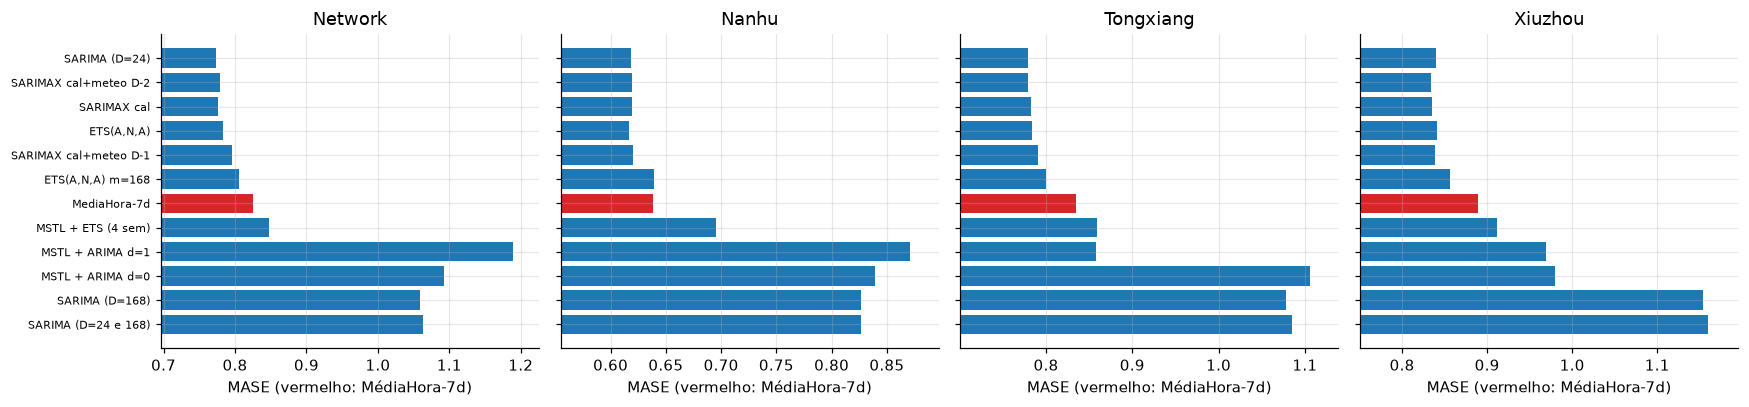

In [32]:
STAT_MODELS = ["SNaive-24", "MediaHora-7d", "ETS(A,N,A)", "ETS(A,N,A) m=168", "MSTL + ETS (4 sem)",
               "ARIMA(2,1,2) sem sazonalidade", "SARIMA (D=24)", "SARIMA (D=168)", "SARIMA (D=24 e 168)", "MSTL + ARIMA d=0", "MSTL + ARIMA d=1",
               "SARIMAX cal", "SARIMAX cal+meteo D-1", "SARIMAX cal+meteo D-2"]
global_tbl = summarize(STAT_MODELS)
mase_piv = global_tbl.pivot(index="model", columns="level", values="MASE")[LEVELS].loc[STAT_MODELS]
mase_piv["média"] = mase_piv.mean(axis=1)
print("MASE médio nos 4 folds (menor é melhor); oráculo excluído da comparação")
display(mase_piv.sort_values("média").round(3))

rule_piv = global_tbl.pivot(index="model", columns="level", values="melhor_que_ref")[LEVELS].loc[[m for m in STAT_MODELS if m != "MediaHora-7d"]]
print("Cumpre a regra de seleção face à MédiaHora-7d?")
display(rule_piv)

fig, ax = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
order_models = [m for m in STAT_MODELS if m not in ("SNaive-24", "ARIMA(2,1,2) sem sazonalidade")]
rank = mase_piv.loc[order_models, "média"].sort_values().index.tolist()   # mesma ordem em todos os painéis
for a, lv in zip(ax, LEVELS):
    v = mase_piv.loc[rank, lv]
    a.barh(range(len(v)), v.values, color=["#D62728" if n == "MediaHora-7d" else "#1F77B4" for n in v.index])
    a.set_yticks(range(len(v)))
    a.set_yticklabels(v.index if lv == "Network" else [""] * len(v), fontsize=7)
    a.set(title=lv, xlabel="MASE (vermelho: MédiaHora-7d)")
    a.set_xlim(v.min() * 0.9, v.max() * 1.03)
    a.invert_yaxis()
plt.tight_layout()
plt.show()

**Leitura.**

- **Quatro grupos.** (i) ETS(A,N,A), SARIMA (D=24) e SARIMAX com calendário: praticamente iguais entre si (MASE médio de 0,753 a 0,756 entre os quatro níveis) e todos acima da referência. (ii) Os modelos que tentam incluir o ciclo semanal (ETS m=168) ficam entre a referência e o grupo anterior. (iii) As variantes de MSTL e a diferenciação a 168 h ficam piores do que a referência. (iv) O ARIMA não sazonal falha por completo.
- **Regra de seleção:** ETS(A,N,A), SARIMA (D=24) e os três SARIMAX bateram a referência nos quatro níveis. O ETS m=168 só não bate em Nanhu. As variantes de MSTL, a diferenciação semanal e o ARIMA não sazonal não a cumprem em nenhum nível.
- **O ganho sobre a referência é de 3,5% a 7%** nos melhores modelos, e é consistente: o IC 95% da diferença pareada exclui zero nos quatro níveis para os três melhores grupos.

In [33]:
# Seleção por nível. Regra do protocolo: o modelo tem de bater a referência (MASE médio, >= 3 de 4 folds, IC da diferença pareada < 0).
# Entre os modelos que a cumprem, uma estrutura mais complexa só substitui a anterior se melhorar de forma
# estatisticamente clara (IC 95% da diferença pareada de MASE diário a excluir zero). Ordem de complexidade:
# ETS(A,N,A) -> SARIMA (D=24) -> SARIMAX com calendário -> SARIMAX com calendário + meteorologia (D-1).
# A versão com atraso de 2 dias é só sensibilidade, e o oráculo nunca participa.
cand = [m for m in STAT_MODELS if m not in ("SNaive-24", "MediaHora-7d", "ARIMA(2,1,2) sem sazonalidade")]
CHAIN = ["ETS(A,N,A)", "SARIMA (D=24)", "SARIMAX cal", "SARIMAX cal+meteo D-1"]
FINAL, rows = {}, []
for lv in LEVELS:
    cur = CHAIN[0]
    steps = []
    for nxt in CHAIN[1:]:
        a = RESULTS[nxt]["res_d"].query("level == @lv").set_index("day")["MASE_dia"].sort_index()
        b = RESULTS[cur]["res_d"].query("level == @lv").set_index("day")["MASE_dia"].sort_index()
        diff = (a - b).to_numpy()
        lo, hi = paired_ci(diff)
        passes = global_tbl[(global_tbl.level == lv) & (global_tbl.model == nxt)]["melhor_que_ref"].iloc[0] == "sim"
        take = bool(hi < 0 and passes)
        steps.append(f"{nxt} vs {cur}: {diff.mean():+.4f} [{lo:+.4f}, {hi:+.4f}] -> {'adota' if take else 'mantém'}")
        if take:
            cur = nxt
    FINAL[lv] = cur
    t = global_tbl[(global_tbl.level == lv) & global_tbl.model.isin(cand)].sort_values("MASE")
    rows.append({"nível": lv, "melhor MASE (sem parcimónia)": t.iloc[0]["model"], "modelo selecionado": cur,
                 "MASE selecionado": t.set_index("model").loc[cur, "MASE"],
                 "MASE ref.": global_tbl[(global_tbl.level == lv) & (global_tbl.model == "MediaHora-7d")]["MASE"].iloc[0]})
    print(f"{lv}:", " | ".join(steps))
display(pd.DataFrame(rows).set_index("nível").round(3))

# Diferença pareada de cada modelo face ao ETS(A,N,A) (o melhor modelo da secção 3)
rows = []
for n in [m for m in cand if m != "ETS(A,N,A)"]:
    for lv in LEVELS:
        a = RESULTS[n]["res_d"].query("level == @lv").set_index("day")["MASE_dia"].sort_index()
        b = RESULTS["ETS(A,N,A)"]["res_d"].query("level == @lv").set_index("day")["MASE_dia"].sort_index()
        diff = (a - b).to_numpy()
        lo, hi = paired_ci(diff)
        rows.append({"modelo": n, "nível": lv, "Δ MASE vs ETS(A,N,A)": diff.mean(), "IC_inf": lo, "IC_sup": hi,
                     "melhor que ETS": "sim" if hi < 0 else ("pior" if lo > 0 else "indistinguível")})
display(pd.DataFrame(rows).pivot(index="modelo", columns="nível", values="melhor que ETS")[LEVELS])
dd = pd.DataFrame(rows).pivot(index="modelo", columns="nível", values="Δ MASE vs ETS(A,N,A)")[LEVELS]
display(dd.round(3))

Network: SARIMA (D=24) vs ETS(A,N,A): -0.0095 [-0.0196, -0.0008] -> adota | SARIMAX cal vs SARIMA (D=24): +0.0023 [-0.0031, +0.0067] -> mantém | SARIMAX cal+meteo D-1 vs SARIMA (D=24): +0.0227 [+0.0078, +0.0388] -> mantém


Nanhu: SARIMA (D=24) vs ETS(A,N,A): +0.0022 [-0.0010, +0.0055] -> mantém | SARIMAX cal vs ETS(A,N,A): +0.0029 [-0.0011, +0.0071] -> mantém | SARIMAX cal+meteo D-1 vs ETS(A,N,A): +0.0039 [-0.0001, +0.0084] -> mantém
Tongxiang: SARIMA (D=24) vs ETS(A,N,A): -0.0049 [-0.0088, -0.0017] -> adota | SARIMAX cal vs SARIMA (D=24): +0.0029 [-0.0012, +0.0072] -> mantém | SARIMAX cal+meteo D-1 vs SARIMA (D=24): +0.0112 [+0.0021, +0.0216] -> mantém
Xiuzhou: SARIMA (D=24) vs ETS(A,N,A): -0.0013 [-0.0050, +0.0026] -> mantém | SARIMAX cal vs ETS(A,N,A): -0.0059 [-0.0109, -0.0025] -> adota | SARIMAX cal+meteo D-1 vs SARIMAX cal: +0.0038 [+0.0007, +0.0073] -> mantém


,melhor MASE (sem parcimónia),modelo selecionado,MASE selecionado,MASE ref.
nível,,,,
Network,SARIMA (D=24),SARIMA (D=24),0.774,0.825
Nanhu,"ETS(A,N,A)","ETS(A,N,A)",0.616,0.639
Tongxiang,SARIMAX cal+meteo D-2,SARIMA (D=24),0.779,0.834
Xiuzhou,SARIMAX cal+meteo D-2,SARIMAX cal,0.835,0.890


nível,Network,Nanhu,Tongxiang,Xiuzhou
modelo,,,,
"ETS(A,N,A) m=168",pior,pior,pior,pior
MSTL + ARIMA d=0,pior,pior,pior,pior
MSTL + ARIMA d=1,pior,pior,pior,pior
MSTL + ETS (4 sem),pior,pior,pior,pior
SARIMA (D=168),pior,pior,pior,pior
SARIMA (D=24 e 168),pior,pior,pior,pior
SARIMA (D=24),sim,indistinguível,sim,indistinguível
SARIMAX cal,indistinguível,indistinguível,indistinguível,sim
SARIMAX cal+meteo D-1,indistinguível,indistinguível,indistinguível,indistinguível


nível,Network,Nanhu,Tongxiang,Xiuzhou
modelo,,,,
"ETS(A,N,A) m=168",0.022,0.023,0.016,0.016
MSTL + ARIMA d=0,0.309,0.224,0.320,0.139
MSTL + ARIMA d=1,0.406,0.254,0.074,0.129
MSTL + ETS (4 sem),0.064,0.079,0.075,0.071
SARIMA (D=168),0.276,0.210,0.294,0.314
SARIMA (D=24 e 168),0.281,0.211,0.302,0.320
SARIMA (D=24),-0.009,0.002,-0.005,-0.001
SARIMAX cal,-0.007,0.003,-0.002,-0.006
SARIMAX cal+meteo D-1,0.013,0.004,0.006,-0.002


**Leitura.**

- **Modelos selecionados (parcimónia):** **SARIMA (D=24)** na Rede e em Tongxiang, **ETS(A,N,A)** em Nanhu e **SARIMAX com calendário** em Xiuzhou. Em Nanhu, nem o SARIMA nem o SARIMAX melhoram o ETS (diferenças de +0,002 e +0,003, ICs a incluir zero). Em Xiuzhou, o SARIMAX com calendário é a primeira estrutura que melhora o ETS de forma clara.
- **Sem parcimónia, o SARIMAX com meteorologia atrasada 2 dias teria o menor MASE em Tongxiang e Xiuzhou**, por 0,000 e 0,001 de diferença face ao modelo selecionado, com um ajuste bastante mais lento (66 a 90 s por *fold*). Os testes pareados da secção 6 não mostram diferenças claras face ao SARIMAX com calendário.
- **Em Xiuzhou**, o SARIMAX com calendário melhora o ETS de forma clara (−0,006, IC [−0,011; −0,003]). A versão com meteorologia de $D-2$ também, mas não melhora a de calendário.
- **Em termos de erro, as diferenças entre os modelos selecionados e o ETS são pequenas** (menos de 0,01 de MASE). O que a Task 2 mostra é que, com este tipo de dados, **modelar bem o ciclo diário e atualizar o perfil a cada dia** (ETS ou SARIMA) captura quase todo o ganho possível para um modelo estatístico, e que modelos mais complexos acrescentam pouco.
- **Tabela de diferenças vs ETS:** os modelos de ciclo semanal, MSTL e ARIMA não sazonal são piores com IC a excluir zero. O SARIMA é melhor na Rede e em Tongxiang.

Modelos mostrados: ['ETS(A,N,A)', 'MediaHora-7d', 'SARIMA (D=24)', 'SARIMAX cal']


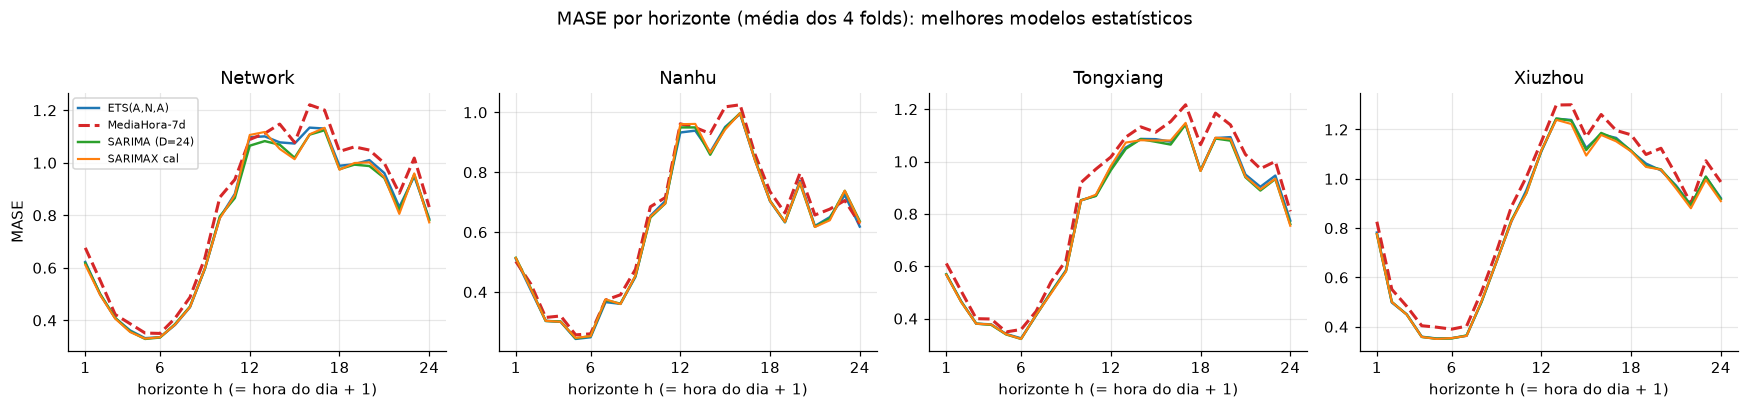

Δ MASE h=1-6  Δ MASE h=7-24  horizontes em que ganha
modelo        nível                                                          
ETS(A,N,A)    Network          -0.030         -0.046                       23
              Nanhu            -0.011         -0.026                       22
              Tongxiang        -0.027         -0.058                       24
              Xiuzhou          -0.043         -0.051                       24
SARIMA (D=24) Network          -0.032         -0.058                       24
              Nanhu            -0.009         -0.024                       19
              Tongxiang        -0.028         -0.064                       24
              Xiuzhou          -0.044         -0.053                       24
SARIMAX cal   Network          -0.034         -0.055                       22
              Nanhu            -0.009         -0.023                       19
              Tongxiang        -0.028         -0.060                       24
              Xiuzhou          -0.044         -0.059                       24

pico_acerto                         pico_MAE                        
                  Network Nanhu Tongxiang Xiuzhou  Network Nanhu Tongxiang Xiuzhou
model                                                                             
ETS(A,N,A)          0.526 0.438     0.477   0.392    9.865 4.292     6.585   7.694
MediaHora-7d        0.501 0.446     0.422   0.383    8.689 3.245     5.564   6.124
SARIMA (D=24)       0.523 0.435     0.480   0.394    9.955 4.346     6.708   7.996
SARIMAX cal         0.521 0.433     0.483   0.397    9.942 4.315     6.726   7.884

Estabilidade temporal: MASE por fold dos modelos selecionados


fold                       F1    F2    F3    F4
level     model                                
Network   ETS(A,N,A)    0.798 0.656 0.789 0.890
          MediaHora-7d  0.847 0.685 0.836 0.933
          SARIMA (D=24) 0.785 0.640 0.777 0.893
          SARIMAX cal   0.787 0.652 0.767 0.897
Nanhu     ETS(A,N,A)    0.671 0.495 0.536 0.764
          MediaHora-7d  0.699 0.527 0.560 0.769
          SARIMA (D=24) 0.671 0.493 0.537 0.773
          SARIMAX cal   0.672 0.501 0.535 0.770
Tongxiang ETS(A,N,A)    0.861 0.669 0.754 0.854
          MediaHora-7d  0.922 0.701 0.800 0.915
          SARIMA (D=24) 0.855 0.661 0.746 0.855
          SARIMAX cal   0.860 0.670 0.741 0.858
Xiuzhou   ETS(A,N,A)    0.758 0.659 0.934 1.012
          MediaHora-7d  0.807 0.707 0.988 1.058
          SARIMA (D=24) 0.754 0.655 0.938 1.010
          SARIMAX cal   0.752 0.658 0.922 1.008

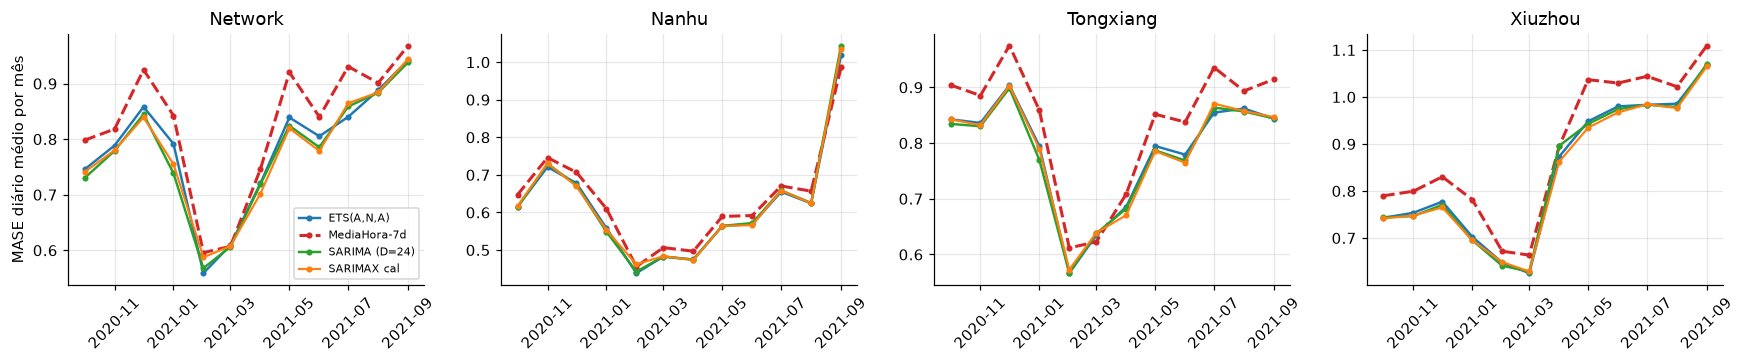

In [34]:
BEST_STAT = {lv: FINAL[lv] for lv in LEVELS}
sel = sorted(set(BEST_STAT.values()) | {"ETS(A,N,A)", "MediaHora-7d"})
print("Modelos mostrados:", sel)
STY = {"MediaHora-7d": dict(color="#D62728", ls="--", lw=2), "ETS(A,N,A)": dict(color="#1F77B4", lw=1.6),
       "SARIMA (D=24)": dict(color="#2CA02C", lw=1.6), "SARIMAX cal": dict(color="#FF7F0E", lw=1.4),
       "SARIMAX cal+meteo D-1": dict(color="#9467BD", lw=1.4)}
plot_by_horizon(sel, styles=STY, title="MASE por horizonte (média dos 4 folds): melhores modelos estatísticos")

rows = []
for n in sorted(set(sel) - {"MediaHora-7d"}):
    for lv in LEVELS:
        a = RESULTS[n]["res_h"].query("level == @lv").groupby("horizon")["MASE"].mean()
        b = RESULTS["MediaHora-7d"]["res_h"].query("level == @lv").groupby("horizon")["MASE"].mean()
        d = a - b
        rows.append({"modelo": n, "nível": lv, "Δ MASE h=1-6": d.loc[1:6].mean(), "Δ MASE h=7-24": d.loc[7:24].mean(), "horizontes em que ganha": int((d < 0).sum())})
display(pd.DataFrame(rows).set_index(["modelo", "nível"]).round(3))

peaks = global_tbl[global_tbl.model.isin(sel)].pivot(index="model", columns="level", values=["pico_acerto", "pico_MAE"])
display(peaks.reindex(columns=pd.MultiIndex.from_product([["pico_acerto", "pico_MAE"], LEVELS])).round(3))

print("Estabilidade temporal: MASE por fold dos modelos selecionados")
display(fold_table(sel).round(3))

# MASE por mês de validação (Rede) para ver a deriva ao longo do tempo
fig, ax = plt.subplots(1, 4, figsize=(16, 3.4), sharex=True)
for a, lv in zip(ax, LEVELS):
    for n in sel:
        rd = RESULTS[n]["res_d"].query("level == @lv")
        s = rd.groupby(rd["day"].dt.to_period("M"))["MASE_dia"].mean()
        a.plot(s.index.to_timestamp(), s.values, marker="o", ms=3, label=n, **STY.get(n, {}))
    a.set(title=lv)
    a.tick_params(axis="x", rotation=45)
ax[0].set_ylabel("MASE diário médio por mês")
ax[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

**Leitura (horizonte, estabilidade e picos).**

- **Por horizonte:** o erro relativo é baixo de madrugada (cerca de 0,3 a 0,6 de MASE entre h=2 e h=8) e alto a meio do dia (acima de 1 entre h=12 e h=20 na Rede, Tongxiang e Xiuzhou; Nanhu chega a cerca de 1,0). É o efeito, já anunciado na Task 1, de o horizonte coincidir com a hora do dia: as horas de maior procura são as mais difíceis. O SARIMA (D=24) ganha à referência em 24 dos 24 horizontes na Rede, em Tongxiang e em Xiuzhou, e em 19 em Nanhu. O ganho é maior durante o dia (−0,053 a −0,064 de MASE entre h=7 e h=24) do que de madrugada (−0,03 a −0,04), exceto em Nanhu (−0,024 e −0,009).
- **Estabilidade entre *folds*:** os modelos selecionados ganham à referência nos 4 *folds* em todos os níveis. O F2 (2021-Q1) é o mais fácil em todos os níveis. O F4 (2021-Q3) é o mais difícil na Rede, em Nanhu e em Xiuzhou (em Tongxiang, F1 e F4 são equivalentes), tal como nas *baselines*.
- **Estabilidade ao longo do tempo (gráfico mensal):** a ordem relativa dos modelos mantém-se mês a mês. O MASE diminui em fevereiro e março de 2021 e sobe a partir de abril. Em **Nanhu, setembro de 2021 dispara em todos os modelos, incluindo a referência** (cerca de 1,0). Nanhu passou de cerca de 92 sessões por dia em julho e agosto para cerca de 152 em setembro, e como os modelos se ajustam devagar ($\alpha$ pequeno), erram mais durante a subida. É um problema de dados, e não de um modelo.
- **Picos:** nenhum modelo estatístico acerta melhor o **valor** do pico do que a MédiaHora-7d (erro absoluto do pico: 9,9 a 10,0 na Rede contra 8,7), embora acertem um pouco mais a **hora** do pico (52% a 53% contra 50% na Rede). A previsão em `log1p` e a atualização suave achatam os máximos. É a limitação operacional mais importante destes modelos para o dimensionamento da capacidade em hora de ponta.

In [35]:
# Coerência entre níveis: a soma das previsões dos distritos (bottom-up) vs. previsão direta da rede
rows = []
for n in sorted(set(BEST_STAT.values()) | {"ETS(A,N,A)", "MediaHora-7d", "SARIMA (D=24)"}):
    p = RESULTS[n]["preds"]
    keys = ["fold", "timestamp"]
    net = p[p.level == "Network"].set_index(keys)
    bu = p[p.level.isin(DISTRICTS)].groupby(keys)["y_pred"].sum()
    d = pd.DataFrame({"y_true": net["y_true"], "direta": net["y_pred"], "bottom-up": bu}).reset_index()
    for lab in ["direta", "bottom-up"]:
        r = {"modelo": n, "rede obtida por": lab}
        maes = []
        for f in FOLDS:
            s = d[d.fold == f["name"]]
            maes.append(np.abs(s["y_true"] - s[lab]).mean() / SCALES[("Network", f["name"])])
        r["MASE"] = np.mean(maes)
        r["viés médio"] = (d[lab] - d["y_true"]).mean()
        rows.append(r)
display(pd.DataFrame(rows).set_index(["modelo", "rede obtida por"]).round(3))

MASE  viés médio
modelo        rede obtida por                  
ETS(A,N,A)    direta          0.783      -0.760
              bottom-up       0.792      -1.896
MediaHora-7d  direta          0.825      -0.166
              bottom-up       0.825      -0.166
SARIMA (D=24) direta          0.774      -1.042
              bottom-up       0.793      -2.148
SARIMAX cal   direta          0.776      -0.995
              bottom-up       0.792      -2.032

**Leitura (coerência entre níveis).** A previsão direta da Rede tem MASE de 0,774 a 0,783 e uma subestimação média de 0,8 a 1,0 sessões por hora. A soma das previsões dos distritos (bottom-up) é **pior** (MASE de 0,79) e subestima o dobro (−1,9 a −2,1 sessões por hora), porque o viés negativo da previsão da mediana em `log1p` se acumula em cada distrito. Para a Rede, a previsão direta é preferível. A MédiaHora-7d não tem esta diferença porque é aditiva. Fica registado que as previsões dos distritos não somam à da Rede (previsão independente por nível, como no protocolo), e uma reconciliação seria um possível trabalho futuro.

In [36]:
ct = summarize(STAT_MODELS, with_rule=False).pivot(index="model", columns="level", values="ajuste_s")[LEVELS]
cp = summarize(STAT_MODELS, with_rule=False).pivot(index="model", columns="level", values="ms_origem")[LEVELS]
cost = pd.concat({"ajuste por fold (s)": ct, "previsão por origem (ms)": cp}, axis=1).loc[STAT_MODELS]
display(cost.round(2))

ajuste por fold (s)                          previsão por origem (ms)                         
level                                     Network  Nanhu Tongxiang Xiuzhou                  Network  Nanhu Tongxiang Xiuzhou
model                                                                                                                       
SNaive-24                                   0.000  0.000     0.000   0.000                    0.000  0.000     0.000   0.000
MediaHora-7d                                0.000  0.000     0.000   0.000                    0.010  0.010     0.010   0.010
ETS(A,N,A)                                  0.010  0.020     0.030   0.030                   11.710 11.600    11.490   8.070
ETS(A,N,A) m=168                            0.060  0.110     0.110   0.040                   51.770 51.470    51.230  19.020
MSTL + ETS (4 sem)                          1.460  1.470     1.430   1.190                    1.780  1.880     1.840   1.480
ARIMA(2,1,2) sem sazonalidade               0.990  1.940     0.690   1.500                    1.920  1.900     2.050   1.880
SARIMA (D=24)                               8.480  9.610     9.560  11.600                    3.950  3.480     3.420   2.440
SARIMA (D=168)                              5.800  5.640     9.490   5.940                    3.440  3.360     3.140   2.750
SARIMA (D=24 e 168)                        20.080 14.780    11.980  20.830                    4.410  5.070     5.730   3.700
MSTL + ARIMA d=0                            8.260  8.490     7.580   6.900                    2.310  2.160     2.300   1.600
MSTL + ARIMA d=1                            3.670  2.890     2.820   2.490                    1.540  1.650     1.810   1.330
SARIMAX cal                                35.830 37.880    41.530  52.980                    7.930  7.420     7.380   4.680
SARIMAX cal+meteo D-1                      58.510 69.840    84.520  88.570                    8.610  8.280     7.780   5.740
SARIMAX cal+meteo D-2                      67.500 64.600    87.190  90.650                    8.440  8.630     7.580   5.990

**Leitura (custo).** O ajuste do ETS custa milissegundos por *fold*, o do SARIMA entre 8 e 12 s, e o do SARIMAX entre 34 e 90 s (os mais lentos são os que têm meteorologia). Em previsão, todos ficam em cerca de 10 ms ou menos por dia, e o tempo total de uma previsão day-ahead é desprezável. No treino, os 4 *folds* × 4 níveis do SARIMAX com calendário levam cerca de 100 s em paralelo em 12 núcleos, e poucos segundos no ETS. O custo adicional dos modelos mais complexos não se justifica pelo ganho observado.

## 8. Discussão transversal

**Como os modelos captam as características da série.**

| Característica | ETS(A,N,A) | SARIMA (D=24) | SARIMAX |
|---|---|---|---|
| **Dependência temporal** | o nível suaviza o passado ($\alpha\approx0{,}02$ a $0{,}06$) | ARMA de curto prazo mais MA sazonal (média ponderada de dias anteriores) | igual ao SARIMA |
| **Tendência** | $\beta\approx 0$: não existe à escala horária (o nível já a acompanha) | não é necessária ($d=0$ depois de $D=1$) | igual |
| **Sazonalidade diária (24 h)** | $\gamma$ atualiza o perfil horário ao longo de semanas | MA sazonal em 24 h, perfil diferenciado e atualizado todos os dias | igual |
| **Sazonalidade semanal (168 h)** | não (só com $m=168$, que piora) | não (diferenciação a 168 h piora muito) | só através do indicador de fim de semana |
| **Influências externas** | não | não | feriados, vésperas e fim de semana (calendário); meteorologia sem valor |

**Dupla sazonalidade.** A Task 1 identificou um ciclo diário forte e um semanal fraco (força de cerca de 0,18). Testaram-se cinco formas de os representar: ETS com $m=168$, MSTL + ETS, SARIMA com $D=168$, SARIMA com dupla diferenciação e MSTL + ARIMA. **Nenhuma superou o modelo apenas diário.** As limitações são estruturais: o ETS e o SARIMA do `statsmodels` só admitem um período sazonal; usar $m=168$ ou $D=168$ faz cada fator ser atualizado só uma vez por semana e acumula ruído de duas semanas; e as decomposições (MSTL) fixam os ciclos no treino e sobreajustam. Para este problema, a sazonalidade semanal é melhor tratada por regressores (SARIMAX) ou por modelos com atributos de calendário (Task 3).

**Principais limitações dos modelos estatísticos.**

1. **Picos achatados:** o erro do valor do pico é maior do que o da referência, por causa da previsão da mediana em `log1p` e da suavização. Um modelo que subestima os picos não serve para dimensionar capacidade máxima.
2. **Subestimação do volume** (−0,8 a −1,0 sessões por hora na Rede), pelo mesmo motivo. A correção de enviesamento foi testada na secção 2.3 e piorou o MAE e o MASE.
3. **Feriados e dias atípicos:** melhoram com o SARIMA, mas continuam a ser os dias mais difíceis (MASE de 0,82 a 0,87 na Rede contra 0,77 nos dias úteis).
4. **Mudanças de nível súbitas** (Nanhu em setembro de 2021): os modelos reagem devagar, como todos os que têm um parâmetro de suavização pequeno.
5. **Meteorologia:** o ficheiro só tem um valor por distrito e por dia, e não ajudou, nem com informação perfeita. Previsões meteorológicas horárias, se existissem arquivadas, seriam o teste justo.
6. **Resíduos:** ficam quase sem autocorrelação sazonal, mas mantêm caudas pesadas e uma pequena autocorrelação em 1 h, pelo que os intervalos de previsão baseados na normal não são fiáveis.

**Resposta parcial à pergunta geral do projeto (nível estatístico).** Com histórico de procura e calendário, os modelos estatísticos conseguem prever as 24 h seguintes com um erro de 3,5% a 7% (MASE) abaixo da melhor referência simples, nos quatro níveis, de forma estável em 4 trimestres, mas sem melhorar o valor do pico. O erro relativo é maior nas horas de maior procura e em dias de feriado. O ganho de modelos mais complexos sobre o ETS(A,N,A) é pequeno (menos de 0,01 de MASE), o que sugere que a margem restante tem de vir de informação que estes modelos não usam (Task 3).

## 9. Síntese

### 9.1 Exportação dos resultados

Guardam-se em `task2_outputs/` a seleção final por nível (`task2_final_selection.json`), as previsões de validação de cada modelo no formato comum e a tabela completa de métricas (`summary_task2_all.csv`), para que a Task 3 compare os modelos de aprendizagem automática exatamente com os mesmos números e as mesmas origens. O teste continua por usar: o modelo e os hiperparâmetros ficam congelados aqui, e serão avaliados uma única vez no fim.

In [37]:
FINAL_SEL = {"selection_scope": "melhor modelo estatístico por nível pela regra do protocolo (só validação; teste não usado)",
             "per_level": {lv: FINAL[lv] for lv in LEVELS},
             "decisions": TASK2_DECISIONS,
             "sarima_orders": {lv: {"order": list(BEST_ORD[lv][0]), "seasonal_ARMA(P,Q)_24": list(BEST_ORD[lv][1])} for lv in LEVELS},
             "mstl_arima_orders": {f"d={d}": {lv: list(MSTL_ORD[d][lv]) for lv in LEVELS} for d in (0, 1)}}
(OUT_DIR / "task2_final_selection.json").write_text(json.dumps(FINAL_SEL, indent=2, ensure_ascii=False), encoding="utf-8")
for n in STAT_MODELS + [m for m in S6_SET if m not in STAT_MODELS] + ["SARIMA AICc", "SARIMA BIC"]:
    RESULTS[n]["preds"].to_csv(OUT_DIR / f"preds_task2_{slug(n)}.csv", index=False)
all_models = list(dict.fromkeys(STAT_MODELS + S6_SET))
summarize(all_models).to_csv(OUT_DIR / "summary_task2_all.csv", index=False)
pd.concat([RESULTS[n]["res_f"][["model", "level", "fold", "fit_s", "ms_per_origin"]] for n in all_models], ignore_index=True).to_csv(OUT_DIR / "fit_times_task2.csv", index=False)
display(pd.Series(FINAL_SEL["per_level"]).to_frame("modelo estatístico selecionado"))

,modelo estatístico selecionado
Network,SARIMA (D=24)
Nanhu,"ETS(A,N,A)"
Tongxiang,SARIMA (D=24)
Xiuzhou,SARIMAX cal


### 9.2 Conclusões da Task 2

**Base comum**

- O motor de avaliação reproduz exatamente as *baselines* da Task 1 e garante por construção que nenhum modelo vê o dia previsto nem o teste.
- Decisões fixadas: série em `log1p`, parâmetros estimados desde 2020-04-01, previsão como mediana cortada a zero.

**Modelos selecionados por nível** (MASE médio nos 4 *folds* de validação)

| Nível | Modelo selecionado | MASE | MédiaHora-7d | Redução |
|---|---|---|---|---|
| Rede | SARIMA (1,0,1)(1,0,1)$_{24}$, D=24 | 0,774 | 0,825 | 6,2% |
| Nanhu | ETS(A,N,A), $m=24$ | 0,616 | 0,639 | 3,6% |
| Tongxiang | SARIMA (1,0,1)(1,0,1)$_{24}$, D=24 | 0,779 | 0,834 | 6,6% |
| Xiuzhou | SARIMAX, calendário, ordem (1,0,3)(0,0,1)$_{24}$ | 0,835 | 0,890 | 6,2% |

Cada modelo cumpre a regra de seleção do protocolo: melhor MASE médio, melhor em pelo menos 3 de 4 *folds* (4 em todos exceto Nanhu) e IC 95% da diferença pareada face à referência a excluir zero.

**O que se aprendeu**

1. **Quase todo o ganho vem de modelar bem o ciclo diário** e atualizá-lo continuamente (ETS ou SARIMA com MA sazonal). A transformação `log1p` foi a decisão mais importante da Task. Sem ela, o ETS nem batia a referência na Rede.
2. **Tendência:** inexistente à escala horária. **Ciclo semanal:** fraco, e todas as tentativas de o modelar dentro do modelo (m=168, D=168, dupla diferenciação, MSTL) pioraram o resultado.
3. **Calendário (feriados, vésperas, fim de semana):** coeficientes estáveis e com sentido, mas só melhora o erro de forma clara em Xiuzhou. **Meteorologia:** sem valor (pior com atraso de 1 dia, indistinguível com 2 dias e pior com o oráculo).
4. **Resíduos:** quase sem autocorrelação sazonal, mas com caudas pesadas e uma pequena autocorrelação em 1 h.
5. **Estabilidade:** ordem relativa dos modelos estável nos 4 trimestres; F2 o mais fácil e F4 o mais difícil (exceto em Tongxiang, onde F1 e F4 são equivalentes); todos os modelos são afetados pelo salto de nível de Nanhu em setembro de 2021.
6. **Limitação principal:** os modelos subestimam o valor do pico e o volume total, o que importa para o dimensionamento de capacidade.

**Ponto de partida para a Task 3.** A fasquia estatística por nível é a tabela acima, com a MédiaHora-7d como referência do protocolo. Os modelos de aprendizagem automática têm de a superar nas mesmas origens e com as mesmas métricas, e é onde se pode ganhar nos picos e nos feriados, através de atributos de calendário, *lags* e agregados por distrito.